# Driving v2 · Rung 1: does the network work when it can see the dot?

**Question:** if the network is told where the dot is *relative to the robot*, can it copy the expert's wheel commands?

This is an **oracle** test. The dot's position comes from the simulator, not from a sensor. Later, a camera replaces it. If this rung fails, a camera will not help.

**One change at a time.** Three models, same network, same data, same training. Only the inputs differ:

| Model | Inputs |
|---|---|
| `wheels` | 12 wheel features (angles, speeds, summaries) |
| `wheels+start_dot` | + sin/cos of the dot's direction **at the start** (the old setup) |
| `wheels+live_dot` | + distance and sin/cos of the dot's direction **relative to the robot, every step** |

**Outputs (the expert's):** four wheel-velocity commands + PARK.
Arm torques are not in this dataset (it was collected driving-only), so they come later.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DATA = Path('../driving_30/data/expert_30hz')
records = [json.loads(line) for line in open(DATA / 'episodes.jsonl')]
split_of = {p['bearing_deg']: p['split'] for p in json.loads((DATA / 'split_plan.json').read_text())}

# Repeated runs are byte-identical: keep one trajectory per unique hash.
unique = {}
for r in records:
    unique.setdefault(r['trajectory_hash'], r)
episodes = sorted(unique.values(), key=lambda r: r['bearing_deg'])
print(f'{len(records)} executions -> {len(episodes)} unique trajectories')
print(pd.Series([split_of[r["bearing_deg"]] for r in episodes]).value_counts().to_dict())

1500 executions -> 30 unique trajectories
{'train': 21, 'holdout': 5, 'test': 4}


### Build the inputs

`base_pose` is the simulator's true robot pose: x, y, z, then a quaternion (x, y, z, w). It is used **only** to compute the oracle dot features. It is not given to the network.

Live dot features at each step:
- `dot_distance_m`: horizontal distance from the robot to the dot
- `dot_sin`, `dot_cos`: direction of the dot, measured from where the robot is facing

In [2]:
WHEEL = list(range(12))      # first 12 columns of the saved x: wheel features
START_DOT = [12, 13]         # saved sin/cos of the initial bearing

def yaw(q):                  # quaternion (x, y, z, w) -> heading in radians
    x, y, z, w = q.T
    return np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))

def live_dot(pose, target):
    dx, dy = target[0] - pose[:, 0], target[1] - pose[:, 1]
    angle = np.arctan2(dy, dx) - yaw(pose[:, 3:7])
    return np.c_[np.hypot(dx, dy), np.sin(angle), np.cos(angle)].astype(np.float32)

rows = []
for r in episodes:
    with np.load(DATA / r['archive']) as a:
        target = np.array(r['manifest']['target_position_world_m'])
        rows.append(dict(bearing=r['bearing_deg'], split=split_of[r['bearing_deg']],
                         x=a['x'], live=live_dot(a['base_pose'], target),
                         wheels=a['wheels'], park=a['park'].ravel()))

INPUTS = {
    'wheels':           lambda e: e['x'][:, WHEEL],
    'wheels+start_dot': lambda e: e['x'][:, WHEEL + START_DOT],
    'wheels+live_dot':  lambda e: np.c_[e['x'][:, WHEEL], e['live']],
}
e = rows[0]
print('Bearing', e['bearing'], '| rows', len(e['x']))
pd.DataFrame(e['live'], columns=['dot_distance_m', 'dot_sin', 'dot_cos']).iloc[[0, 10, 30, -1]].round(3)

Bearing 12 | rows 96


,dot_distance_m,dot_sin,dot_cos
0,1.100,0.208,0.978
10,1.102,0.083,0.997
30,1.003,0.014,1.000
95,0.707,0.014,1.000


### Collision check at t = 0

Every run starts at rest. Do the inputs at t = 0 differ between bearings? If they don't, the network can't tell the runs apart, but the expert's first command still differs.

In [3]:
for name, f in INPUTS.items():
    first = np.array([f(e)[0] for e in rows]).round(6)
    print(f'{name:18s} distinct t=0 inputs: {len(np.unique(first, axis=0)):2d} of {len(rows)} bearings')
first_cmd = np.array([e['wheels'][0] for e in rows]).round(3)
print(f'{"expert":18s} distinct t=0 commands: {len(np.unique(first_cmd, axis=0)):2d} of {len(rows)} bearings')

wheels             distinct t=0 inputs:  1 of 30 bearings
wheels+start_dot   distinct t=0 inputs: 30 of 30 bearings
wheels+live_dot    distinct t=0 inputs: 30 of 30 bearings
expert             distinct t=0 commands:  5 of 30 bearings


### Prediction, written before training

- `wheels`: poor everywhere. It can't tell the bearings apart.
- `wheels+start_dot`: much better than `wheels`.
- `wheels+live_dot`: best, especially on test bearings, because the dot direction stays current after the robot turns.

These are **offline** scores on the expert's own states. They don't yet show the robot driving.

In [4]:
SEED, EPOCHS, LR, PARK_WEIGHT = 7, 300, 0.01, 0.1
torch.set_num_threads(1)

class Policy(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
        self.wheels = nn.Linear(16, 4)
        self.park = nn.Linear(16, 1)
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h), self.park(h).squeeze(1)

def stack(eps, f):
    X = torch.from_numpy(np.concatenate([f(e) for e in eps]).astype(np.float32))
    W = torch.from_numpy(np.concatenate([e['wheels'] for e in eps]).astype(np.float32))
    P = torch.from_numpy(np.concatenate([e['park'] for e in eps]).astype(np.float32))
    # each trajectory counts equally, whatever its length
    w = torch.from_numpy(np.concatenate([np.full(len(e['x']), 1 / (len(e['x']) * len(eps))) for e in eps]).astype(np.float32))
    return X, W, P, w

def loss_fn(model, X, W, P, w, pos_weight):
    pw, pl = model(X)
    wheel_mse = (w * ((pw - W) ** 2).mean(1)).sum()
    park_bce = F.binary_cross_entropy_with_logits(pl, P, pos_weight=pos_weight)
    return wheel_mse + PARK_WEIGHT * park_bce, wheel_mse, park_bce

train = [e for e in rows if e['split'] == 'train']
test = [e for e in rows if e['split'] == 'test']      # holdout stays untouched
models, history = {}, []
for name, f in INPUTS.items():
    torch.manual_seed(SEED)
    Xtr, Wtr, Ptr, wtr = stack(train, f)
    Xte, Wte, Pte, wte = stack(test, f)
    pos_weight = (len(Ptr) - Ptr.sum()) / Ptr.sum()     # from training data only
    model = Policy(Xtr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for epoch in range(EPOCHS + 1):
        model.train()
        total, wm, pb = loss_fn(model, Xtr, Wtr, Ptr, wtr, pos_weight)
        with torch.no_grad():
            _, te_wm, _ = loss_fn(model, Xte, Wte, Pte, wte, pos_weight)
        history.append(dict(model=name, epoch=epoch, train_wheel_mse=wm.item(), test_wheel_mse=te_wm.item(), train_park_bce=pb.item()))
        if epoch < EPOCHS:
            opt.zero_grad(); total.backward(); opt.step()
    models[name] = model
    print(f'{name:18s} inputs={Xtr.shape[1]:2d}  train rows={len(Xtr)}  final train wheel MSE={wm.item():.4f}  test={te_wm.item():.4f}')
history = pd.DataFrame(history)
Path('models').mkdir(exist_ok=True)
for name, m in models.items():
    torch.save(m.state_dict(), f'models/rung1_{name.replace("+", "_")}.pt')

wheels             inputs=12  train rows=2965  final train wheel MSE=0.0704  test=0.0773


wheels+start_dot   inputs=14  train rows=2965  final train wheel MSE=0.0460  test=0.0416


wheels+live_dot    inputs=15  train rows=2965  final train wheel MSE=0.0342  test=0.0326


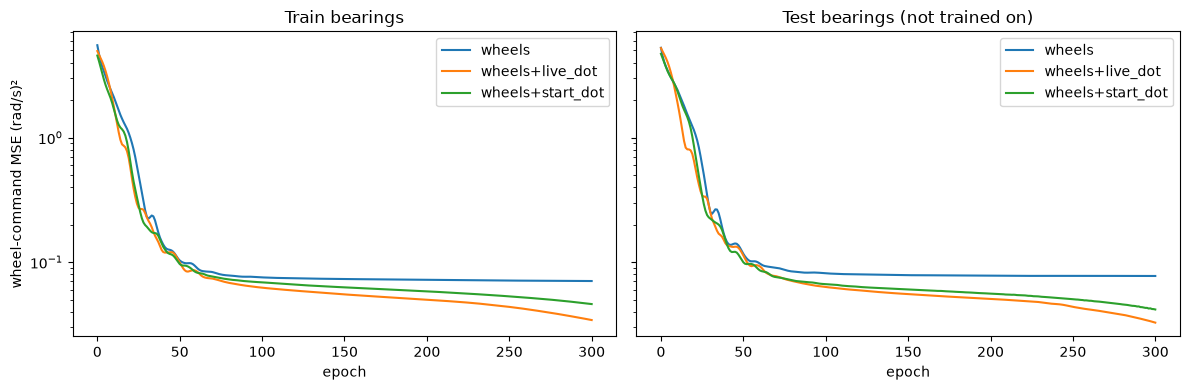

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, h in history.groupby('model'):
    ax[0].plot(h.epoch, h.train_wheel_mse, label=name)
    ax[1].plot(h.epoch, h.test_wheel_mse, label=name)
for a, t in zip(ax, ['Train bearings', 'Test bearings (not trained on)']):
    a.set(title=t, xlabel='epoch', yscale='log'); a.legend()
ax[0].set_ylabel('wheel-command MSE (rad/s)²')
plt.tight_layout(); plt.show()
# Test is plotted for inspection only; it does not choose the epoch (fixed at 300).

### Offline results

Per trajectory, then averaged. `n` is the number of bearings. Baseline: always command zero.

PARK: **hit** = predicted PARK on the expert's PARK row; **early rows** = rows predicted PARK before the expert parked.

In [6]:
def evaluate(model, f, eps):
    out = []
    for e in eps:
        with torch.no_grad():
            pw, pl = model(torch.from_numpy(f(e).astype(np.float32)))
        pw, prob = pw.numpy(), torch.sigmoid(pl).numpy()
        out.append(dict(bearing=e['bearing'], wheel_mae=np.abs(pw - e['wheels']).mean(),
                        zero_baseline_mae=np.abs(e['wheels']).mean(),
                        park_hit=bool(prob[-1] >= 0.5), early_park_rows=int((prob[:-1] >= 0.5).sum())))
    return pd.DataFrame(out)

results = []
for name, f in INPUTS.items():
    for split, eps in [('train', train), ('test', test)]:
        r = evaluate(models[name], f, eps).assign(model=name, split=split)
        results.append(r)
results = pd.concat(results)
summary = results.groupby(['split', 'model'], sort=False).agg(
    n=('bearing', 'size'), wheel_MAE=('wheel_mae', 'mean'), zero_baseline_MAE=('zero_baseline_mae', 'mean'),
    park_hits=('park_hit', 'sum'), early_park_rows=('early_park_rows', 'sum'))
summary.round(3)

,,n,wheel_MAE,zero_baseline_MAE,park_hits,early_park_rows
split,model,,,,,
train,wheels,21,0.087,1.995,21,100
test,wheels,4,0.086,2.040,4,19
train,wheels+start_dot,21,0.096,1.995,21,101
test,wheels+start_dot,4,0.095,2.040,4,21
train,wheels+live_dot,21,0.095,1.995,21,96
test,wheels+live_dot,4,0.097,2.040,4,19


### Test bearings, worst first

In [7]:
results[results.split == 'test'].pivot(index='bearing', columns='model', values='wheel_mae').round(3).sort_values('wheels+live_dot', ascending=False)

model,wheels,wheels+live_dot,wheels+start_dot
bearing,,,
24,0.103,0.106,0.111
132,0.083,0.102,0.097
108,0.084,0.095,0.088
204,0.075,0.088,0.085


### What this does **not** show

- **Offline only.** Scores use the expert's own states. The real test is closed-loop: the network drives, and its errors change what it sees next.
- **Oracle input.** The live dot comes from the simulator's true pose. A camera will replace it in rung 2.
- **No arm torques.** This dataset is driving-only.
- **Small n.** 21 training and 4 test bearings, one seed. The 4 test bearings were seen in earlier experiments. The 5 holdout bearings are not used here.
- **One copy of each trajectory.** The dataset repeats each of the 30 trajectories; repeats are identical and are dropped.

## Closed loop: the network drives the robot

Each model now drives the robot in the fast native PyBullet build (`comp0245-native-expert/build-clang19/policy_replay`), the same engine that collected the data. Headless, 1 kHz physics, 30 Hz decisions. The arm is held in its start pose.

For each of the 25 train and test bearings, the expert runs once and each model runs once from the same start:
- the expert runs until its PARK, then 0.5 s of drift;
- the model has until **expert PARK + 3 s** to issue its own PARK (probability ≥ 0.5, latched), then 0.5 s of drift.

The 5 holdout bearings are not run.

**Errors compare the model's base with the expert's base**: position (m) and heading (degrees), at PARK and at the end.

This cell reads saved rollouts. It doesn't run physics.

In [8]:
import replay_v2
closed = []
for name in ['wheels', 'wheels+start_dot', 'wheels+live_dot']:
    _, m, diff = replay_v2.load(name)
    closed.append(m)
    print(f'{name:18s} max NumPy vs native prediction difference: {diff:.1e}')
closed = pd.concat(closed)
closed.groupby(['split', 'model'], sort=False).agg(
    n=('bearing_deg', 'size'), parked=('parked', 'sum'),
    park_xy_error_m=('park_xy_error_m', 'mean'), park_yaw_error_deg=('park_yaw_error_deg', 'mean'),
    final_xy_error_m=('final_xy_error_m', 'mean'), final_yaw_error_deg=('final_yaw_error_deg', 'mean')).round(3)

wheels             max NumPy vs native prediction difference: 7.2e-07


wheels+start_dot   max NumPy vs native prediction difference: 1.8e-06


wheels+live_dot    max NumPy vs native prediction difference: 1.2e-06


,,n,parked,park_xy_error_m,park_yaw_error_deg,final_xy_error_m,final_yaw_error_deg
split,model,,,,,,
train,wheels,21,9,0.287,38.143,0.447,89.919
test,wheels,4,3,0.421,40.923,0.473,71.182
train,wheels+start_dot,21,10,0.275,43.575,0.361,74.568
test,wheels+start_dot,4,1,0.037,4.078,0.246,117.384
train,wheels+live_dot,21,19,0.153,14.917,0.182,18.577
test,wheels+live_dot,4,4,0.121,12.204,0.127,12.484


### Every bearing: final position error (m), worst first for the live-dot model

In [9]:
closed.pivot_table(index=['split', 'bearing_deg'], columns='model', values='final_xy_error_m').round(2)\
      .sort_values('wheels+live_dot', ascending=False)

model              wheels  wheels+live_dot  wheels+start_dot
split bearing_deg                                           
train 168            0.37             0.43              0.48
      156            0.45             0.30              0.34
      180            0.17             0.26              0.53
      192            0.06             0.23              0.21
test  204            0.03             0.20              0.39
train 216            0.12             0.18              0.34
      300            0.57             0.18              0.67
      288            0.53             0.18              0.79
      228            0.22             0.18              0.47
      312            0.58             0.17              0.51
      12             0.52             0.17              0.07
      264            0.41             0.17              0.85
      240            0.29             0.17              0.51
      252            0.36             0.16              0.52
test  24             0.58             0.16              0.04
train 84             0.69             0.16              0.20
      72             0.73             0.16              0.24
      36             0.65             0.16              0.06
      60             0.74             0.14              0.17
      336            0.53             0.14              0.09
      360            0.24             0.11              0.10
      348            0.51             0.10              0.10
test  108            0.68             0.08              0.27
train 120            0.65             0.07              0.32
test  132            0.59             0.07              0.28

## 3D replay: model vs ghost expert

Solid robot: the model. Cyan ghost: the expert. Use **Previous / Next** or the dropdown to change bearing, and Play, Pause, Restart or the timeline to move through the run. One player per model.

### `wheels+live_dot` (oracle dot, every step)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_live_dot.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [10]:
from IPython.display import IFrame, HTML
import uuid

def lazy_player(url, height=810):
    """A 3D player that loads only when its button is pressed. Browsers keep only about 16 3D views (WebGL
    contexts) at once, so loading every player in the notebook together leaves some of them blank."""
    k = uuid.uuid4().hex[:8]
    return HTML(f"""<div><button onclick="var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'"
 style="padding:8px 14px;font-size:14px">Load the 3D player</button>
<iframe id="player{k}" style="display:none;width:100%;height:{height}px;border:0"></iframe></div>""")

def player(name):
    path = replay_v2.build_viewer(name)
    return lazy_player('/files/driving_v2/closed_loop_native/' + path.name)
player('wheels+live_dot')

### `wheels+start_dot` (dot direction at the start only)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_start_dot.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [11]:
player('wheels+start_dot')

### `wheels` (no dot)

<a href="/files/driving_v2/closed_loop_native/viewer_wheels.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [12]:
player('wheels')

## Change 1: skid-steer output

**One change only.** The inputs (15, including the accumulated wheel angles and the live dot), data, loss, seed, epochs and PARK head are the same as `wheels+live_dot`.

The wheel head now predicts **2 numbers**: right-side and left-side speed. A fixed step copies them into the four wheels: `[front_right, front_left, back_left, back_right] = [right, left, left, right]`. The output is still four wheel-velocity commands, like the expert's.

**Why:** the expert always gives both wheels on a side the same command (checked below). With four free outputs, the network can make small left/right mismatches the expert never makes, and that wastes effort fighting the skid steering.

**Prediction:** small offline change. In closed loop, a modest drop in heading error. Not a big jump, because the main problem is probably recovery from drift (change 2).

In [13]:
labels = np.concatenate([e['wheels'] for e in rows])
print('Expert |front_right - back_right| max:', np.abs(labels[:, 0] - labels[:, 3]).max())
print('Expert |front_left  - back_left|  max:', np.abs(labels[:, 1] - labels[:, 2]).max())

Expert |front_right - back_right| max: 0.0
Expert |front_left  - back_left|  max: 0.0


In [14]:
# [right, left] -> [front_right, front_left, back_left, back_right]
SKID = torch.tensor([[1., 0.], [0., 1.], [0., 1.], [1., 0.]])

class SkidPolicy(Policy):
    def __init__(self, n_in):
        super().__init__(n_in)
        self.wheels = nn.Linear(16, 2)          # right, left
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h) @ SKID.T, self.park(h).squeeze(1)

name, f = 'wheels+live_dot+skid', INPUTS['wheels+live_dot']
torch.manual_seed(SEED)
Xtr, Wtr, Ptr, wtr = stack(train, f); Xte, Wte, Pte, wte = stack(test, f)
pos_weight = (len(Ptr) - Ptr.sum()) / Ptr.sum()
model = SkidPolicy(Xtr.shape[1]); opt = torch.optim.Adam(model.parameters(), lr=LR)
for epoch in range(EPOCHS + 1):
    total, wm, pb = loss_fn(model, Xtr, Wtr, Ptr, wtr, pos_weight)
    with torch.no_grad():
        _, te_wm, _ = loss_fn(model, Xte, Wte, Pte, wte, pos_weight)
    history = pd.concat([history, pd.DataFrame([dict(model=name, epoch=epoch, train_wheel_mse=wm.item(),
                         test_wheel_mse=te_wm.item(), train_park_bce=pb.item())])], ignore_index=True)
    if epoch < EPOCHS:
        opt.zero_grad(); total.backward(); opt.step()
models[name] = model
print(f'{name}: final train wheel MSE={wm.item():.4f}  test={te_wm.item():.4f}')
print('Parameters:', sum(p.numel() for p in model.parameters()), 'vs', sum(p.numel() for p in models['wheels+live_dot'].parameters()))

# Fold the copy step into an ordinary 4-output layer: identical outputs, so the native replay runs it unchanged.
sd = {k: v.detach() for k, v in model.state_dict().items()}
sd['wheels.weight'], sd['wheels.bias'] = SKID @ sd['wheels.weight'], SKID @ sd['wheels.bias']
folded = Policy(Xtr.shape[1]); folded.load_state_dict(sd)
with torch.no_grad():
    print('Folded vs skid model, max output difference:', (folded(Xte)[0] - model(Xte)[0]).abs().max().item())
torch.save(model.state_dict(), 'models/rung1_wheels_live_dot_skid.pt')
np.savez('models/rung1_wheels_live_dot_skid.npz', **{k: v.numpy() for k, v in sd.items()})

wheels+live_dot+skid: final train wheel MSE=0.0341  test=0.0416
Parameters: 579 vs 613
Folded vs skid model, max output difference: 0.0


In [15]:
r = pd.concat([evaluate(models[m], INPUTS['wheels+live_dot'], eps).assign(model=m, split=s)
               for m in ['wheels+live_dot', name] for s, eps in [('train', train), ('test', test)]])
r.groupby(['split', 'model'], sort=False).agg(n=('bearing', 'size'), wheel_MAE=('wheel_mae', 'mean'),
    park_hits=('park_hit', 'sum'), early_park_rows=('early_park_rows', 'sum')).round(3)

,,n,wheel_MAE,park_hits,early_park_rows
split,model,,,,
train,wheels+live_dot,21,0.095,21,96
test,wheels+live_dot,4,0.097,4,19
train,wheels+live_dot+skid,21,0.085,21,101
test,wheels+live_dot+skid,4,0.095,4,20


### Closed loop: skid output vs four free outputs

Same 25 bearings, same fast native engine, same rules as above. The first run takes about two minutes; after that the saved rollout is reused.

In [16]:
plan = json.loads((DATA / 'split_plan.json').read_text())
cases = [dict(target=p['target'], bearing_deg=p['bearing_deg'], split=p['split']) for p in plan if p['split'] in ('train', 'test')]
replay_v2.run_native(name, cases)
_, skid_closed, diff = replay_v2.load(name)
print(f'max NumPy vs native prediction difference: {diff:.1e}')
both = pd.concat([closed[closed.model == 'wheels+live_dot'], skid_closed])
both.groupby(['split', 'model'], sort=False).agg(
    n=('bearing_deg', 'size'), parked=('parked', 'sum'),
    park_xy_error_m=('park_xy_error_m', 'mean'), park_yaw_error_deg=('park_yaw_error_deg', 'mean'),
    final_xy_error_m=('final_xy_error_m', 'mean'), final_yaw_error_deg=('final_yaw_error_deg', 'mean')).round(3)

max NumPy vs native prediction difference: 1.2e-06


,,n,parked,park_xy_error_m,park_yaw_error_deg,final_xy_error_m,final_yaw_error_deg
split,model,,,,,,
train,wheels+live_dot,21,19,0.153,14.917,0.182,18.577
test,wheels+live_dot,4,4,0.121,12.204,0.127,12.484
train,wheels+live_dot+skid,21,8,0.093,12.947,0.158,60.261
test,wheels+live_dot+skid,4,1,0.097,8.486,0.247,15.516


In [17]:
both.pivot_table(index=['split', 'bearing_deg'], columns='model', values='final_xy_error_m').round(2)\
    .sort_values('wheels+live_dot+skid', ascending=False)

model              wheels+live_dot  wheels+live_dot+skid
split bearing_deg                                       
train 156                     0.30                  0.38
      120                     0.07                  0.36
test  132                     0.07                  0.36
      108                     0.08                  0.33
train 72                      0.16                  0.33
      84                      0.16                  0.32
      36                      0.16                  0.24
      60                      0.14                  0.21
      180                     0.26                  0.20
test  24                      0.16                  0.19
train 216                     0.18                  0.18
      228                     0.18                  0.14
      240                     0.17                  0.14
      288                     0.18                  0.14
      252                     0.16                  0.13
test  204                     0.20                  0.11
train 192                     0.23                  0.11
      12                      0.17                  0.08
      168                     0.43                  0.07
      348                     0.10                  0.07
      300                     0.18                  0.05
      312                     0.17                  0.05
      336                     0.14                  0.05
      264                     0.17                  0.03
      360                     0.11                  0.02

### 3D replay: `wheels+live_dot+skid`

<a href="/files/driving_v2/closed_loop_native/viewer_wheels_live_dot_skid.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [18]:
player('wheels+live_dot+skid')

## Camera check: 180° fisheye RGB-D on top of the hand

**Goal:** can one wrist camera replace the oracle dot? No training here: only rendering and a colour threshold.

**Camera** (code: `wrist_camera.py`):
- mounted on top of the hand near the finger roots: `(0, 0.045, -0.07)` m in the hand frame `robot_j2s7s300_end_effector`, about 0.76 m off the ground in the hold pose;
- faces along the fingers, which is robot-forward while the arm is held;
- 180° equidistant fisheye, 256 × 256, RGB + depth. It is built from five 90° cube-face renders.

**Robot and dot are unchanged** from `robotnik_arm_task.py`: no repainting; the dot is a red sphere with a 3 cm radius.

**Frames:** saved expert poses from the 30 runs, every 6th row (5 Hz), plus start, middle and park. No physics is stepped.

**Detection:**
1. Red pixels: `r > 100` and `r > 1.7 g` and `r > 1.7 b`.
2. Their centre gives the ray direction.
3. The median depth of those pixels, plus the 3 cm radius, gives the distance.
4. The camera's pose comes from the arm joint angles. That converts the estimate into distance and direction relative to the base, the same numbers as the oracle.

**Ground truth, for checking only:** PyBullet's segmentation mask says whether the dot is truly in view.

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0


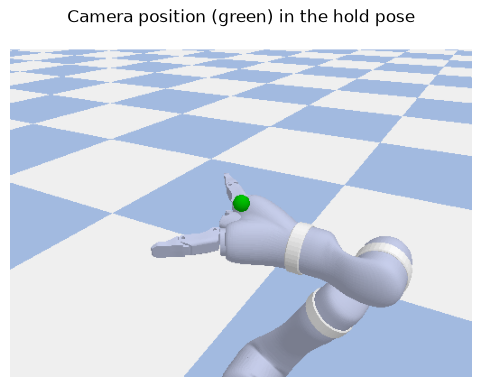

In [19]:
import os, subprocess, sys
CAM = Path('camera/wrist_fisheye_check.npz')
if not CAM.exists():   # renders with the RoboEnv Python (has PyBullet); about 1-2 minutes
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'wrist_camera.py', str(CAM)], check=True)
cam = np.load(CAM)
frames = pd.DataFrame(json.loads(str(cam['rows'])))
frames['dir_err_deg'] = np.abs((frames.est_dir_deg - frames.true_dir_deg + 180) % 360 - 180)
frames['dist_err_cm'] = 100 * (frames.est_dist_m - frames.true_dist_m).abs()
print(f'{len(frames)} frames from {frames.bearing.nunique()} bearings')
print('Detector vs ground truth:',
      f"missed {int(((~frames.found) & (frames.true_visible_px > 0)).sum())},",
      f"false detections {int((frames.found & (frames.true_visible_px == 0)).sum())},",
      f"red pixels that were not the dot {int(frames.false_red_px.sum())}")
plt.figure(figsize=(6, 4.5)); plt.imshow(cam['outside']); plt.axis('off')
plt.title('Camera position (green) in the hold pose'); plt.show()

### What the camera sees at the start, for every bearing

Title: bearing, and whether the dot was found. The robot hasn't moved yet.

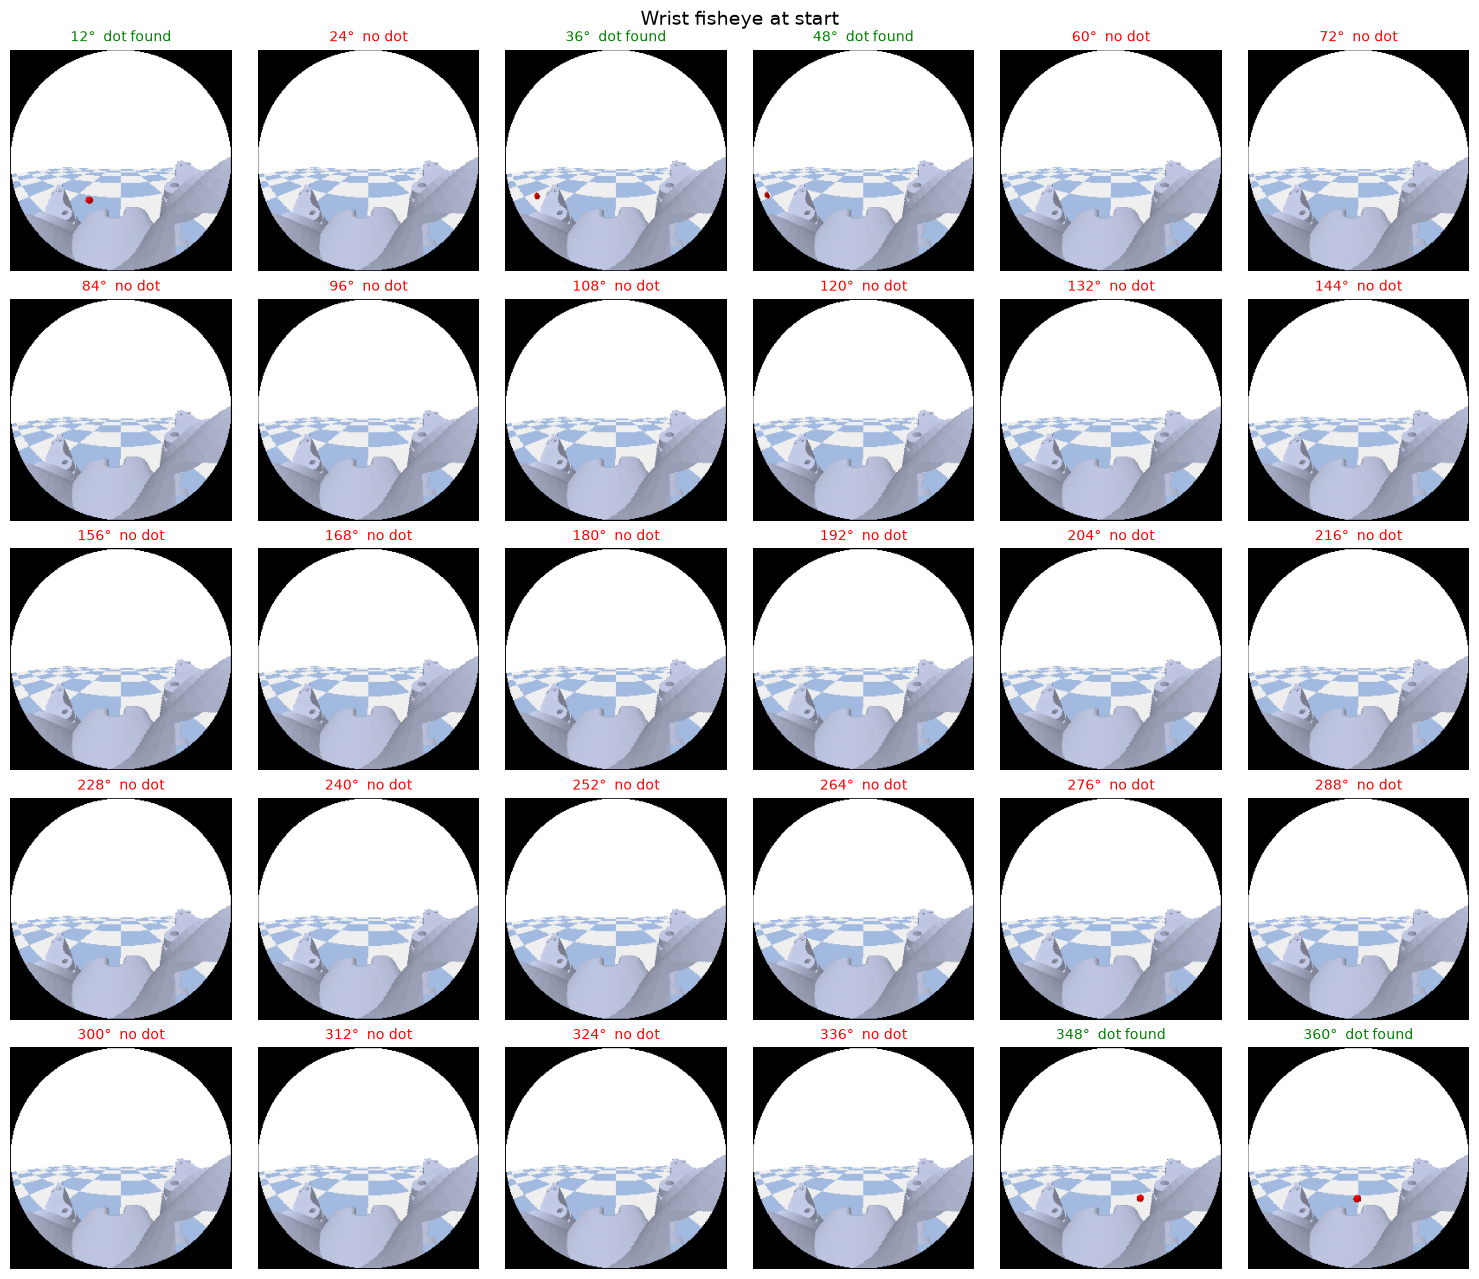

In [20]:
def grid(images, title):
    fig, axes = plt.subplots(5, 6, figsize=(15, 13))
    for ax, im, b in zip(axes.flat, images, cam['bearings']):
        f = frames[(frames.bearing == b)]
        row = f.iloc[0] if title == 'start' else f.iloc[-1]
        ax.imshow(im); ax.axis('off')
        ax.set_title(f"{b}°  {'dot found' if row.found else 'no dot'}", color='green' if row.found else 'red', fontsize=10)
    fig.suptitle(f'Wrist fisheye at {title}', fontsize=14); plt.tight_layout(); plt.show()
grid(cam['img_start'], 'start')

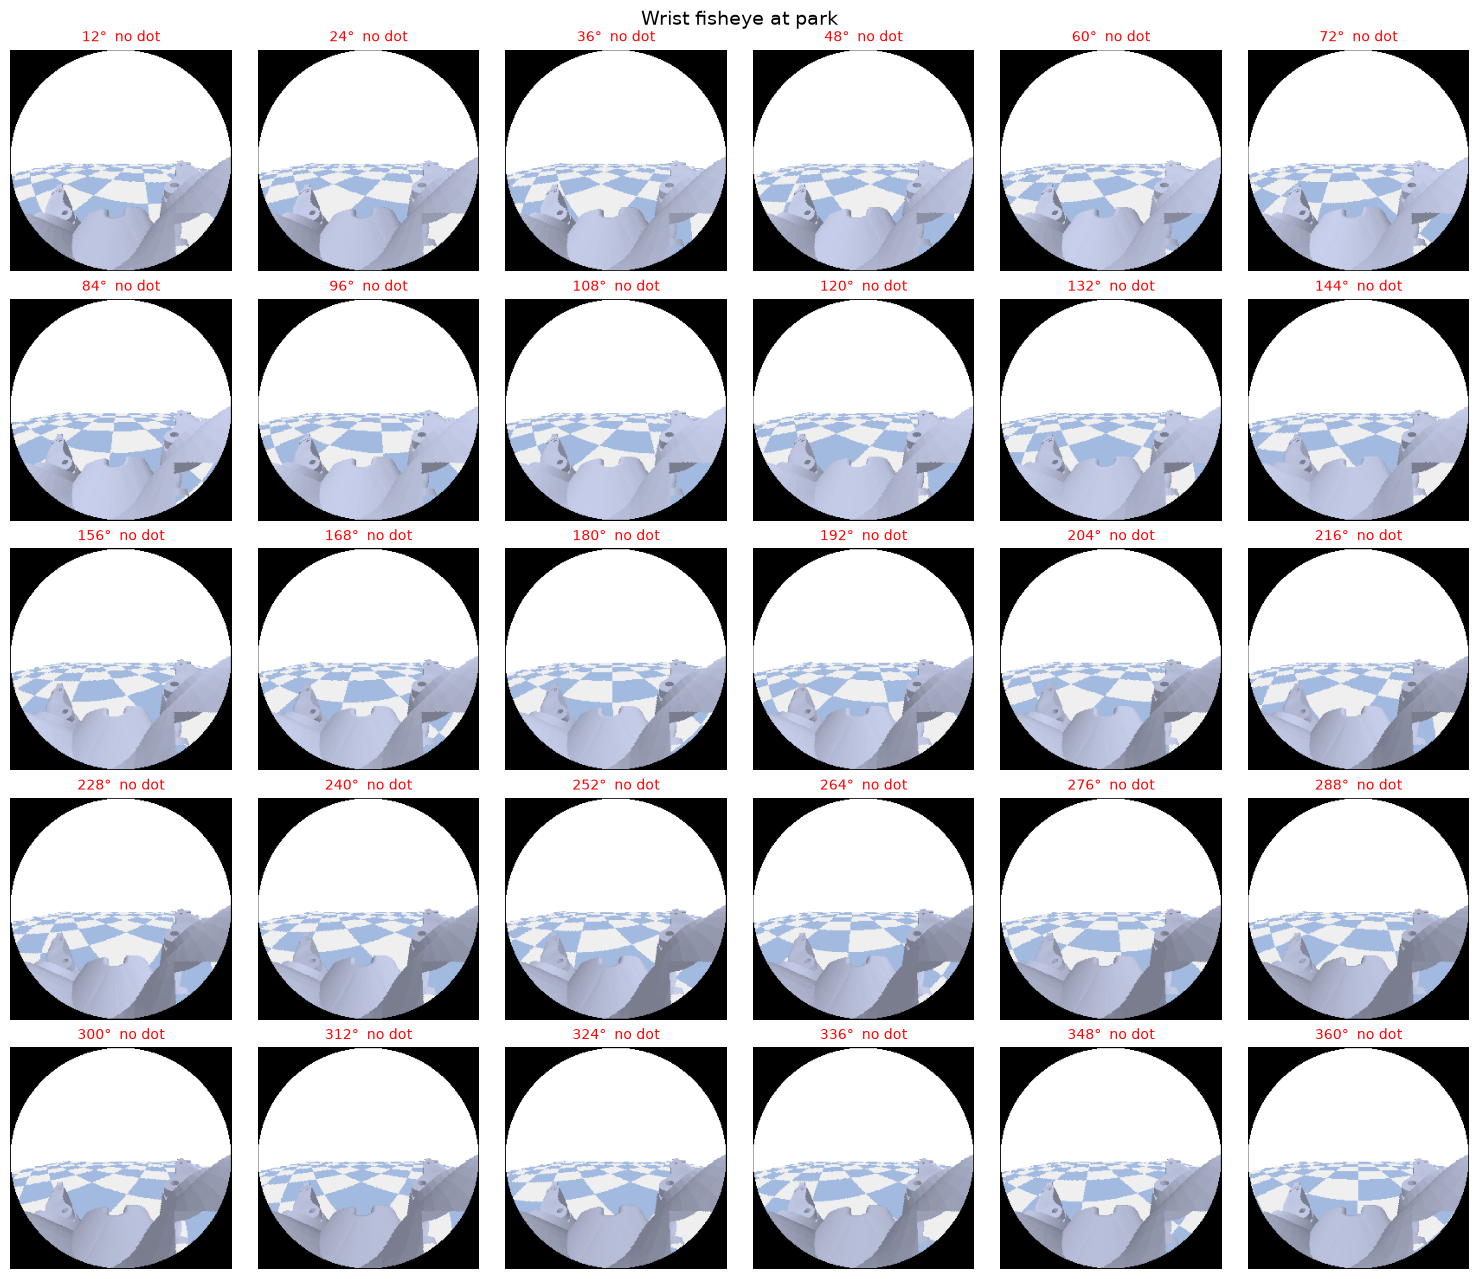

In [21]:
grid(cam['img_park'], 'park')

### Visibility and accuracy per bearing

`seen_at_start`: dot found in the first frame. `fraction_seen`: share of the drive's frames in which it was found. Errors are medians over frames where it was found, against the oracle.

In [22]:
per = frames.groupby('bearing').agg(seen_at_start=('found', 'first'), fraction_seen=('found', 'mean'),
    first_seen_s=('time_s', lambda t: t[frames.loc[t.index, 'found']].min()),
    dot_pixels=('dot_px', lambda s: s[s > 0].median()),
    direction_error_deg=('dir_err_deg', 'median'), distance_error_cm=('dist_err_cm', 'median'))
print(f"Seen at start: {int(per.seen_at_start.sum())} of {len(per)} bearings")
print(f"When seen: median direction error {frames.dir_err_deg.median():.2f}°, median distance error {frames.dist_err_cm.median():.2f} cm")
per.round(2)

Seen at start: 5 of 30 bearings
When seen: median direction error 0.14°, median distance error 0.85 cm


,seen_at_start,fraction_seen,first_seen_s,dot_pixels,direction_error_deg,distance_error_cm
bearing,,,,,,
12,True,0.53,0.0,64.0,0.10,0.78
24,False,0.47,0.2,63.0,0.13,0.77
36,True,0.57,0.0,51.5,0.16,1.00
48,True,0.62,0.0,59.0,0.14,0.85
60,False,0.54,0.4,60.0,0.18,0.88
72,False,0.52,0.6,61.5,0.16,0.84
84,False,0.52,0.6,54.0,0.22,0.85
96,False,0.48,0.8,55.0,0.17,0.94
108,False,0.50,1.0,56.0,0.19,0.97


### Reading the check

- **Accuracy when the dot is seen:** see the medians above. This is the camera + colour threshold + depth, with no training.
- **Start-of-run visibility:** with the arm in its hold pose, the hand and fingers sit below and around the camera. Bearings where the dot isn't found at the start were checked against the segmentation mask: the dot is genuinely out of view or hidden, not missed by the detector.
- **Consequence for the policy:** when the dot isn't visible at the start, the camera can't say which way to turn. That's the t = 0 problem again. It needs an explainable rule, for example "turn on the spot until the dot is seen", or memory (the occlusion experiment).

## Camera check: 180° fisheye RGB-D on the chassis nose (prow)

Same fisheye model, detector and checks as the hand camera (code: `prow_camera.py`). Only the mount changes:
- **on the chassis surface**, on the sloping nose in front of and slightly right of the arm base: `(0.29, -0.08, 0.36)` m in the base frame (surface at 0.33 m, plus 3 cm for the camera body);
- facing robot-forward, level;
- placed from a measured map of the chassis top (0.38 m behind the arm, sloping to 0.32 m at the front edge, x ≈ 0.32 m). The arm base occupies |y| < 0.045 m, so the camera sits just to its right.

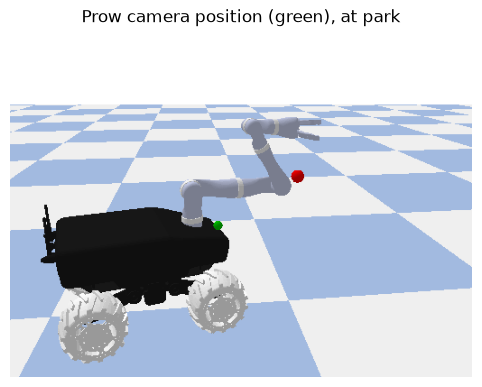

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0
Seen at start: 13 of 30 | seen at park: 12 of 30
When seen: median direction error 0.17°, median distance error 0.97 cm


In [23]:
import camera_check
if not Path('camera/prow_fisheye_check.npz').exists():
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'prow_camera.py',
                    'camera/prow_fisheye_check.npz'], check=True)
prow, prow_frames = camera_check.load('camera/prow_fisheye_check.npz')
plt.figure(figsize=(6, 4.5)); plt.imshow(prow['outside']); plt.axis('off'); plt.title('Prow camera position (green), at park'); plt.show()
prow_per = camera_check.summary(prow_frames)

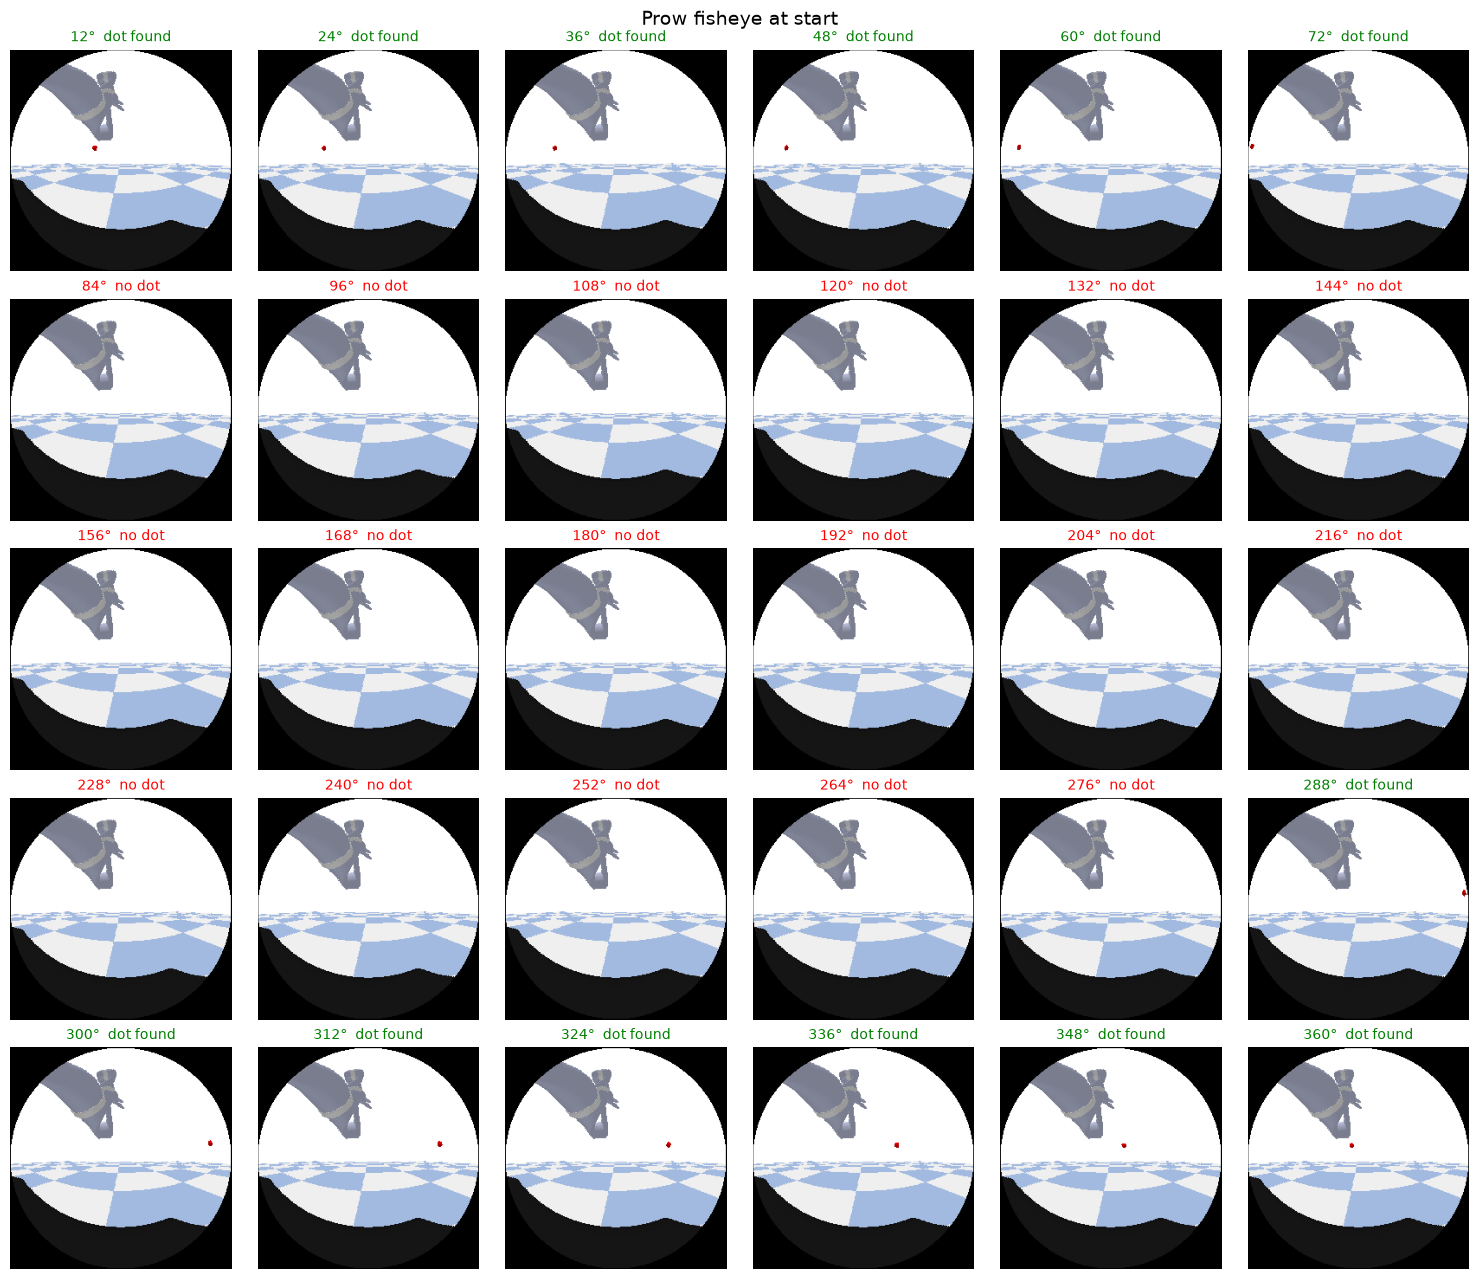

In [24]:
camera_check.grid(prow, prow_frames, 'start', 'Prow fisheye')

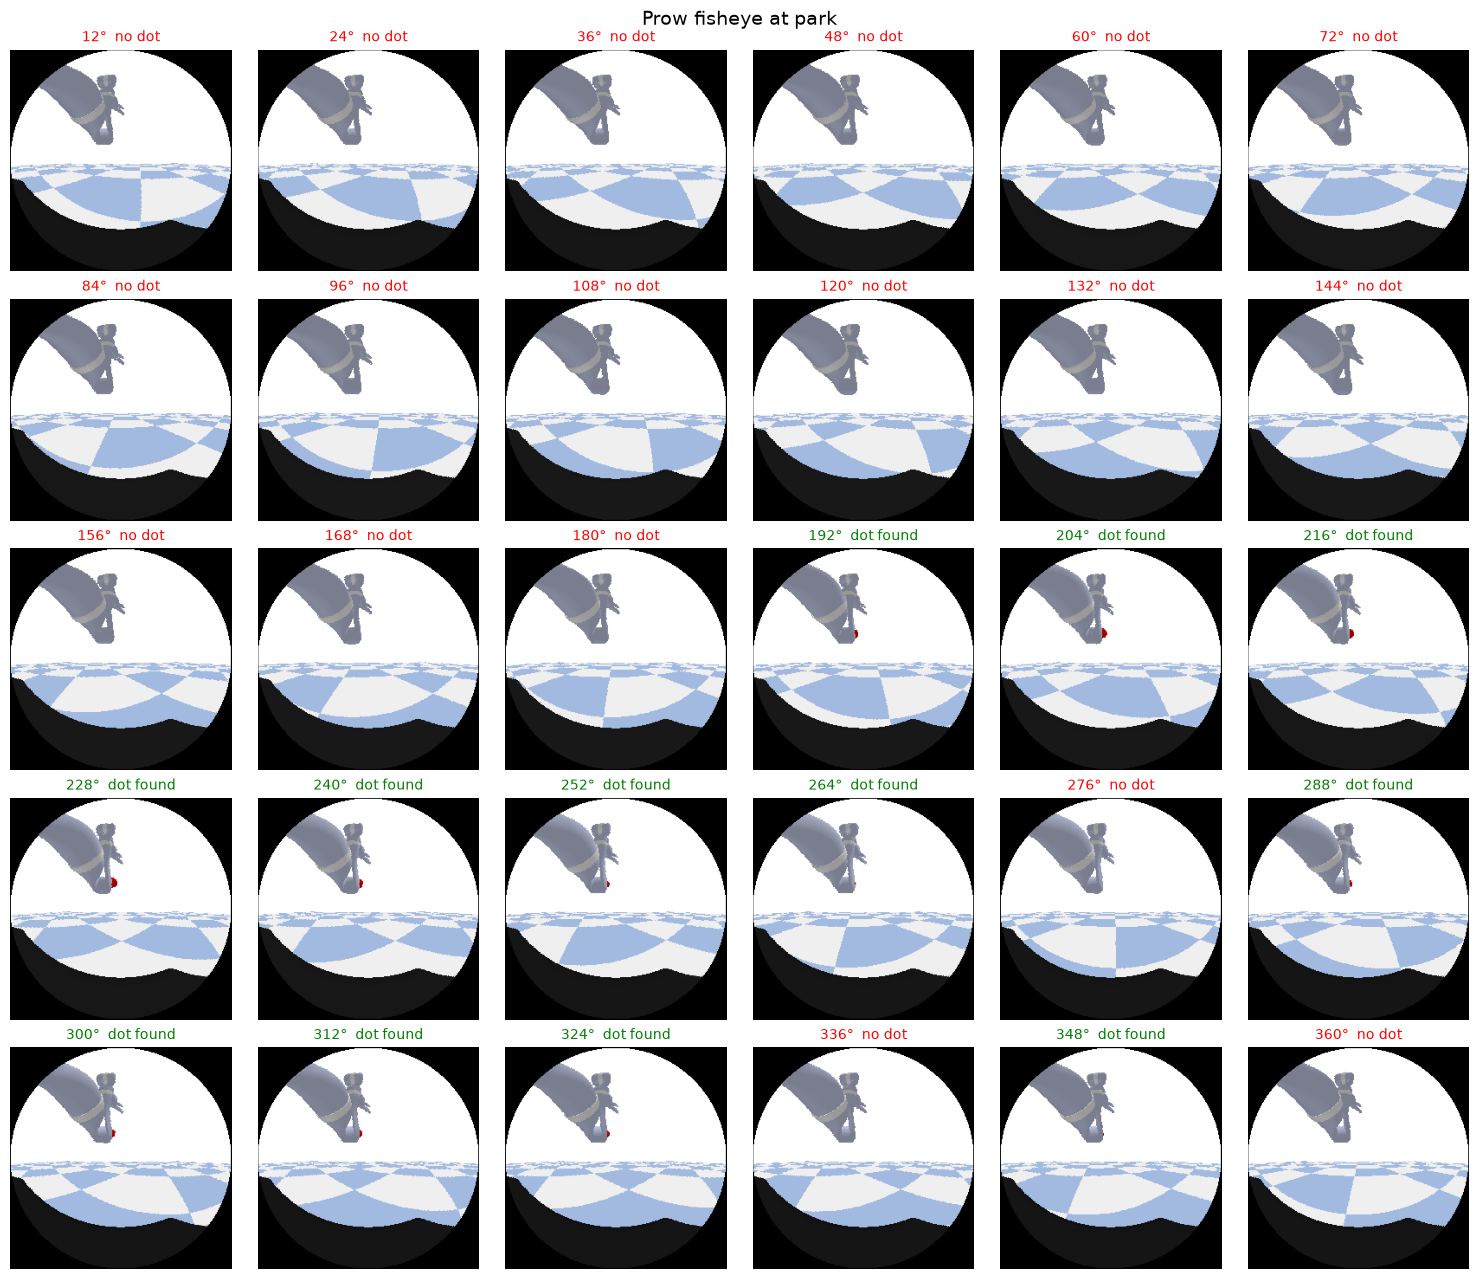

In [25]:
camera_check.grid(prow, prow_frames, 'park', 'Prow fisheye')

In [26]:
prow_per

,seen_at_start,seen_at_park,fraction_seen,dot_pixels,direction_error_deg,distance_error_cm
bearing,,,,,,
12,True,False,0.94,32.0,0.22,0.89
24,True,False,0.95,43.0,0.14,0.94
36,True,False,0.90,42.0,0.14,0.91
48,True,False,0.95,42.5,0.09,0.95
60,True,False,0.92,40.0,0.17,0.99
72,True,False,0.96,36.0,0.19,0.95
84,False,False,0.88,34.5,0.14,0.93
96,False,False,0.84,36.0,0.14,0.97
108,False,False,0.79,34.5,0.15,1.02


### Reading the prow check

| | Hand fisheye | Prow fisheye |
|---|---|---|
| Seen at start | 5 / 30 | 13 / 30 |
| Seen during the drive | about 30–60% of frames | **about 70–96% of frames** |
| Seen at park | 0 / 30 | 12 / 30 |
| Accuracy when seen | 0.14°, 0.9 cm | 0.17°, 1.0 cm |

- **During the drive, the prow camera sees the dot most of the time.** The arm is above it, so it rarely gets in the way.
- **Start:** bearings beyond about ±80° are outside the 180° view, so the robot can't tell which way to turn. It needs a rule or the tracker.
- **Park:** the dot finishes just behind the arm's forearm, at the edge of being hidden. Whether it's seen depends on a few degrees of final heading, which is why some bearings show it and others don't. A tracker carrying the last estimate covers this.
- **Detector:** no misses and no false detections against the segmentation ground truth.

## Camera check: 180° fisheye RGB-D on the front-right corner of the chassis

Same camera, detector and checks. Mount moved to the **front-right corner of the chassis top**: `(0.29, -0.13, 0.36)` m in the base frame, still facing forward and level. The chassis top reaches out to about |y| = 0.12 m at the front edge; beyond that, the front wheel is highest.

**Why:** the further the camera sits from the arm's centre line, the less the forearm should stand between it and the dot at park.

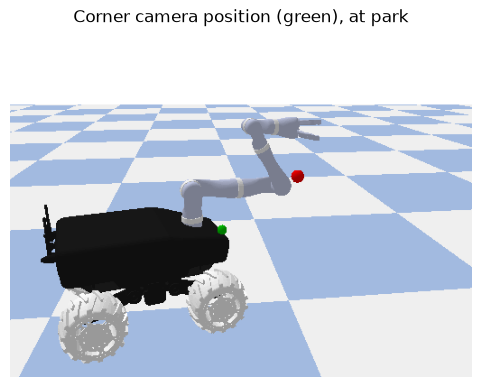

769 frames from 30 bearings
Detector vs ground truth: missed 0, false detections 0, red pixels that were not the dot 0
Seen at start: 13 of 30 | seen at park: 19 of 30
When seen: median direction error 0.13°, median distance error 0.96 cm


In [27]:
import os
if not Path('camera/corner_fisheye_check.npz').exists():
    subprocess.run([os.environ.get('PYBULLET_PYTHON', sys.executable), 'prow_camera.py',
                    'camera/corner_fisheye_check.npz'], check=True, env=dict(os.environ, PROW_MOUNT='0.29,-0.13,0.36'))
corner, corner_frames = camera_check.load('camera/corner_fisheye_check.npz')
plt.figure(figsize=(6, 4.5)); plt.imshow(corner['outside']); plt.axis('off'); plt.title('Corner camera position (green), at park'); plt.show()
corner_per = camera_check.summary(corner_frames)

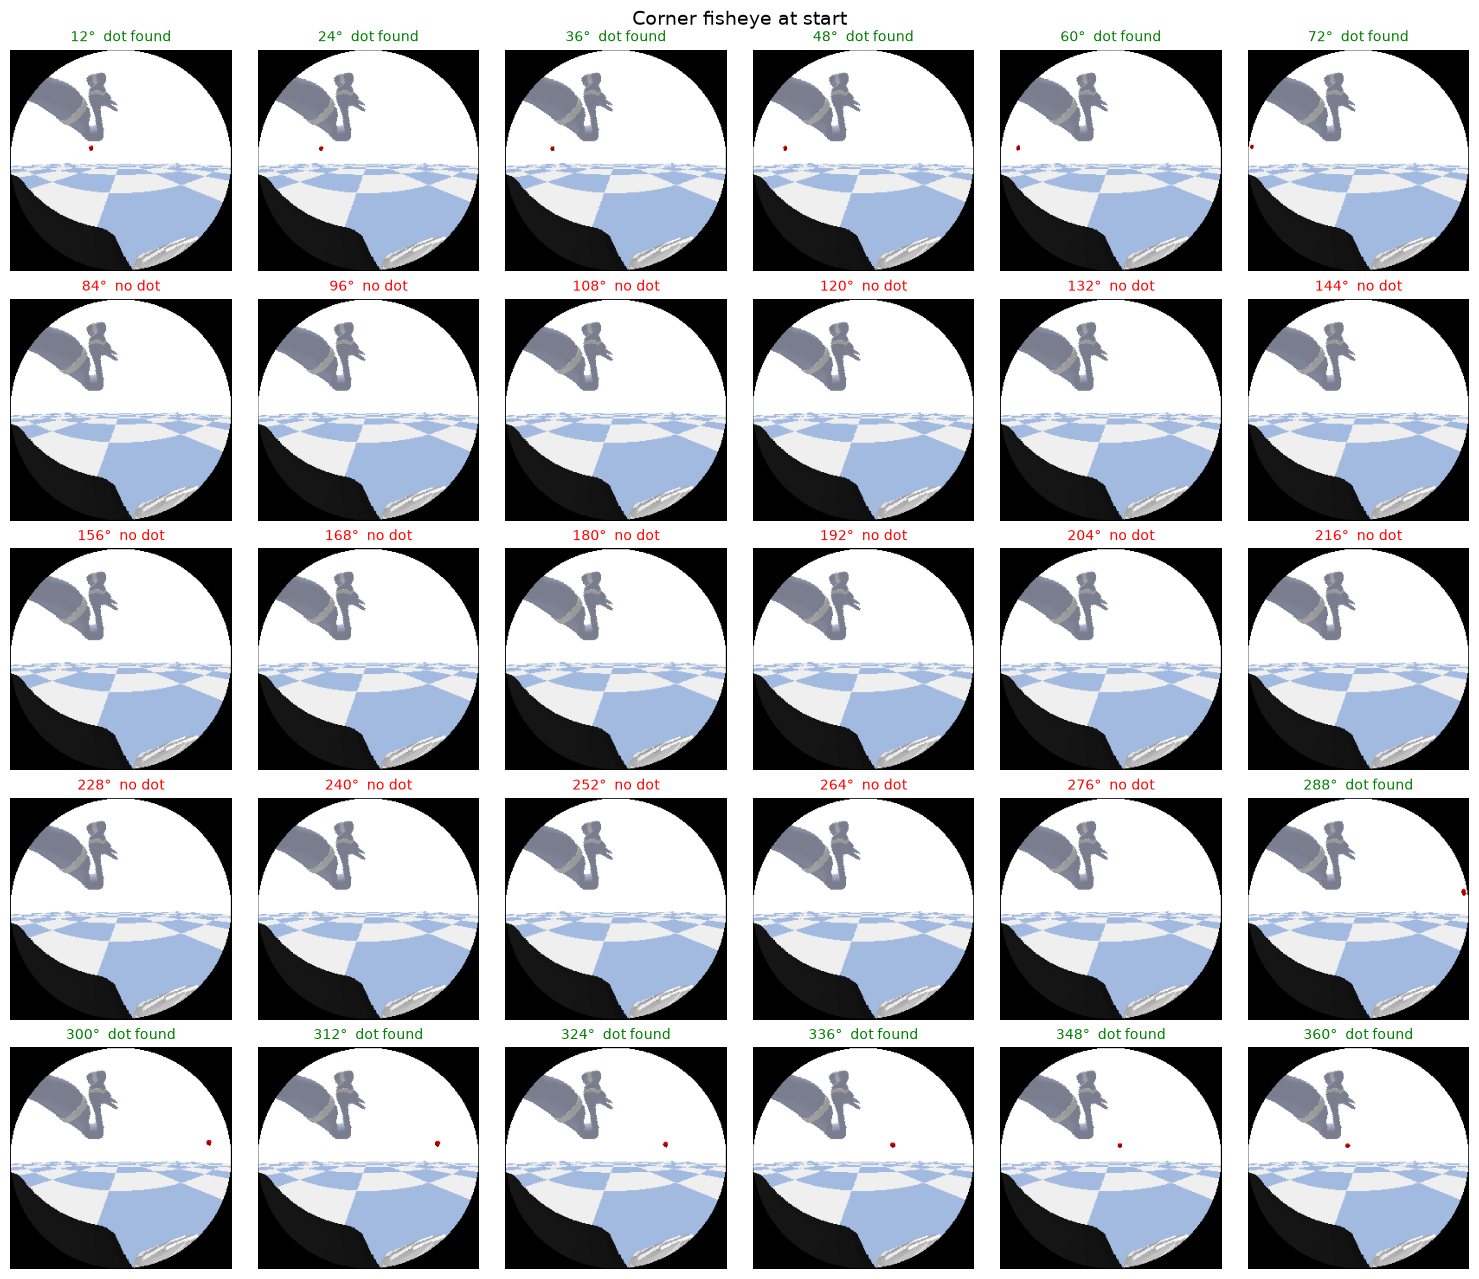

In [28]:
camera_check.grid(corner, corner_frames, 'start', 'Corner fisheye')

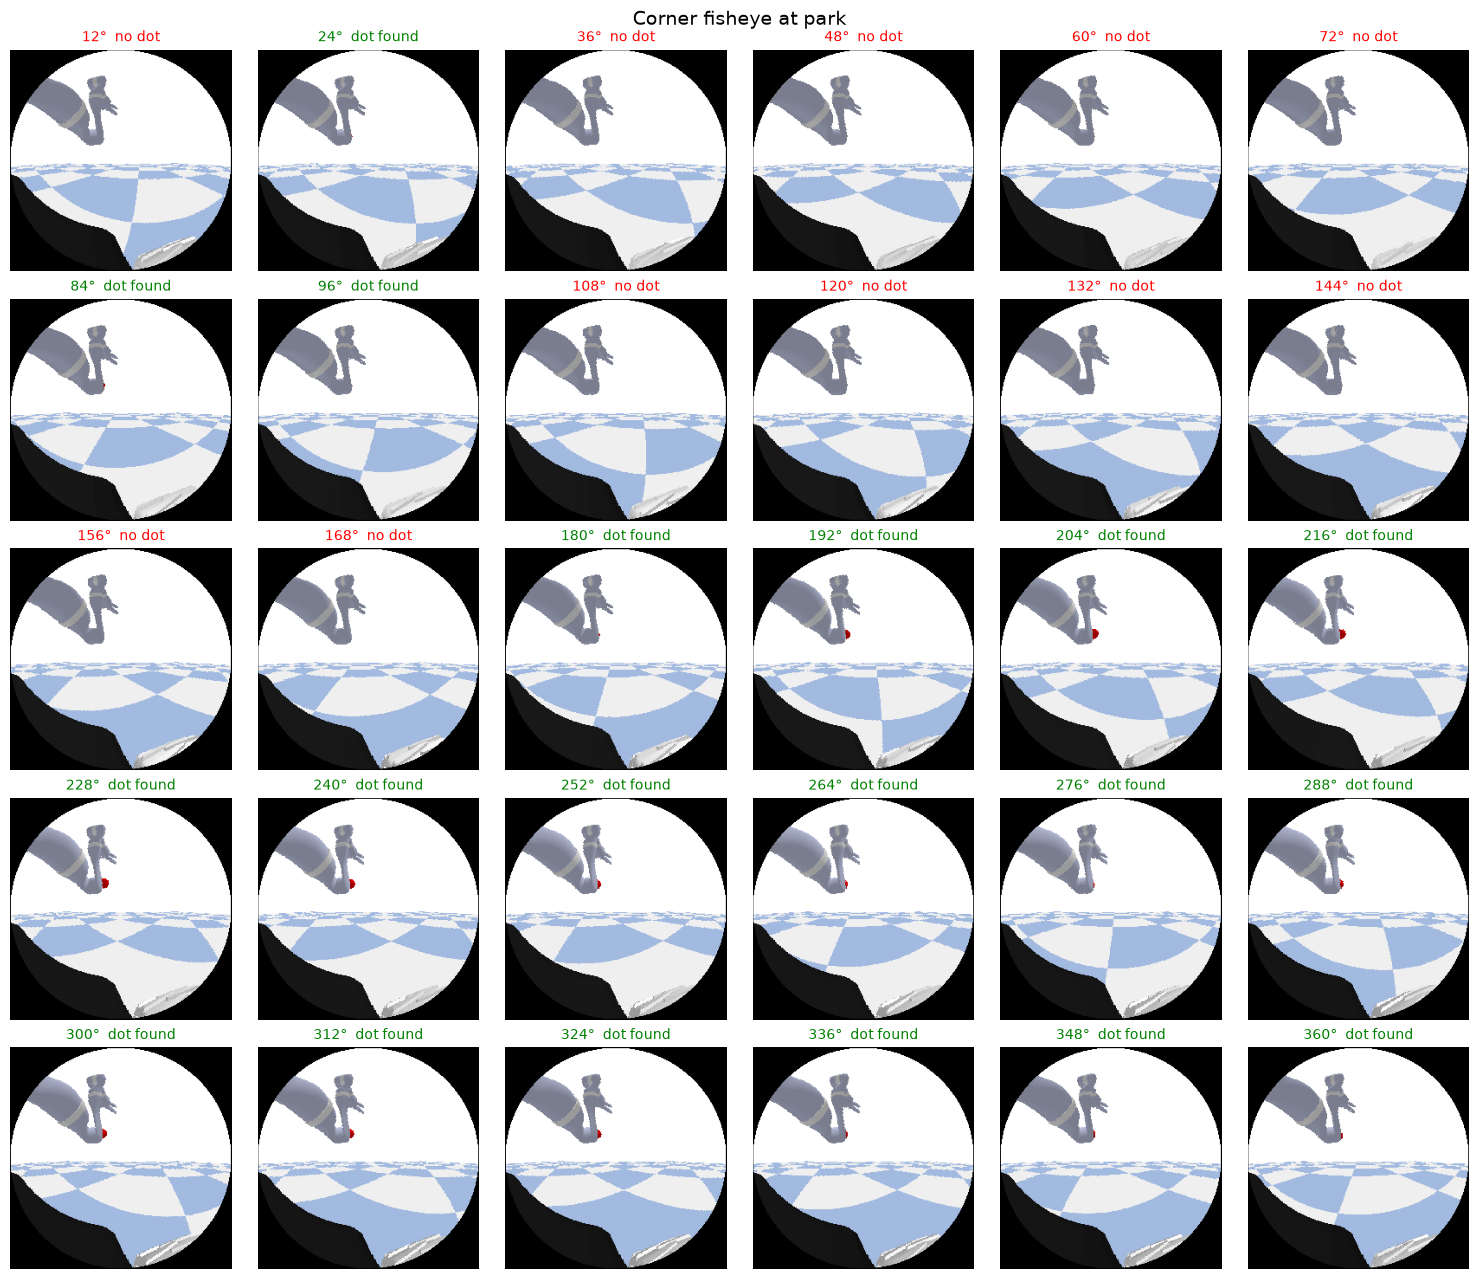

In [29]:
camera_check.grid(corner, corner_frames, 'park', 'Corner fisheye')

### Nose vs corner, per bearing

In [30]:
pd.concat({'nose': prow_per[['seen_at_start', 'seen_at_park', 'fraction_seen']],
           'corner': corner_per[['seen_at_start', 'seen_at_park', 'fraction_seen']]}, axis=1)

nose                                   corner               \
        seen_at_start seen_at_park fraction_seen seen_at_start seen_at_park   
bearing                                                                       
12               True        False          0.94          True        False   
24               True        False          0.95          True         True   
36               True        False          0.90          True        False   
48               True        False          0.95          True        False   
60               True        False          0.92          True        False   
72               True        False          0.96          True        False   
84              False        False          0.88         False         True   
96              False        False          0.84         False         True   
108             False        False          0.79         False        False   
120             False        False          0.80         False        False   
132             False        False          0.81         False        False   
144             False        False          0.77         False        False   
156             False        False          0.73         False        False   
168             False        False          0.73         False        False   
180             False        False          0.52         False         True   
192             False         True          0.70         False         True   
204             False         True          0.73         False         True   
216             False         True          0.78         False         True   
228             False         True          0.81         False         True   
240             False         True          0.83         False         True   
252             False         True          0.82         False         True   
264             False         True          0.84         False         True   
276             False        False          0.84         False         True   
288              True         True          0.96          True         True   
300              True         True          0.96          True         True   
312              True         True          0.95          True         True   
324              True         True          0.86          True         True   
336              True        False          0.74          True         True   
348              True         True          0.76          True         True   
360              True        False          0.91          True         True   

                       
        fraction_seen  
bearing                
12               0.94  
24               1.00  
36               0.95  
48               0.95  
60               0.92  
72               0.96  
84               0.92  
96               0.88  
108              0.79  
120              0.80  
132              0.81  
144              0.77  
156              0.76  
168              0.73  
180              0.58  
192              0.67  
204              0.70  
216              0.78  
228              0.77  
240              0.77  
252              0.75  
264              0.80  
276              0.80  
288              0.92  
300              0.92  
312              0.86  
324              0.81  
336              0.74  
348              0.76  
360              1.00

### Reading the corner check

| | Hand | Nose | **Corner** |
|---|---|---|---|
| Seen at start | 5 / 30 | 13 / 30 | 13 / 30 |
| Seen during the drive | about 30–60% | about 70–96% | about 60–100% |
| Seen at park | 0 / 30 | 12 / 30 | **19 / 30** |
| Accuracy when seen | 0.14°, 0.9 cm | 0.17°, 1.0 cm | 0.13°, 1.0 cm |

- Moving the camera 5 cm further out, from y = -0.08 to y = -0.13, raises park visibility from 12 to 19 of 30 bearings. The forearm blocks the dot less.
- The start is unchanged: dots beyond about ±80° are outside any forward 180° view.
- The front-right wheel now shows at the bottom edge of the image. It doesn't affect the dot, since it's below the horizon.
- The dot is still hidden at park for 11 bearings, 12°–72° and 108°–168°: the bearings where the robot turned left to reach the dot, so the tracker is still needed for the final moments.

## Camera models: the dot comes from the corner camera

`wheels+live_dot` was given the true dot position at every step. A real robot does not have that. These three models get the dot from the corner fisheye camera instead, and keep the same 12 wheel inputs.

At every step:

1. Render the corner fisheye from the robot's current pose.
2. Find the red pixels. Their centre gives a ray; the depth at those pixels gives a distance.
3. Use the fixed camera mount to turn that into the dot's position relative to the robot.
4. A tracker holds that position. When the dot is seen, it is replaced. When the dot is hidden, it is moved using the wheel encoders.
5. The network gets the tracker's distance and the sin and cos of its direction. Until the dot is first seen, these are 0, 0, 0.

| Model | Dot inputs | PARK output |
|---|---|---|
| `camera+flag` | distance, sin, cos, visible flag (1 when the camera sees the dot in this frame) | PARK yes/no |
| `camera+flag+time_to_park` | distance, sin, cos, visible flag | seconds until the expert would park; PARK at 0.25 s or less |
| `camera+time_to_park` | distance, sin, cos | seconds until the expert would park; PARK at 0.35 s or less |

The network and training are the same as before: 2×16 ReLU, 4 wheel outputs, 21 training runs, Adam, lr 0.01, 300 epochs, seed 7. `camera_features.py` computes the camera inputs for the training runs from the expert's recorded poses and saves them in `camera_features/`.

In [31]:
CAM = Path('camera_features')
for e in rows:
    if e['split'] != 'holdout':
        e['camera'] = np.load(CAM / f"camera_{e['bearing']}.npy")      # distance, sin, cos, visible
        assert len(e['camera']) == len(e['x'])

CLIP, THRESH = 3.0, 0.25          # time to park is clipped at 3 s and scaled to 0..1
CAMERA_MODELS = {                  # name: (dot input columns, PARK output)
    'camera+flag':              ([0, 1, 2, 3], 'park'),
    'camera+flag+time_to_park': ([0, 1, 2, 3], 'time_to_park'),
    'camera+time_to_park':      ([0, 1, 2],    'time_to_park'),
}

def camera_inputs(e, cols):
    return np.c_[e['x'][:, WHEEL], e['camera'][:, cols]].astype(np.float32)

def time_to_park(e):              # one PARK row per run, the last one
    t = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == e['bearing'])['archive'])['time_s']
    return (np.minimum(t[-1] - t, CLIP) / CLIP).astype(np.float32)

class CameraPolicy(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.shared = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
        self.wheels = nn.Linear(16, 4)
        self.park = nn.Linear(16, 1)          # PARK logit, or scaled time to park
    def forward(self, x):
        h = self.shared(x)
        return self.wheels(h), self.park(h).squeeze(1)

def camera_data(eps, cols, head):
    X = torch.from_numpy(np.concatenate([camera_inputs(e, cols) for e in eps]))
    W = torch.from_numpy(np.concatenate([e['wheels'] for e in eps]).astype(np.float32))
    w = torch.from_numpy(np.concatenate([np.full(len(e['x']), 1 / (len(e['x']) * len(eps))) for e in eps]).astype(np.float32))
    if head == 'park':
        P = torch.from_numpy(np.concatenate([e['park'] for e in eps]).astype(np.float32))
    else:
        P = torch.from_numpy(np.concatenate([time_to_park(e) for e in eps]))
    return X, W, P, w

def camera_losses(model, data, head, pos_weight):
    X, W, P, w = data
    pw, pp = model(X)
    wheel_mse = (w * ((pw - W) ** 2).mean(1)).sum()
    if head == 'park':
        park_loss = F.binary_cross_entropy_with_logits(pp, P, pos_weight=pos_weight)       # weighted by PARK_WEIGHT in the total
    else:
        park_loss = (w * (pp - P) ** 2).sum()                                               # each run counts equally, weight 1
    return wheel_mse, park_loss

camera_history = []
def train_camera_model(name, cols, head):
    torch.manual_seed(SEED)
    tr, te = camera_data(train, cols, head), camera_data(test, cols, head)
    pos_weight = (len(tr[2]) - tr[2].sum()) / tr[2].sum() if head == 'park' else None    # from training data only
    model = CameraPolicy(tr[0].shape[1]); opt = torch.optim.Adam(model.parameters(), lr=LR)
    for epoch in range(EPOCHS + 1):
        wheel_mse, park_loss = camera_losses(model, tr, head, pos_weight)
        with torch.no_grad():
            te_wheel, te_park = camera_losses(model, te, head, pos_weight)                   # test is only watched, never trained on
        camera_history.append(dict(model=name, epoch=epoch, train_wheel_mse=wheel_mse.item(), test_wheel_mse=te_wheel.item(),
                                   train_park_loss=park_loss.item(), test_park_loss=te_park.item()))
        if epoch < EPOCHS:
            total = wheel_mse + (PARK_WEIGHT * park_loss if head == 'park' else park_loss)
            opt.zero_grad(); total.backward(); opt.step()
    return model

camera_models = {}
for name, (cols, head) in CAMERA_MODELS.items():
    camera_models[name] = m = train_camera_model(name, cols, head)
    sd = {k: v.detach().numpy() for k, v in m.state_dict().items()}
    if head == 'time_to_park':
        sd['ttp_clip'], sd['ttp_thresh'] = np.float32(CLIP), np.float32(THRESH)
    # Compare with the saved network that was tested.
    tested = np.load({'camera+flag': 'models/camera_flag.npz', 'camera+flag+time_to_park': 'models/camera_flag_ttp.npz',
                      'camera+time_to_park': 'models/camera_ttp_noflag.npz'}[name])
    diff = max(float(np.abs(sd[k] - tested[k]).max()) for k in tested.files)
    print(f'{name:26s} inputs={len(WHEEL) + len(cols)}  largest weight difference vs the tested model: {diff:.1e}')
# Small differences are floating-point rounding. The tests below use the saved networks in models/.
camera_history = pd.DataFrame(camera_history)

camera+flag                inputs=16  largest weight difference vs the tested model: 7.2e-07


camera+flag+time_to_park   inputs=16  largest weight difference vs the tested model: 6.7e-04


camera+time_to_park        inputs=15  largest weight difference vs the tested model: 2.7e-04


### Training curves

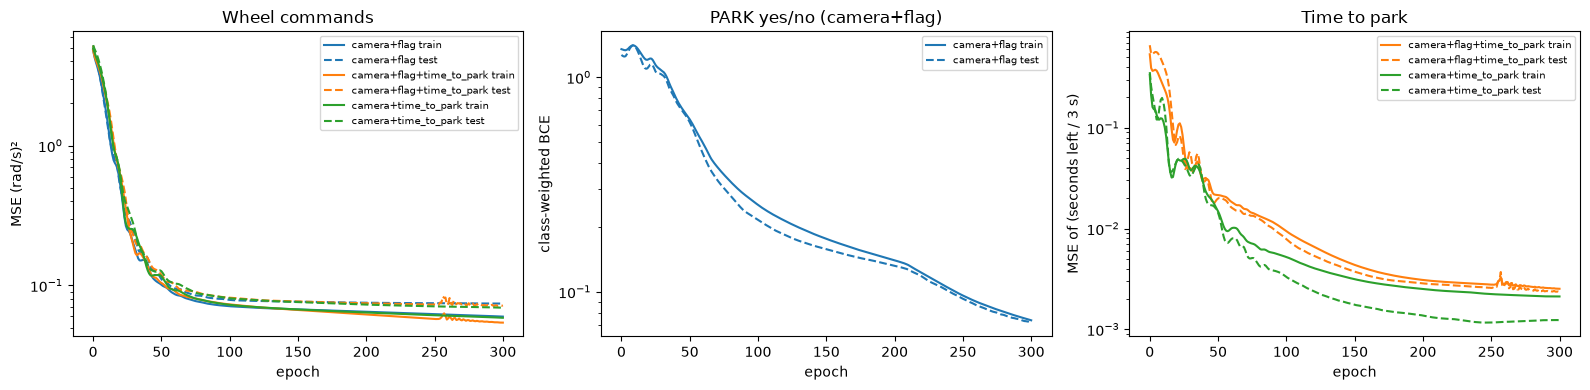

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in camera_history.groupby('model', sort=False):
    line, = ax[0].plot(h.epoch, h.train_wheel_mse, label=f'{name} train')
    ax[0].plot(h.epoch, h.test_wheel_mse, '--', color=line.get_color(), label=f'{name} test')
    a = ax[1] if CAMERA_MODELS[name][1] == 'park' else ax[2]
    a.plot(h.epoch, h.train_park_loss, color=line.get_color(), label=f'{name} train')
    a.plot(h.epoch, h.test_park_loss, '--', color=line.get_color(), label=f'{name} test')
ax[0].set(title='Wheel commands', ylabel='MSE (rad/s)²')
ax[1].set(title='PARK yes/no (camera+flag)', ylabel='class-weighted BCE')
ax[2].set(title='Time to park', ylabel='MSE of (seconds left / 3 s)')
for a in ax:
    a.set(xlabel='epoch', yscale='log'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
# Solid: 21 training runs. Dashed: 4 test runs, watched only. Training always stops at 300 epochs.

**Model to build from:** `camera+flag+time_to_park` (`models/camera_flag_ttp.npz`). PARK at 0.25 s or less. Parked 16 of 25.

### Testing

Each model drives the robot in the fast simulator (`sensor_parking`), with the camera steps above running every 1/30 s. There are 25 bearings: the 21 training runs and the 4 test runs. The 5 holdout bearings are not used. Each run is allowed the expert's park time plus 3 s, and its final position is compared with the expert's. `wheels+live_dot`, which sees the true dot, is shown for comparison.

In [33]:
ref = json.loads(Path('expert_reference.json').read_text())['bearings']
RESULTS = {'camera+flag': 'camera_flag', 'camera+flag+time_to_park': 'camera_flag_ttp',
           'camera+time_to_park': 'camera_ttp_noflag_0.35s'}   # PARK at 0.35 s or less

def angle(a):
    return float(np.rad2deg(abs((a + np.pi) % (2 * np.pi) - np.pi)))

tests = []
for name, folder in RESULTS.items():
    for b, x in ref.items():
        run = json.loads(Path(f'camera_loop/{folder}/run_{b}.json').read_text()); log = run['log']
        park_t = next((l['t'] for l in log if l['park_prob'] >= 0.5), None)
        tests.append(dict(model=name, bearing=int(b), split=x['split'], seen_at_start=log[0]['visible'], parked=run['parked'],
                          final_error_cm=100 * np.hypot(*np.subtract(run['final_base'], x['final_base_xy'])),
                          final_heading_error_deg=angle(run['final_yaw'] - x['final_yaw']),
                          park_time_vs_expert_s=None if park_t is None else park_t - x['park_time_s'],
                          dot_distance_error_cm=100 * np.mean([abs(l['est_dist'] - l['true_dist']) for l in log if l['visible']] or [np.nan])))
tests = pd.DataFrame(tests)
true_dot = closed[closed.model == 'wheels+live_dot'].set_index('bearing_deg')
tests['true_dot_parked'] = tests.bearing.map(true_dot.parked)

def summary(g):
    return pd.Series({'runs': len(g), 'parked': int(g.parked.sum()), 'true-dot model parked': int(g.true_dot_parked.sum()),
                      'median final error (cm)': round(g.final_error_cm.median(), 1)})
by = {'all': tests, 'dot seen at start': tests[tests.seen_at_start], 'dot not seen at start': tests[~tests.seen_at_start]}
pd.concat({k: v.groupby('model', sort=False).apply(summary) for k, v in by.items()}).unstack(0).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0, sort_remaining=False)

all                               \
                          runs parked true-dot model parked   
model                                                         
camera+flag               25.0   17.0                  23.0   
camera+flag+time_to_park  25.0   16.0                  23.0   
camera+time_to_park       25.0    6.0                  23.0   

                                                 dot not seen at start         \
                         median final error (cm)                  runs parked   
model                                                                           
camera+flag                                 16.7                  14.0   10.0   
camera+flag+time_to_park                    14.5                  14.0    9.0   
camera+time_to_park                         44.8                  14.0    0.0   

                                                                        \
                         true-dot model parked median final error (cm)   
model                                                                    
camera+flag                               12.0                    15.1   
camera+flag+time_to_park                  12.0                    14.9   
camera+time_to_park                       12.0                    50.6   

                         dot seen at start                               \
                                      runs parked true-dot model parked   
model                                                                     
camera+flag                           11.0    7.0                  11.0   
camera+flag+time_to_park              11.0    7.0                  11.0   
camera+time_to_park                   11.0    6.0                  11.0   

                                                  
                         median final error (cm)  
model                                             
camera+flag                                 22.4  
camera+flag+time_to_park                    14.5  
camera+time_to_park                         19.9

### Every bearing: parked or not

In [34]:
tests.pivot_table(index=['split', 'bearing', 'seen_at_start'], columns='model', values='parked', aggfunc='first', sort=False)\
     .reindex(columns=list(RESULTS)).join(true_dot.parked.rename('wheels+live_dot (true dot)'), on='bearing')

camera+flag  camera+flag+time_to_park  \
split bearing seen_at_start                                          
train 12      True                 False                      True   
      36      True                  True                     False   
      60      True                 False                     False   
      72      True                 False                     False   
      84      False                False                     False   
      120     False                False                     False   
      156     False                 True                     False   
      168     False                 True                      True   
      180     False                 True                      True   
      192     False                 True                      True   
      216     False                 True                      True   
      228     False                 True                      True   
      240     False                 True                      True   
      252     False                 True                      True   
      264     False                 True                      True   
      288     True                  True                      True   
      300     True                  True                      True   
      312     True                  True                      True   
      336     True                  True                      True   
      348     True                  True                      True   
      360     True                 False                     False   
test  24      True                  True                      True   
      108     False                False                     False   
      132     False                False                     False   
      204     False                 True                      True   

                             camera+time_to_park  wheels+live_dot (true dot)  
split bearing seen_at_start                                                   
train 12      True                          True                        True  
      36      True                         False                        True  
      60      True                         False                        True  
      72      True                         False                        True  
      84      False                        False                        True  
      120     False                        False                        True  
      156     False                        False                       False  
      168     False                        False                       False  
      180     False                        False                        True  
      192     False                        False                        True  
      216     False                        False                        True  
      228     False                        False                        True  
      240     False                        False                        True  
      252     False                        False                        True  
      264     False                        False                        True  
      288     True                         False                        True  
      300     True                          True                        True  
      312     True                         False                        True  
      336     True                          True                        True  
      348     True                          True                        True  
      360     True                          True                        True  
test  24      True                          True                        True  
      108     False                        False                        True  
      132     False                        False                        True  
      204     False                        False                        True

### Every bearing: final position error (cm) and camera distance error when the dot is seen (cm)

In [35]:
pd.concat({'final error (cm)': tests.pivot_table(index=['split', 'bearing'], columns='model', values='final_error_cm', sort=False),
           'camera distance error (cm)': tests.pivot_table(index=['split', 'bearing'], columns='model', values='dot_distance_error_cm', sort=False)},
          axis=1).round(1)

final error (cm)                                               \
model              camera+flag camera+flag+time_to_park camera+time_to_park   
split bearing                                                                 
train 12                   9.9                      2.9                 6.7   
      36                  18.3                     21.7                23.4   
      60                  34.8                      4.4                24.2   
      72                  36.2                     30.9                23.5   
      84                  24.7                     42.2                49.1   
      120                 24.1                     22.3                49.2   
      156                 28.5                     25.1                55.2   
      168                 15.5                     18.3                53.5   
      180                 12.4                      9.9                49.6   
      192                  9.4                     10.8                53.5   
      216                 12.2                     12.3                53.1   
      228                 14.9                     12.3                50.1   
      240                 12.7                     16.2                48.5   
      252                 14.2                     13.7                44.8   
      264                 16.7                     12.2                40.7   
      288                 22.4                     14.7                36.7   
      300                 29.0                     14.5                18.0   
      312                 24.0                     14.9                31.8   
      336                 22.4                     11.9                19.2   
      348                 19.1                     12.0                19.9   
      360                  2.5                     20.1                 9.7   
test  24                  13.9                      3.1                 8.1   
      108                 15.3                     20.8                51.4   
      132                 27.5                     22.4                51.1   
      204                 11.3                     11.2                54.2   

              camera distance error (cm)                           \
model                        camera+flag camera+flag+time_to_park   
split bearing                                                       
train 12                             0.9                      0.8   
      36                             0.8                      0.9   
      60                             1.0                      0.9   
      72                             1.0                      0.9   
      84                             1.0                      1.1   
      120                            1.0                      0.9   
      156                            1.0                      0.9   
      168                            1.0                      0.9   
      180                            1.0                      0.9   
      192                            1.0                      1.0   
      216                            1.0                      0.9   
      228                            0.8                      0.9   
      240                            0.8                      0.9   
      252                            0.9                      0.9   
      264                            0.9                      0.9   
      288                            1.0                      0.9   
      300                            1.1                      0.9   
      312                            1.0                      0.9   
      336                            1.0                      0.8   
      348                            1.0                      0.8   
      360                            0.9                      0.8   
test  24                             0.8                      0.8   
      108                            0.9                      1.0   
      1

## Test metrics, plotted

Every count is out of 25 bearings: 21 training runs and 4 test runs. Worst cases come first. `camera+flag+time_to_park` is the model to build from.

In [36]:
runs = {}                         # (model, bearing) -> saved test run
for name, folder in RESULTS.items():
    for b in ref:
        runs[name, int(b)] = json.loads(Path(f'camera_loop/{folder}/run_{b}.json').read_text())
# Expert paths, for drawing only (from the verified expert replay).
expert_path = {r['bearing_deg']: np.array([f['base'][:2] for f in r['expert']['frames']])
               for r in json.loads(Path('closed_loop_native/result_wheels_live_dot.json').read_text())['runs']}
MAIN = 'camera+flag+time_to_park'
COLORS = dict(zip(list(RESULTS) + ['wheels+live_dot (true dot)'], ['tab:blue', 'tab:orange', 'tab:green', 'grey']))
bearings = sorted(int(b) for b in ref)

### 1. Which bearings park? (green parked, red not, grey background: dot not visible at the start)

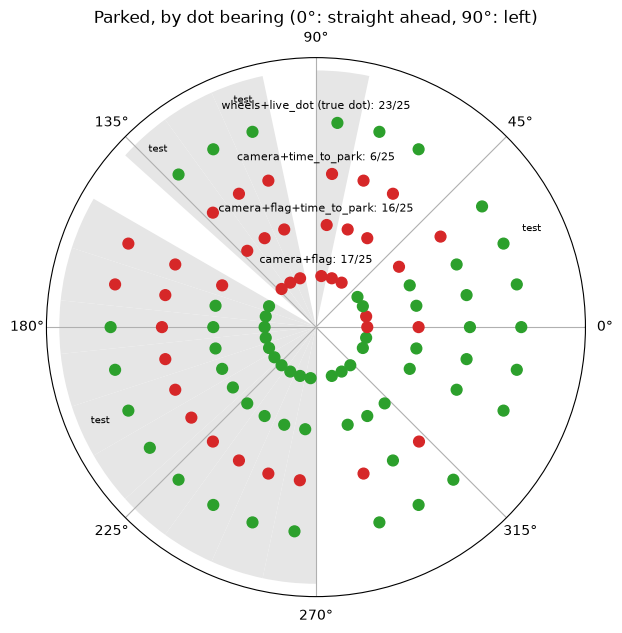

In [37]:
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(projection='polar')
names = list(RESULTS) + ['wheels+live_dot (true dot)']
unseen = [b for b in bearings if not runs[MAIN, b]['log'][0]['visible']]
for b in unseen:
    ax.bar(np.deg2rad(b), len(names) + 1, width=np.deg2rad(12), color='0.9', zorder=0)
for k, name in enumerate(names):
    parked = [true_dot.parked[b] if 'true dot' in name else runs[name, b]['parked'] for b in bearings]
    ax.scatter(np.deg2rad(bearings), np.full(len(bearings), k + 1), c=['tab:green' if p else 'tab:red' for p in parked], s=60, zorder=2)
    ax.text(np.deg2rad(90), k + 1.25, f'{name}: {sum(parked)}/25', fontsize=8, ha='center')
ax.set_yticks([]); ax.set_theta_zero_location('E'); ax.set_title('Parked, by dot bearing (0°: straight ahead, 90°: left)')
for b in [b for b in bearings if ref[str(b)]['split'] == 'test']:
    ax.annotate('test', (np.deg2rad(b), len(names) + 0.6), fontsize=7, ha='center')
plt.show()

### 2. Final position error, worst first (bars: model to build from; markers: the others)

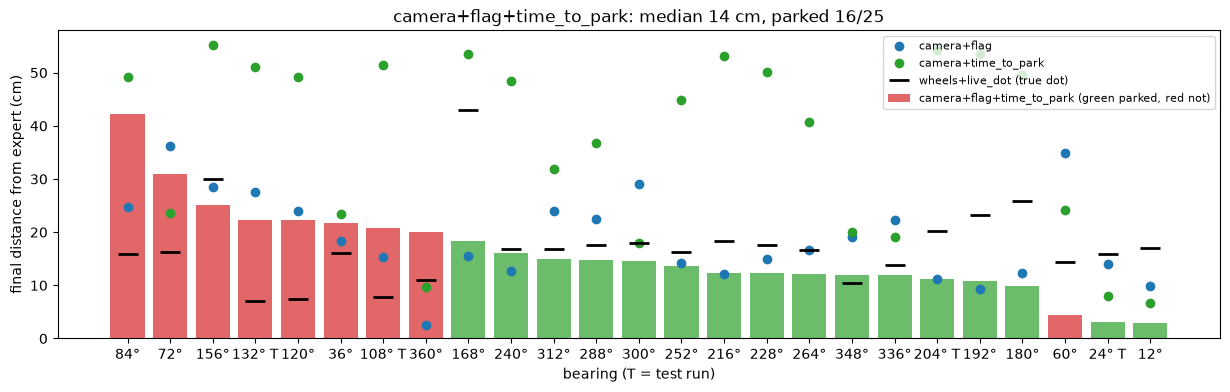

In [38]:
order = tests[tests.model == MAIN].sort_values('final_error_cm', ascending=False)
fig, ax = plt.subplots(figsize=(15, 4))
x = np.arange(len(order))
ax.bar(x, order.final_error_cm, color=['tab:green' if p else 'tab:red' for p in order.parked], alpha=0.7, label=f'{MAIN} (green parked, red not)')
for name in RESULTS:
    if name != MAIN:
        e = tests[tests.model == name].set_index('bearing').loc[order.bearing, 'final_error_cm']
        ax.plot(x, e.values, 'o', color=COLORS[name], label=name)
ax.plot(x, true_dot.loc[order.bearing, 'final_xy_error_m'].values * 100, 'k_', ms=14, mew=2, label='wheels+live_dot (true dot)')
ax.set_xticks(x, [f"{b}°{' T' if s == 'test' else ''}" for b, s in zip(order.bearing, order.split)])
ax.set(ylabel='final distance from expert (cm)', xlabel='bearing (T = test run)',
       title=f'{MAIN}: median {order.final_error_cm.median():.0f} cm, parked {int(order.parked.sum())}/25')
ax.legend(fontsize=8); plt.show()

### 3. Heading error and park timing, per bearing

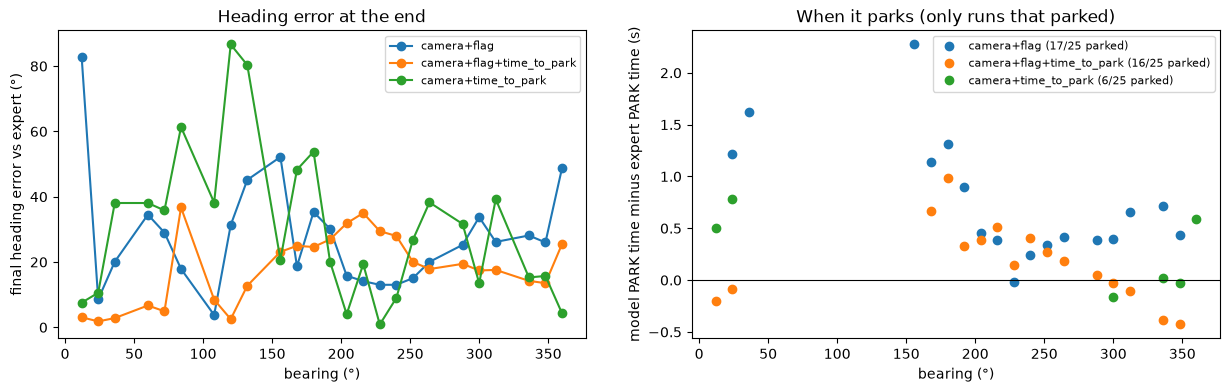

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for name in RESULTS:
    t = tests[tests.model == name].sort_values('bearing')
    ax[0].plot(t.bearing, t.final_heading_error_deg, 'o-', color=COLORS[name], label=name)
    p = t.dropna(subset=['park_time_vs_expert_s'])
    ax[1].plot(p.bearing, p.park_time_vs_expert_s, 'o', color=COLORS[name], label=f'{name} ({len(p)}/25 parked)')
ax[0].set(xlabel='bearing (°)', ylabel='final heading error vs expert (°)', title='Heading error at the end')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set(xlabel='bearing (°)', ylabel='model PARK time minus expert PARK time (s)', title='When it parks (only runs that parked)')
for a in ax: a.legend(fontsize=8)
plt.show()

### 4. Paths from above: the 4 worst and 2 best bearings for the model to build from

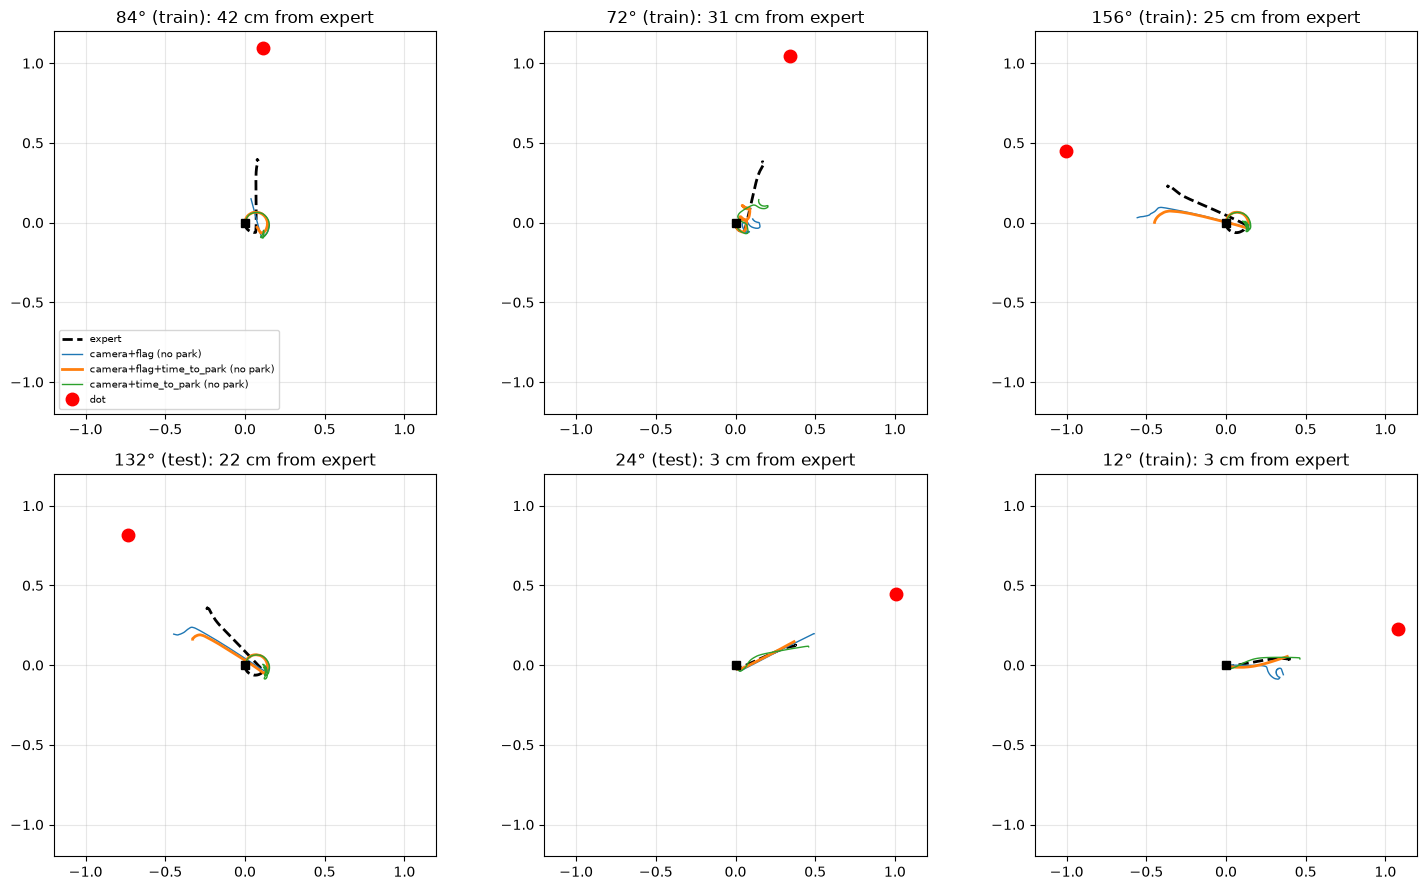

In [40]:
pick = list(order.bearing[:4]) + list(order.bearing[-2:])
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, b in zip(ax.ravel(), pick):
    e = expert_path[b]; a.plot(e[:, 0], e[:, 1], 'k--', lw=2, label='expert')
    for name in RESULTS:
        m = np.array([l['base'] for l in runs[name, b]['log']])
        a.plot(m[:, 0], m[:, 1], color=COLORS[name], lw=2 if name == MAIN else 1, label=f"{name} ({'parked' if runs[name, b]['parked'] else 'no park'})")
    d = np.deg2rad(b); a.plot(1.1 * np.cos(d), 1.1 * np.sin(d), 'o', color='red', ms=9, label='dot')
    a.plot(0, 0, 'ks', ms=6); a.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2)); a.set_aspect('equal'); a.grid(alpha=0.3)   # same scale in every panel; black square: start
    row = order.set_index('bearing').loc[b]
    a.set_title(f"{b}° ({ref[str(b)]['split']}): {row.final_error_cm:.0f} cm from expert")
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 5. Camera: how often it sees the dot, when it first sees it, and how accurate it is

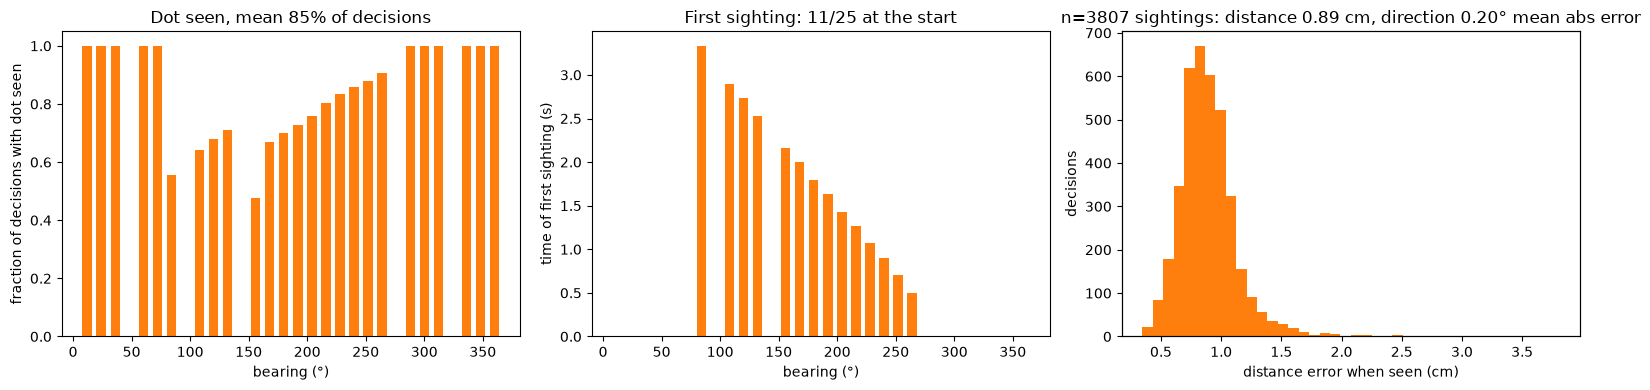

In [41]:
log = {b: runs[MAIN, b]['log'] for b in bearings}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
vis = [np.mean([l['visible'] for l in log[b]]) for b in bearings]
first = [next((l['t'] for l in log[b] if l['visible']), np.nan) for b in bearings]
ax[0].bar(bearings, vis, width=8, color='tab:orange'); ax[0].set(xlabel='bearing (°)', ylabel='fraction of decisions with dot seen', ylim=(0, 1.05),
                                                      title=f'Dot seen, mean {np.mean(vis):.0%} of decisions')
ax[1].bar(bearings, first, width=8, color='tab:orange')
ax[1].set(xlabel='bearing (°)', ylabel='time of first sighting (s)', title=f'First sighting: {sum(f == 0 for f in first)}/25 at the start')
dist_err = [100 * (l['est_dist'] - l['true_dist']) for b in bearings for l in log[b] if l['visible']]
dir_err = [(l['est_dir_deg'] - l['true_dir_deg'] + 180) % 360 - 180 for b in bearings for l in log[b] if l['visible']]
ax[2].hist(dist_err, bins=40, color='tab:orange'); ax2 = ax[2].twiny()
ax[2].set(xlabel='distance error when seen (cm)', ylabel='decisions',
          title=f'n={len(dist_err)} sightings: distance {np.mean(np.abs(dist_err)):.2f} cm, direction {np.mean(np.abs(dir_err)):.2f}° mean abs error')
ax2.set_xticks([]); plt.tight_layout(); plt.show()

### 6. Time to park: what the network predicts while driving vs the expert's real time left

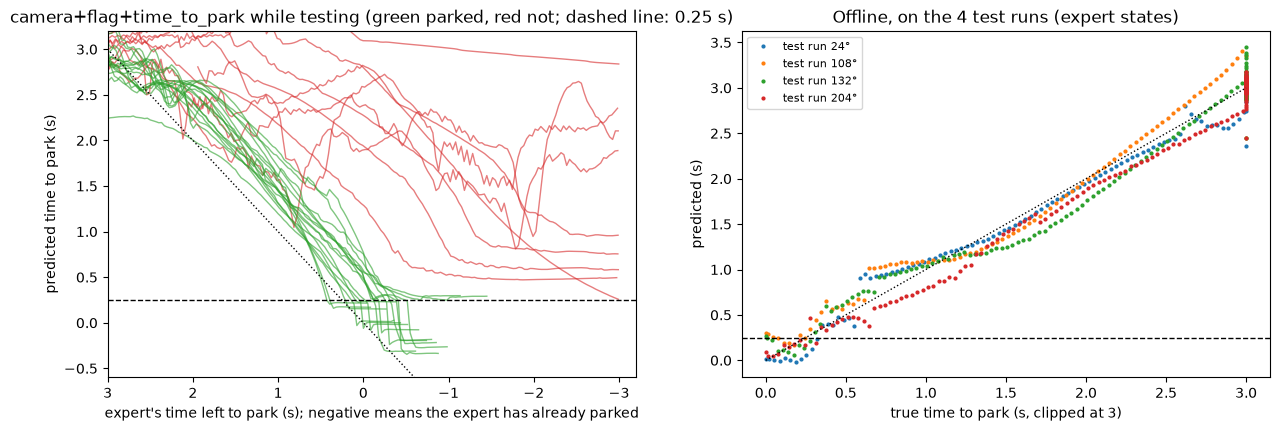

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for b in bearings:
    L = log[b]; t = np.array([l['t'] for l in L]); pred = np.array([l['ttp_s'] for l in L])
    ax[0].plot(ref[str(b)]['park_time_s'] - t, pred, color='tab:green' if runs[MAIN, b]['parked'] else 'tab:red', alpha=0.6, lw=1)
ax[0].plot([-3, 3], [-3, 3], 'k:', lw=1); ax[0].axhline(THRESH, color='k', lw=1, ls='--')
ax[0].set(xlim=(3, -3.2), ylim=(-0.6, 3.2), xlabel="expert's time left to park (s); negative means the expert has already parked",
          ylabel='predicted time to park (s)', title=f'{MAIN} while testing (green parked, red not; dashed line: 0.25 s)')
with torch.no_grad():
    for e in test:
        pred = camera_models[MAIN](torch.from_numpy(camera_inputs(e, CAMERA_MODELS[MAIN][0])))[1].numpy() * CLIP
        ax[1].plot(time_to_park(e) * CLIP, pred, '.', ms=4, label=f"test run {e['bearing']}°")
ax[1].plot([0, 3], [0, 3], 'k:', lw=1); ax[1].axhline(THRESH, color='k', lw=1, ls='--')
ax[1].set(xlabel='true time to park (s, clipped at 3)', ylabel='predicted (s)', title='Offline, on the 4 test runs (expert states)')
ax[1].legend(fontsize=8); plt.show()

## Iteration 8: scaled wheel angles

### Why: the inputs are on very different scales

The network takes its inputs as they come. The wheel angles keep adding up over a run, while the dot inputs stay between -1 and 1 and the wheel speeds between -3 and 3. The tables below show this on the training data and on two test runs.

In [43]:
import v2_results
INPUT_NAMES = ['angle FR', 'angle FL', 'angle BL', 'angle BR', 'speed FR', 'speed FL', 'speed BL', 'speed BR',
               'mean angle', 'R-L angle', 'mean speed', 'R-L speed', 'dot distance', 'dot sin', 'dot cos', 'visible']
Xtrain = np.concatenate([camera_inputs(e, [0, 1, 2, 3]) for e in train])
pd.DataFrame({'min': Xtrain.min(0), 'max': Xtrain.max(0), 'standard deviation': Xtrain.std(0)}, index=INPUT_NAMES).round(2)

,min,max,standard deviation
angle FR,-8.110000,13.36,4.90
angle FL,-7.640000,13.30,5.04
angle BL,-7.730000,13.37,5.08
angle BR,-8.190000,13.41,4.94
speed FR,-3.170000,3.18,2.02
speed FL,-3.140000,3.22,1.88
speed BL,-3.190000,3.21,1.90
speed BR,-3.190000,3.21,2.04
mean angle,-0.000000,4.76,1.73
R-L angle,-17.389999,17.27,9.35


### First and last row of two test runs, with what the expert and `camera+flag+time_to_park` output

In [44]:
w6 = np.load('models/camera_flag_ttp.npz')
def net(w, x):
    h = x
    for layer in ('shared.0', 'shared.2'):
        h = np.maximum(h @ w[layer + '.weight'].T + w[layer + '.bias'], 0)
    return h @ w['wheels.weight'].T + w['wheels.bias'], float((h @ w['park.weight'].T + w['park.bias'])[0]) * float(w['ttp_clip'])

tables = {}
for b in (24, 204):
    e = next(e for e in test if e['bearing'] == b)
    t = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == b)['archive'])['time_s']
    X = camera_inputs(e, [0, 1, 2, 3])
    cols = {}
    for i, label in ((0, 'start'), (len(X) - 1, 'end (expert parks)')):
        wheels, ttp = net(w6, X[i])
        cols[f'{label}, t = {t[i]:.2f} s'] = list(np.round(X[i], 2)) + [
            ', '.join(f'{v:.2f}' for v in e['wheels'][i]), f'{t[-1] - t[i]:.2f}',
            ', '.join(f'{v:.2f}' for v in wheels), f"{ttp:.2f} ({'PARK' if ttp <= THRESH else 'drive'})"]
    tables[f'{b}° test run'] = pd.DataFrame(cols, index=INPUT_NAMES + ['expert wheels FR, FL, BL, BR', 'expert time left (s)',
                                                                  'model wheels FR, FL, BL, BR', 'model time to park (s)'])
pd.concat(tables, axis=1)

24° test run  \
                                     start, t = 0.00 s   
angle FR                                           0.0   
angle FL                                           0.0   
angle BL                                           0.0   
angle BR                                           0.0   
speed FR                                           0.0   
speed FL                                           0.0   
speed BL                                           0.0   
speed BR                                           0.0   
mean angle                                         0.0   
R-L angle                                          0.0   
mean speed                                         0.0   
R-L speed                                          0.0   
dot distance                                      1.11   
dot sin                                           0.41   
dot cos                                           0.91   
visible                                            1.0   
expert wheels FR, FL, BL, BR  3.00, -3.00, -3.00, 3.00   
expert time left (s)                              3.35   
model wheels FR, FL, BL, BR   0.74, -0.44, -0.50, 0.81   
model time to park (s)                    2.36 (drive)   

                                                             \
                             end (expert parks), t = 3.35 s   
angle FR                                               4.77   
angle FL                                               2.29   
angle BL                                               2.29   
angle BR                                               4.73   
speed FR                                              -0.39   
speed FL                                                0.4   
speed BL                                               0.41   
speed BR                                              -0.39   
mean angle                                             3.52   
R-L angle                                              2.46   
mean speed                                             0.01   
R-L speed                                              -0.8   
dot distance                                           0.73   
dot sin                                               -0.03   
dot cos                                                 1.0   
visible                                                 1.0   
expert wheels FR, FL, BL, BR         0.00, 0.00, 0.00, 0.00   
expert time left (s)                                   0.00   
model wheels FR, FL, BL, BR        -0.46, 0.38, 0.35, -0.43   
model time to park (s)                          0.02 (PARK)   

                                         204° test run  \
                                     start, t = 0.00 s   
angle FR                                           0.0   
angle FL                                           0.0   
angle BL                                           0.0   
angle BR                                           0.0   
speed FR                                           0.0   
speed FL                                           0.0   
speed BL                                           0.0   
speed BR                                           0.0   
mean angle                                         0.0   
R-L angle                                          0.0   
mean speed                                         0.0   
R-L speed                                          0.0   
dot distance                                       0.0   
dot sin                                            0.0   
dot cos                                            0.0   
visible                                            0.0   
expert wheels FR, FL, BL, BR  -3.00, 3.00, 3.00, -3.00   
expert time left (s)                              6.11   
model wheels FR, FL, BL, BR   -0.52, 0.63, 0.52, -0.44   
model time to park (s)                    2.44 (drive)   

                                                             
                             end (exper

Reading the tables:

- The wheel angles reach about 14 at 204°, and their standard deviation over the training data is about 5. The dot inputs never leave -1 to 1 (distance up to about 1.2 m).
- At the start the model turns the right way but gives about 0.6 rad/s where the expert gives 3.
- At the end the model parks on the expert's states (time to park 0.02 s and 0.09 s).

### What changed

The six angle inputs (4 wheel angles, mean angle, right minus left angle) are standardised: the training-set mean is subtracted and the result divided by the training-set standard deviation. Nothing else changes: same inputs, outputs, loss, seed 7 and 300 epochs. The scaling is folded into the first layer when the model is saved, so the saved network takes raw inputs and runs in the same test loop. `train_v2.py` trains it; without `--scale-angles` it reproduces `camera+flag+time_to_park` exactly.

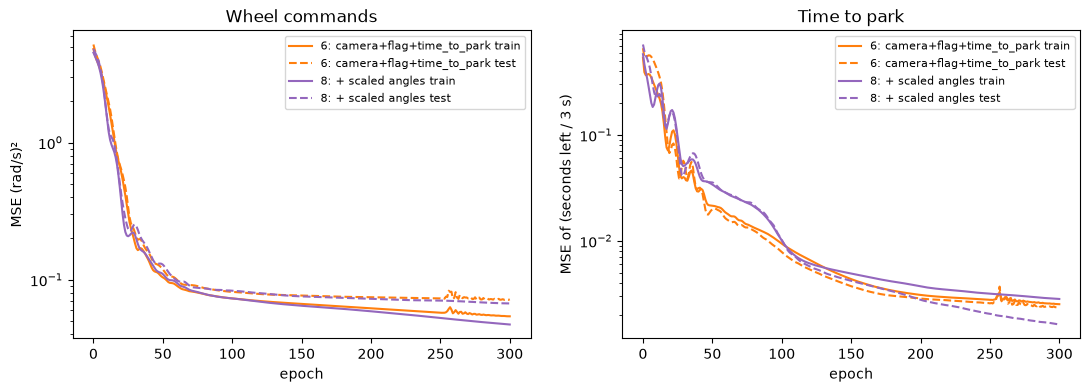

In [45]:
h6 = camera_history[camera_history.model == 'camera+flag+time_to_park']
h8 = v2_results.history('camera_flag_ttp_scaled')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, h, park_col, c in (('6: camera+flag+time_to_park', h6, 'park_loss', 'tab:orange'), ('8: + scaled angles', h8, 'time_to_park_mse', 'tab:purple')):
    ax[0].plot(h.epoch, h.train_wheel_mse, color=c, label=f'{label} train'); ax[0].plot(h.epoch, h.test_wheel_mse, '--', color=c, label=f'{label} test')
    ax[1].plot(h.epoch, h['train_' + park_col], color=c, label=f'{label} train'); ax[1].plot(h.epoch, h['test_' + park_col], '--', color=c, label=f'{label} test')
ax[0].set(title='Wheel commands', ylabel='MSE (rad/s)²'); ax[1].set(title='Time to park', ylabel='MSE of (seconds left / 3 s)')
for a in ax: a.set(xlabel='epoch', yscale='log'); a.legend(fontsize=8)
plt.show()

### Testing: 25 bearings, compared with iteration 6

In [46]:
iter8 = pd.concat([v2_results.tests('camera_flag_ttp', '6: camera+flag+time_to_park'), v2_results.tests('camera_flag_ttp_scaled', '8: + scaled angles')])
v2_results.summary(iter8)

,parked (of 25),dot in view at start (of 11),dot out of view at start (of 14),test runs (of 4),median final error (cm),median heading error (°)
model,,,,,,
6: camera+flag+time_to_park,16,7,9,2,14.5,17.8
8: + scaled angles,14,11,3,1,19.9,26.7


In [47]:
iter8.pivot(index=['split', 'bearing', 'seen_at_start'], columns='model', values='parked')

model                        6: camera+flag+time_to_park  8: + scaled angles
split bearing seen_at_start                                                 
test  24      True                                  True                True
      108     False                                False               False
      132     False                                False               False
      204     False                                 True               False
train 12      True                                  True                True
      36      True                                 False                True
      60      True                                 False                True
      72      True                                 False                True
      84      False                                False               False
      120     False                                False               False
      156     False                                False               False
      168     False                                 True               False
      180     False                                 True               False
      192     False                                 True               False
      216     False                                 True               False
      228     False                                 True                True
      240     False                                 True                True
      252     False                                 True               False
      264     False                                 True                True
      288     True                                  True                True
      300     True                                  True                True
      312     True                                  True                True
      336     True                                  True                True
      348     True                                  True                True
      360     True                                 False                True

Scaling fixed every bearing where the dot starts in view (11 of 11, up from 7) but made the search for a dot behind the robot worse (3 of 14, down from 9). The total fell from 16 to 14 of 25. One seed is not enough to tell how much of this is the change and how much is chance, which is what iteration 9 measures.

## Iterations 9 to 11: the same model with three new seeds

### What the seed changes

Iteration 8 trained once, with seed 7. The seed only sets the starting weights. Iterations 9, 10 and 11 train the same model on the same data with seeds 1, 2 and 3, and test each on the same 25 bearings. This shows how much of any result is chance.

In [48]:
SEEDS = {'seed 7 (iteration 8)': 'camera_flag_ttp_scaled', 'seed 1 (iteration 9)': 'camera_flag_ttp_scaled_seed1',
         'seed 2 (iteration 10)': 'camera_flag_ttp_scaled_seed2', 'seed 3 (iteration 11)': 'camera_flag_ttp_scaled_seed3'}
seed_tests = pd.concat([v2_results.tests(f, s) for s, f in SEEDS.items()])
seed_table = v2_results.summary(seed_tests)
seed_table

,parked (of 25),dot in view at start (of 11),dot out of view at start (of 14),test runs (of 4),median final error (cm),median heading error (°)
model,,,,,,
seed 7 (iteration 8),14,11,3,1,19.9,26.7
seed 1 (iteration 9),0,0,0,0,12.5,21.7
seed 2 (iteration 10),4,4,0,0,44.3,15.5
seed 3 (iteration 11),21,8,13,4,20.6,3.6


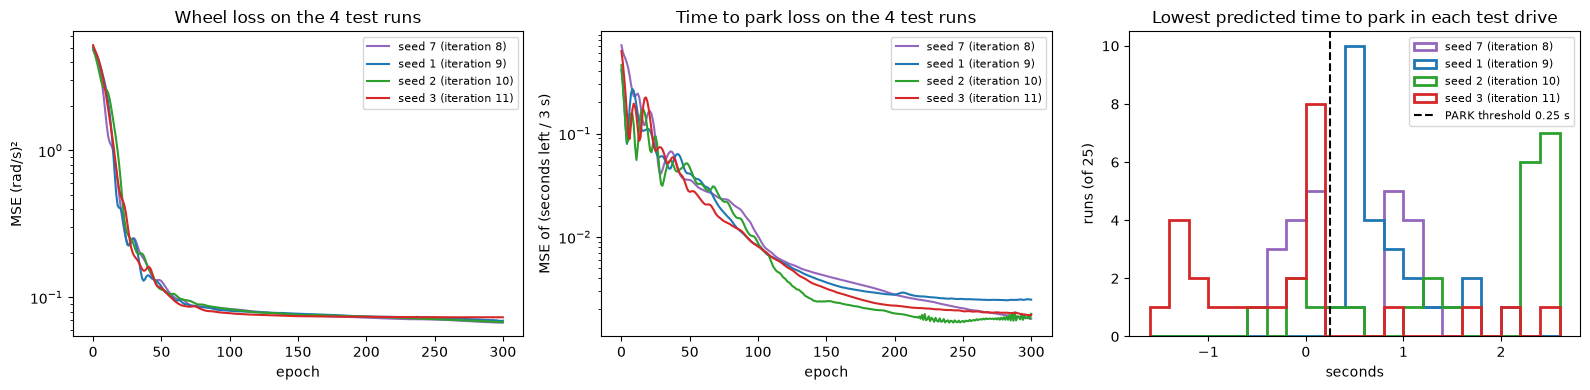

In [49]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for (label, f), c in zip(SEEDS.items(), ['tab:purple', 'tab:blue', 'tab:green', 'tab:red']):
    h = v2_results.history(f)
    ax[0].plot(h.epoch, h.test_wheel_mse, color=c, label=label); ax[1].plot(h.epoch, h.test_time_to_park_mse, color=c, label=label)
    mins = [min(l['ttp_s'] for l in json.loads(Path(f'camera_loop/{f}/run_{b}.json').read_text())['log']) for b in ref]
    ax[2].hist(mins, bins=np.arange(-1.6, 2.8, 0.2), histtype='step', lw=2, color=c, label=label)
ax[0].set(title='Wheel loss on the 4 test runs', xlabel='epoch', yscale='log', ylabel='MSE (rad/s)²')
ax[1].set(title='Time to park loss on the 4 test runs', xlabel='epoch', yscale='log', ylabel='MSE of (seconds left / 3 s)')
ax[2].axvline(THRESH, color='k', ls='--', label='PARK threshold 0.25 s')
ax[2].set(title='Lowest predicted time to park in each test drive', xlabel='seconds', ylabel='runs (of 25)')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [50]:
pd.DataFrame({'ended within 20 cm of the expert (of 25)': seed_tests.groupby('model', sort=False).final_error_cm.apply(lambda e: int((e < 20).sum())),
              'parked (of 25)': seed_table['parked (of 25)']})

,ended within 20 cm of the expert (of 25),parked (of 25)
model,,
seed 7 (iteration 8),13,14
seed 1 (iteration 9),19,0
seed 2 (iteration 10),8,4
seed 3 (iteration 11),12,21


### What the seeds show

- Parked counts run from 0 to 21 of 25 with nothing changed but the seed. A difference of a few runs between two single-seed results means nothing.
- The losses on the test runs are almost the same for all four seeds. Training looks equally good offline.
- The driving is better than the parked count suggests. Seed 1 ends within 20 cm of the expert in 19 of 25 runs and parks in none: its predicted time to park never drops below 0.35 s, so PARK never fires.
- So the fixed 0.25 s threshold decides most of the outcome. The model has never seen what being parked looks like, because every expert run stops at the PARK row. Iteration 12 adds that.

## Iteration 12: 100 rows after the expert parks

Every expert run stops at its PARK row, so the network never sees what being parked looks like. Iteration 12 adds 100 rows (3.3 s) after PARK to every training run. In those rows the wheel command is 0 and the time to park is 0.

The rows come from replaying the expert in the fast simulator past its PARK command (`policy_replay` with `"expert_tail_steps": 3400`), with the wheels stopped and the arm held. Before PARK the replay matches the saved expert data to 3e-8. The camera inputs for the new rows come from the same camera, detector and tracker (`expert_tail.py`). Everything else is iteration 8. Because the seeds vary so much, it is trained and tested with all four seeds (7, 1, 2, 3).

In [51]:
tail = np.load('park_tail/tail_24.npz')
print(f"rows per run: {len(tail['x'])}, from {tail['time_since_park_s'][0]:.2f} s to {tail['time_since_park_s'][-1]:.2f} s after PARK")
pd.DataFrame({'largest wheel speed (rad/s)': [float(np.abs(np.load(f)['x'][:, 4:8]).max()) for f in sorted(Path('park_tail').glob('tail_*.npz'))],
              'dot visible (fraction of rows)': [float(np.load(f)['camera'][:, 3].mean()) for f in sorted(Path('park_tail').glob('tail_*.npz'))]},
             index=[f.stem for f in sorted(Path('park_tail').glob('tail_*.npz'))]).describe().loc[['mean', 'min', 'max']].round(2)

rows per run: 100, from 0.01 s to 3.31 s after PARK


,largest wheel speed (rad/s),dot visible (fraction of rows)
mean,0.20,0.56
min,0.06,0.00
max,0.39,1.00


### Iteration 12: results over four seeds

In [52]:
pairs = {s: (f'camera_flag_ttp_scaled{"" if s == 7 else f"_seed{s}"}', f'camera_flag_ttp_scaled_tail100{"" if s == 7 else f"_seed{s}"}') for s in (7, 1, 2, 3)}
rows = []
for s, (before, after) in pairs.items():
    for label, f in (('8 to 11: scaled', before), ('12: + parked rows', after)):
        d = v2_results.tests(f)
        mins = [min(l['ttp_s'] for l in json.loads(Path(f'camera_loop/{f}/run_{b}.json').read_text())['log']) for b in ref]
        rows.append({'seed': s, 'model': label, 'parked (of 25)': int(d.parked.sum()),
                     'dot in view at start (of 11)': int(d[d.seen_at_start].parked.sum()), 'dot out of view at start (of 14)': int(d[~d.seen_at_start].parked.sum()),
                     'ended within 20 cm (of 25)': int((d.final_error_cm < 20).sum()), 'median final error (cm)': round(d.final_error_cm.median(), 1),
                     'median lowest time to park (s)': round(float(np.median(mins)), 2)})
iter12 = pd.DataFrame(rows).set_index(['seed', 'model'])
iter12

parked (of 25)  dot in view at start (of 11)  \
seed model                                                             
7    8 to 11: scaled                14                            11   
     12: + parked rows               9                             2   
1    8 to 11: scaled                 0                             0   
     12: + parked rows              12                             2   
2    8 to 11: scaled                 4                             4   
     12: + parked rows               2                             1   
3    8 to 11: scaled                21                             8   
     12: + parked rows               0                             0   

                        dot out of view at start (of 14)  \
seed model                                                 
7    8 to 11: scaled                                   3   
     12: + parked rows                                 7   
1    8 to 11: scaled                                   0   
     12: + parked rows                                10   
2    8 to 11: scaled                                   0   
     12: + parked rows                                 1   
3    8 to 11: scaled                                  13   
     12: + parked rows                                 0   

                        ended within 20 cm (of 25)  median final error (cm)  \
seed model                                                                    
7    8 to 11: scaled                            13                     19.9   
     12: + parked rows                          22                     11.2   
1    8 to 11: scaled                            19                     12.5   
     12: + parked rows                          19                     13.0   
2    8 to 11: scaled                             8                     44.3   
     12: + parked rows                           9                     28.9   
3    8 to 11: scaled                            12                     20.6   
     12: + parked rows                           3                     39.1   

                        median lowest time to park (s)  
seed model                                              
7    8 to 11: scaled                              0.15  
     12: + parked rows                            0.47  
1    8 to 11: scaled                              0.68  
     12: + parked rows                            0.28  
2    8 to 11: scaled                              2.31  
     12: + parked rows                            1.43  
3    8 to 11: scaled                             -0.10  
     12: + parked rows                            2.40

In [53]:
iter12.groupby('model').agg(['mean', 'min', 'max'])[['parked (of 25)', 'ended within 20 cm (of 25)']].round(2)

parked (of 25)         ended within 20 cm (of 25)        
                            mean min max                       mean min max
model                                                                      
12: + parked rows           5.75   0  12                      13.25   3  22
8 to 11: scaled             9.75   0  21                      13.00   8  19

Reading the results:

- Averaged over the four seeds, iteration 12 parked 5.75 of 25 against 9.75 before. The seeds still range from 0 to 12.
- Runs ending within 20 cm of the expert hardly changed (13.25 against 13 on average).
- The training losses are not comparable with iteration 8, because a third of the rows are now easy parked rows.
- The parked rows did not make PARK reliable. The bigger problem is that each seed learns a different time-to-park scale, and one fixed threshold cannot suit them all.

## Iteration 13: wheel encoders instead of simulator wheel values

### Iteration 13: what changed

Until now the 12 wheel inputs came straight from the simulator's joint angles and joint speeds. Iteration 13 reads them from simulated wheel encoders (`sensors.py`):

- Each wheel has an incremental encoder with 4096 counts per revolution (an assumed, common 12-bit resolution). The angle moves in steps of 2π/4096 rad.
- Speed is not measured directly. It is the change in counted angle since the previous reading, divided by 1/30 s, so it lags the true speed.
- The 12 inputs are built from these readings exactly as before, and the tracker uses the encoder speeds when the dot is hidden.

The network now sees only sensor readings: wheel encoders and the camera. The outputs are unchanged (four wheel speed commands and time to park). Everything else is iteration 12, trained and tested with the same four seeds.

`sensors.py` collects the sensors in one `Sensors` class. An IMU can be added there with a `reset()` and a `read(frame)`, and its readings added to the inputs.

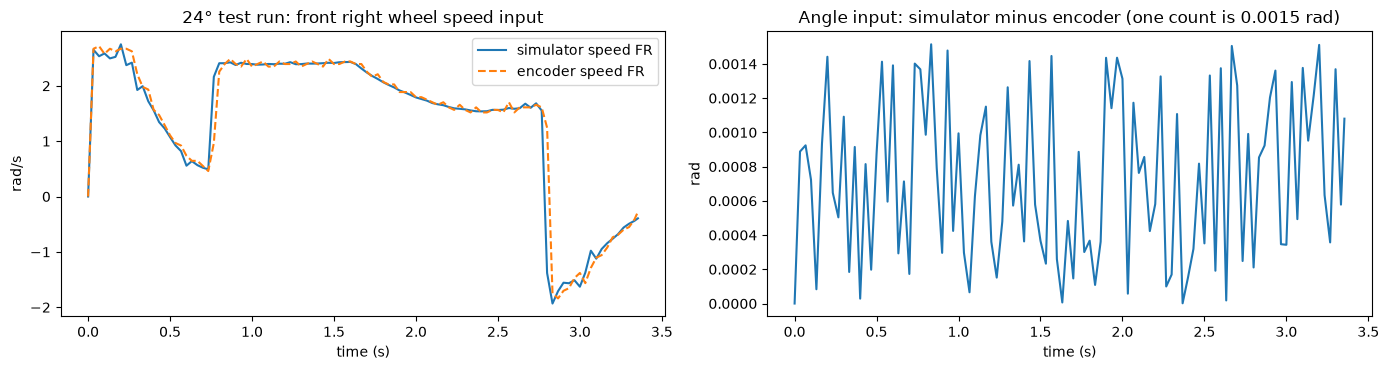

In [54]:
import sensors
e24 = next(e for e in test if e['bearing'] == 24)
a24 = np.load(DATA / next(r for r in episodes if r['bearing_deg'] == 24)['archive'])
enc = sensors.WheelEncoders.features_for_run(a24['joint_positions'][:, :4])
t24 = a24['time_s']
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(t24, e24['x'][:, 4], label='simulator speed FR'); ax[0].plot(t24, enc[:, 4], '--', label='encoder speed FR')
ax[0].set(xlabel='time (s)', ylabel='rad/s', title='24° test run: front right wheel speed input'); ax[0].legend()
ax[1].plot(t24, e24['x'][:, 0] - enc[:, 0])
ax[1].set(xlabel='time (s)', ylabel='rad', title='Angle input: simulator minus encoder (one count is 0.0015 rad)')
plt.tight_layout(); plt.show()

### Iteration 13: results over four seeds

In [55]:
rows = []
for s in (7, 1, 2, 3):
    suffix = '' if s == 7 else f'_seed{s}'
    for label, f in (('12: simulator wheel values', 'camera_flag_ttp_scaled_tail100' + suffix), ('13: wheel encoders', 'camera_flag_ttp_scaled_tail100_encoders' + suffix)):
        d = v2_results.tests(f)
        rows.append({'seed': s, 'model': label, 'parked (of 25)': int(d.parked.sum()),
                     'dot in view at start (of 11)': int(d[d.seen_at_start].parked.sum()), 'dot out of view at start (of 14)': int(d[~d.seen_at_start].parked.sum()),
                     'test runs (of 4)': int(d[d.split == 'test'].parked.sum()),
                     'ended within 20 cm (of 25)': int((d.final_error_cm < 20).sum()), 'median final error (cm)': round(d.final_error_cm.median(), 1)})
iter13 = pd.DataFrame(rows).set_index(['seed', 'model'])
iter13

parked (of 25)  dot in view at start (of 11)  \
seed model                                                                      
7    12: simulator wheel values               9                             2   
     13: wheel encoders                      24                            10   
1    12: simulator wheel values              12                             2   
     13: wheel encoders                      22                            10   
2    12: simulator wheel values               2                             1   
     13: wheel encoders                      11                             8   
3    12: simulator wheel values               0                             0   
     13: wheel encoders                      15                            11   

                                 dot out of view at start (of 14)  \
seed model                                                          
7    12: simulator wheel values                                 7   
     13: wheel encoders                                        14   
1    12: simulator wheel values                                10   
     13: wheel encoders                                        12   
2    12: simulator wheel values                                 1   
     13: wheel encoders                                         3   
3    12: simulator wheel values                                 0   
     13: wheel encoders                                         4   

                                 test runs (of 4)  ended within 20 cm (of 25)  \
seed model                                                                      
7    12: simulator wheel values                 1                          22   
     13: wheel encoders                         4                          24   
1    12: simulator wheel values                 2                          19   
     13: wheel encoders                         3                          14   
2    12: simulator wheel values                 0                           9   
     13: wheel encoders                         1                          14   
3    12: simulator wheel values                 0                           3   
     13: wheel encoders                         1                          14   

                                 median final error (cm)  
seed model                                                
7    12: simulator wheel values                     11.2  
     13: wheel encoders                              7.4  
1    12: simulator wheel values                     13.0  
     13: wheel encoders                             18.5  
2    12: simulator wheel values                     28.9  
     13: wheel encoders                             17.1  
3    12: simulator wheel values                     39.1  
     13: wheel encoders                             17.3

In [56]:
iter13.groupby('model').agg(['mean', 'min', 'max'])[['parked (of 25)', 'ended within 20 cm (of 25)', 'median final error (cm)']].round(1)

parked (of 25)         ended within 20 cm (of 25)  \
                                     mean min max                       mean   
model                                                                          
12: simulator wheel values            5.8   0  12                       13.2   
13: wheel encoders                   18.0  11  24                       16.5   

                                   median final error (cm)              
                           min max                    mean   min   max  
model                                                                   
12: simulator wheel values   3  22                    23.0  11.2  39.1  
13: wheel encoders          14  24                    15.1   7.4  18.5

In [57]:
best = v2_results.tests('camera_flag_ttp_scaled_tail100_encoders', '13: wheel encoders, seed 7')
best[['split', 'bearing', 'seen_at_start', 'parked', 'final_error_cm', 'heading_error_deg', 'park_time_vs_expert_s']].sort_values('final_error_cm', ascending=False).round(2)

,split,bearing,seen_at_start,parked,final_error_cm,heading_error_deg,park_time_vs_expert_s
0,train,12,True,False,25.38,23.98,NaN
3,train,60,True,True,15.49,11.44,-0.44
10,train,168,False,True,10.16,7.20,-0.60
9,train,156,False,True,9.50,7.06,-0.36
12,train,192,False,True,9.20,5.01,-0.90
22,train,336,True,True,9.00,9.17,0.25
14,train,216,False,True,8.93,7.58,-0.98
23,train,348,True,True,8.73,17.57,-0.96
13,test,204,False,True,8.68,8.25,-0.98
8,test,132,False,True,8.31,5.77,0.26


Reading the results:

- With encoders the model parked a mean of 18 of 25 over the four seeds (11 to 24), against 5.75 (0 to 12) with simulator wheel values. Every seed improved.
- Seed 7 parks 24 of 25 with a median final error of 7.4 cm, and all 4 test runs park within 9 cm of the expert. The model given the true dot position (iteration 3) parked 23 of 25.
- We do not know yet why encoders help this much. The encoder speed inputs are not smoother row to row than the simulator's (0.156 against 0.166 rad/s mean change). The tracker also switched to encoder speeds, so two things changed together. Testing each separately would show which one matters.
- The seeds still differ (11 to 24 parked), so results should be reported over several seeds.

### Iteration 13: 3D replay of seed 7

Solid robot: the iteration 13 model (seed 7), driving from the camera and wheel encoders. Cyan ghost: the expert. All 25 bearings are in the dropdown, labelled TRAIN or TEST. The panel on the right shows the predicted time to park, the wheel commands and the park and final differences from the expert.

These runs were repeated with the full robot state logged (`FULL_FRAMES=1`, results in `camera_loop_frames/`). The table under the player checks that they end where the runs above ended.

<a href="/files/driving_v2/closed_loop_native/viewer_iter13_seed7.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [58]:
path = replay_v2.build_camera_viewer('camera_flag_ttp_scaled_tail100_encoders', 'iter13_seed7')
lazy_player('/files/driving_v2/closed_loop_native/' + path.name)

In [59]:
check = []
for b in v2_results.REF:
    a = json.loads(Path(f'camera_loop/camera_flag_ttp_scaled_tail100_encoders/run_{b}.json').read_text())
    c = json.loads(Path(f'camera_loop_frames/camera_flag_ttp_scaled_tail100_encoders/run_{b}.json').read_text())
    check.append(dict(bearing=int(b), parked_before=a['parked'], parked_now=c['parked'],
                      final_position_difference_mm=1000 * float(np.hypot(*np.subtract(a['final_base'], c['final_base'])))))
pd.DataFrame(check).sort_values('bearing').set_index('bearing').T.round(3)

bearing,12,24,36,60,72,84,108,120,132,156,...,228,240,252,264,288,300,312,336,348,360
parked_before,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
parked_now,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
final_position_difference_mm,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Arm: plan and expected results

### What the arm network will do

The expert works in two phases. While it drives, it holds the arm still. Once it has parked, it reaches for the dot with the arm and stops when the gripper is within 1 cm of it. The arm network copies the second phase. It takes over at PARK, from the iteration 13 driving model.

| | Count | Details |
|---|---|---|
| Input: arm joint angles | 7 | arm encoders (`sensors.ArmEncoders`): absolute angle in whole ticks, 3,686,400 per turn on joints 1 to 4 and 2,534,400 on joints 5 to 7 (Kinova datasheet for the Jaco 2 actuators) |
| Input: arm joint speeds | 7 | change in encoder angle over 1/30 s |
| Input: dot x, y and height | 3 | camera and tracker, which now keeps the height |
| Input: dot visible flag | 1 | camera |
| Input: time since PARK | 1 | clock |
| Output: arm joint torques | 7 | clipped at ±30 Nm, like the expert's |
| Output: time to stop | 1 | stop when it is 0.25 s or less, latched |

- The network is a 2×64 ReLU MLP. Inputs and each torque are standardised, and the scaling is folded into the weights, as in iteration 8.
- It runs at 30 Hz, like the driving network. Each torque command is held for 33 ms while the physics runs at 1 kHz.
- The fingers do not move, so they are not inputs.
- Until PARK the arm is held by the same hold controller as the expert. After PARK there is no hold controller: the network's torques move the arm and also keep it up after stop. A run ends 0.5 s after stop, or 1 s after the expert's stop time.
- Training rows run from the expert's PARK to 0.5 s after the expert's stop, with time to stop 0 after the stop. There are 21 training runs, one per training bearing.
- The loss is the one used for driving: mean squared error on the outputs with equal weight per run, plus the weighted time-to-stop term. Results are also reported as the number of bearings where the gripper ends within 1 cm of the dot.
- Every version is trained with four seeds (7, 1, 2 and 3).

### Smoke tests before training

| Test | What it checks | Expected result |
|---|---|---|
| 1. Iteration 13, seed 7, through the changed simulator | the change does not affect driving | the same final positions, to the millimetre |
| 2. The expert's own 1 kHz arm torques sent through the new arm input | the arm input is wired correctly | the same reach as the expert, gripper within 1 cm |
| 3. The expert's torques averaged over each 33 ms and held | 30 Hz is fast enough for the arm | gripper within 1 cm on most bearings; if not, the arm network moves to 100 Hz |
| 5. Dot in the camera view after PARK | where the dot inputs come from during the reach | probably out of view, so the tracker's estimate is used; this is fine because the robot does not move |
| 6. Train on one bearing and test it in the simulator | the inputs carry enough information for one reach | the gripper ends within 1 cm on that bearing |

Test 4, the expert's torques against the real actuator limits, is not run: we take the expert's torques as correct.

### Expected results and what we do if they fail

- The reach should be easier than driving to learn. The dot does not move once the robot has parked, and the arm starts from almost the same pose every time.
- The risk is drift: a small torque error at the shoulder moves the gripper a long way. If the reach drifts, the next steps are the joint torque sensors as 7 more inputs (±0.4 Nm), then extra training runs around the expert's path (DART).
- If the network does not stop, we add more rows after the expert's stop, as iteration 12 did for PARK.
- Later, the arm network will run for the whole run with a parked flag as an input, so the hold controller before PARK is replaced as well.

### Arm: what the expert does

The expert's full runs were recorded for all 30 bearings with the fast simulator's expert collector, every 1 ms, from the start to the expert's stop (`v2_sensors/arm/data/expert_full`, 18 s to collect). Their PARK times match the driving data to the millisecond.

- The expert stops when the gripper is within 1 cm of the dot and more than 8 s have passed since the start (`controller.cpp:91`). So 23 of the 30 runs stop at exactly 8.0 s, however early the gripper got there. The arm network therefore gets the time since the start as an input, as well as the time since PARK.
- On 204° and 228° the expert does not get within 1 cm. It stalls about 11.5 mm from the dot and stops 3 s later. 204° is a test bearing.
- The brief (slide 4) names the outputs `torque_arm` and `wheel_cmds`. The arm network therefore outputs the 7 torques directly. A network that outputs target angles for a fixed PD loop would change the command type.
- The wheels are different. A wheel command is a speed, and the simulator turns it into torque every 1 ms with 30 × (commanded speed − actual speed) (`physics.cpp:106`). This is the simulator's motor model, and it keeps correcting while a 30 Hz command is held. The arm torques go to the joints as they are, with nothing in between.

### Arm: smoke tests

The stepping server (`sensor_parking`) has new options, and without them it behaves as before:

- `arm`: after PARK the client's 7 torques drive the arm and `stop` ends the run 0.5 s later. Until the first arm command after PARK the hold controller keeps the arm.
- `expert_drive`: the expert drives and parks itself, so the arm can be tested on its own.
- `expert_arm_hz`: the expert's own arm controller runs after PARK, but its torque is only taken at this rate and held in between.

| Test | Result |
|---|---|
| 1. Iteration 13, seed 7, through the changed server | the same 24 of 25 parked, final positions identical to the millimetre |
| 2. The expert's own 1 kHz torques sent through the arm input | the expert's reach reproduced exactly on all 30 bearings |
| 3. The expert's torques averaged over each 33 ms and held, without feedback | the gripper ends 0.2 to 1.2 m from the dot |
| 3b. The expert's own controller, its torque taken at a lower rate and held | works only at 1 kHz (table below) |
| 5. Dot in view after PARK | in view on 9 of the 24 parked runs; otherwise the tracker's estimate is within about 1 to 4 cm |

Test 4, the expert's torques against the real actuator limits, is not run, because we take the expert's torques as correct.

In [60]:
ARM = Path('../arm')
t2 = pd.DataFrame(json.loads((ARM / 'smoke/test2_1khz.json').read_text()))
rows = []
for hz in (1000, 500, 250, 100, 30):
    d = pd.DataFrame(json.loads((ARM / f'smoke/test3b_expert_{hz}hz.json').read_text()))
    rows.append({'rate (Hz)': hz, 'matches the expert (of 30)': int((d.at_stop_mm <= np.maximum(10, t2.expert_stop_mm + 1)).sum()),
                 'median distance at the expert stop (mm)': round(d.at_stop_mm.median(), 1),
                 'largest distance (mm)': round(d.at_stop_mm.max(), 1)})
print('Test 2: largest difference from the expert at its stop (mm):', float((t2.at_stop_mm - t2.expert_stop_mm).abs().max()))
pd.DataFrame(rows).set_index('rate (Hz)')

Test 2: largest difference from the expert at its stop (mm): 1.7763568394002505e-15


,matches the expert (of 30),median distance at the expert stop (mm),largest distance (mm)
rate (Hz),,,
1000,30,4.2,11.7
500,0,65.1,95.9
250,0,452.1,629.6
100,0,595.8,814.4
30,0,637.8,55856.2


Test 3b is the main finding. The expert's arm controller has stiff gains (100 on the angle error, 30 on the speed) on light joints. Its torque is right for one millisecond. Held for 2 ms the arm overshoots, and held for 33 ms it swings away from the dot.

### Arm: 30 Hz torque networks (iterations 14 to 16)

#### Iterations 14 to 16: plan and expected results

This entry was added after the runs. The expectation below is the one stated before training.

Three networks output the 7 arm torques once per 30 Hz decision (`v2_sensors/arm/train_arm.py`), to see what happens when torques are held for 33 ms:

| Iteration | Model | Trained on | Torque target |
|---|---|---|---|
| 14 | `arm30_sample_b12` | bearing 12 only | the expert's torque at the decision step |
| 15 | `arm30_sample` | the 21 training bearings | the expert's torque at the decision step |
| 16 | `arm30_mean` | the 21 training bearings | the expert's torque averaged over the 33 ms until the next decision |

- 19 inputs: arm encoder angles (7) and speeds (7), the dot in the robot frame (3, from the simulator for this test, not the camera), time since PARK and time since the start.
- Outputs: the 7 torques and the time to stop. 2×64 ReLU, 5,960 parameters, inputs and torques standardised, Adam with learning rate 0.01, 300 full-batch epochs, seed 7.
- Rows: every 30 Hz decision from the expert's PARK to its stop, about 110 per run.
- Loss: torque mean squared error (in standardised units) plus time-to-stop mean squared error, each training run counted equally.
- Test: in the simulator with `expert_drive`. The expert drives and parks, then only the arm network moves the arm (`v2_sensors/arm/test_arm.py`), on the 25 bearings.
- Iteration 14 checks whether a network that fits one reach almost exactly can repeat it in the simulator.

Expected: all three fail, because test 3b showed the expert's own torques fail when held for 33 ms. A network that copies the expert's torque at each state should fail the same way.

In [61]:
rows = []
for name in ('arm30_sample_b12', 'arm30_sample', 'arm30_mean'):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        t0 = r['log'][0]['t']
        rows.append(dict(model=name, split=r['split'], bearing=r['bearing'], train_torque_loss=h['train_torque_mse'],
                         test_torque_loss=np.nan if name.endswith('_b12') else h['test_torque_mse'],
                         at_park_mm=r['log'][0]['ee_mm'], closest_mm=r['min_mm'], at_expert_stop_mm=r['at_expert_stop_mm'],
                         s_until_1m=next((l['t'] - t0 for l in r['log'] if l['ee_mm'] > 1000), np.nan)))
arm30 = pd.DataFrame(rows)
arm30.groupby('model', sort=False).agg(**{
    'runs': ('bearing', 'size'), 'train torque loss': ('train_torque_loss', 'first'), 'test torque loss': ('test_torque_loss', 'first'),
    'within 1 cm at the expert stop': ('at_expert_stop_mm', lambda s: int((s <= 10).sum())),
    'median distance at PARK (mm)': ('at_park_mm', 'median'), 'median closest (mm)': ('closest_mm', 'median'),
    'median time until 1 m away (s)': ('s_until_1m', 'median')}).round(3)

,runs,train torque loss,test torque loss,within 1 cm at the expert stop,median distance at PARK (mm),median closest (mm),median time until 1 m away (s)
model,,,,,,,
arm30_sample_b12,1,0.000,NaN,0,224.522,161.429,0.533
arm30_sample,25,0.091,1.456,0,227.017,188.806,0.534
arm30_mean,25,0.030,0.062,0,227.017,221.130,0.467


#### Iterations 14 to 16: loss curves

Torque loss is in standardised units. Iteration 14 is trained on one bearing, so it has no test curve.

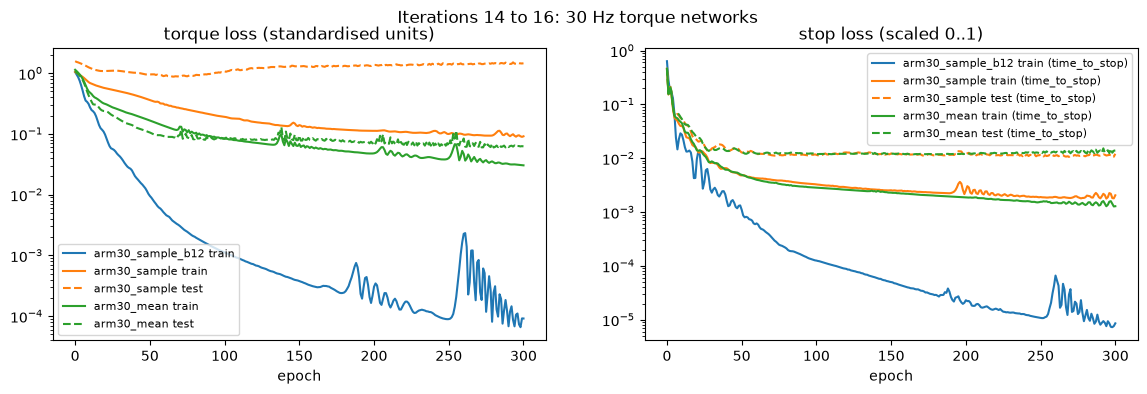

In [62]:
def arm_loss_plot(names, title):
    """Per-epoch training (solid) and test (dashed) losses of arm networks, from models/NAME_history.json."""
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    for name in names:
        h = pd.DataFrame(json.loads((ARM / f'models/{name}_history.json').read_text()))
        line, = ax[0].plot(h.epoch, h.train_torque_mse, label=f'{name} train')
        stop = 'time_to_stop' if 'train_time_to_stop_mse' in h else 'distance'      # what the stop head learns
        ax[1].plot(h.epoch, h[f'train_{stop}_mse'], color=line.get_color(), label=f'{name} train ({stop})')
        if not name.endswith('_b12'):               # trained on one bearing: no test curve
            ax[0].plot(h.epoch, h.test_torque_mse, '--', color=line.get_color(), label=f'{name} test')
            ax[1].plot(h.epoch, h[f'test_{stop}_mse'], '--', color=line.get_color(), label=f'{name} test ({stop})')
    for a, t in zip(ax, ('torque loss (standardised units)', 'stop loss (scaled 0..1)')):
        a.set(yscale='log', xlabel='epoch', title=t); a.legend(fontsize=8)
    fig.suptitle(title); plt.show()

arm_loss_plot(['arm30_sample_b12', 'arm30_sample', 'arm30_mean'], 'Iterations 14 to 16: 30 Hz torque networks')

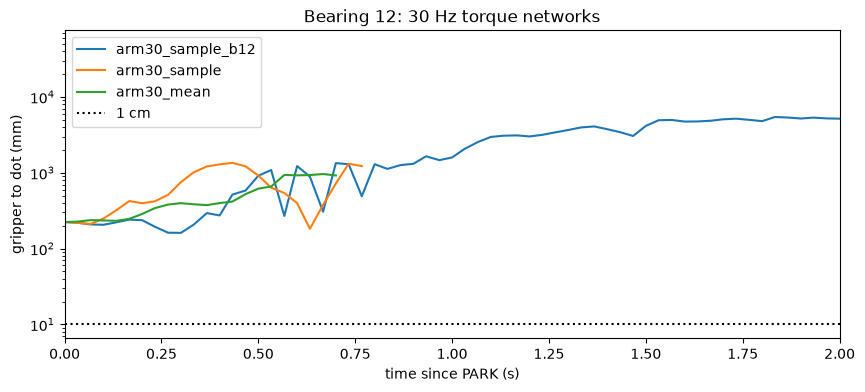

In [63]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ('arm30_sample_b12', 'arm30_sample', 'arm30_mean'):
    r = next(r for r in json.loads((ARM / f'results/{name}.json').read_text()) if r['bearing'] == 12)
    ax.plot([l['t'] - r['log'][0]['t'] for l in r['log']], [l['ee_mm'] for l in r['log']], label=name)
ax.axhline(10, color='k', ls=':', label='1 cm')
ax.set(yscale='log', xlabel='time since PARK (s)', ylabel='gripper to dot (mm)', title='Bearing 12: 30 Hz torque networks', xlim=(0, 2))
ax.legend(); plt.show()

Reading the results:

- No network gets the gripper within 1 cm. The gripper starts about 22.5 cm from the dot at PARK. Each network moves it a few centimetres closer, then the arm swings away and passes 1 m from the dot about 0.5 s after PARK.
- The network trained on bearing 12 alone fits its training rows almost exactly (torque loss 0.0001) and still swings away after 0.53 s. So the failure comes from holding the torques for 33 ms, not from the network learning badly.
- The averaged torques are much easier to learn (test loss 0.06 against 1.46), but they fail in the same way.
- Iteration 15 overfits: its test loss is lowest at epoch 70 (0.87) and rises to 1.46 by epoch 300. Iteration 16 does not: its test loss stays near 0.06.
- This matches test 3b: the expert's own controller fails when its torque is held for 33 ms.

What this means for the arm: to output torques, as the expert does, the arm network has to run at the expert's rate, 1 kHz. The next test is the same network at 1 kHz.

#### Iteration 14: 3D replay (`arm30_sample_b12`)

Solid robot: the arm network's run. Cyan ghost: the expert's own run for the same bearing. The expert drives and parks in both runs, so the two robots overlap until PARK. After PARK the solid arm gets only the network's torques. The side table shows the 7 torques of both. A run is cut once the gripper is more than 1.5 m from the dot after PARK.

The line under the player gives the distance from each gripper to the dot in mm, for the network and the expert. This is the distance the expert itself uses: from its end-effector frame (`robot_j2s7s300_end_effector`) to the dot centre. After PARK the dot is never more than 0.53 m from the shoulder, inside the expert's 0.85 m reach limit, so the expert always aims at the dot centre itself.

<a href="/files/arm/results/viewer_arm30_sample_b12.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [64]:
import sys
sys.path.insert(0, str(ARM.resolve()))
import replay_arm
path = replay_arm.build_viewer('arm30_sample_b12')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 15: 3D replay (`arm30_sample`)

<a href="/files/arm/results/viewer_arm30_sample.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [65]:
path = replay_arm.build_viewer('arm30_sample')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 16: 3D replay (`arm30_mean`)

<a href="/files/arm/results/viewer_arm30_mean.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [66]:
path = replay_arm.build_viewer('arm30_mean')
lazy_player('/files/arm/results/' + path.name)

### Arm: 1 kHz torque network (iteration 17)

#### Iteration 17: plan and expected results

This entry was added after the run. The expectation below is the one stated before training.

The same network as iteration 15 (`arm30_sample`), with one change: it runs every 1 ms, the rate at which the expert outputs its torques (`train_arm.py --hz 1000`).

- Rows: every 1 ms from the expert's PARK to its stop, 75,949 rows over the 21 training runs.
- The encoder speed is the change in angle over 1 ms. The dot position and the times are read every 1 ms too.
- Test: the network's torques are sent every 1 ms through the arm input (`test_arm.py`), on the 25 bearings, with the expert driving.

Expected: the arm should stay stable, because test 3b showed the expert's own torques work at 1 kHz. The risk is drift: the expert's torque depends on a target angle it updates internally every 1 ms (`controller.cpp:81-85`), which the network cannot see, so it has to approximate it from the angles, speeds and times.

In [67]:
rows = []
for name in ('arm30_sample', 'arm1k'):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        rows.append(dict(model=name, split=r['split'], bearing=r['bearing'], train=h['train_torque_mse'], test=h['test_torque_mse'],
                         closest_mm=r['min_mm'], at_expert_stop_mm=r['at_expert_stop_mm'], stopped=r['stop_s'] is not None,
                         stop_vs_expert_s=np.nan if r['stop_s'] is None else r['stop_s'] - r['expert_stop_s']))
arm1k = pd.DataFrame(rows)
arm1k.groupby('model', sort=False).agg(**{
    'train torque loss': ('train', 'first'), 'test torque loss': ('test', 'first'),
    'median closest (mm)': ('closest_mm', 'median'), 'closest within 1 cm (of 25)': ('closest_mm', lambda s: int((s <= 10).sum())),
    'median at the expert stop (mm)': ('at_expert_stop_mm', 'median'), 'stopped (of 25)': ('stopped', 'sum'),
    'median stop vs expert (s)': ('stop_vs_expert_s', 'median')}).round(3)

,train torque loss,test torque loss,median closest (mm),closest within 1 cm (of 25),median at the expert stop (mm),stopped (of 25),median stop vs expert (s)
model,,,,,,,
arm30_sample,0.091,1.456,188.806,0,7082.420,6,-2.648
arm1k,0.078,0.572,18.325,2,124.103,22,-0.969


#### Iteration 17: loss curves

The 1 kHz network against iteration 15 at 30 Hz, in standardised units.

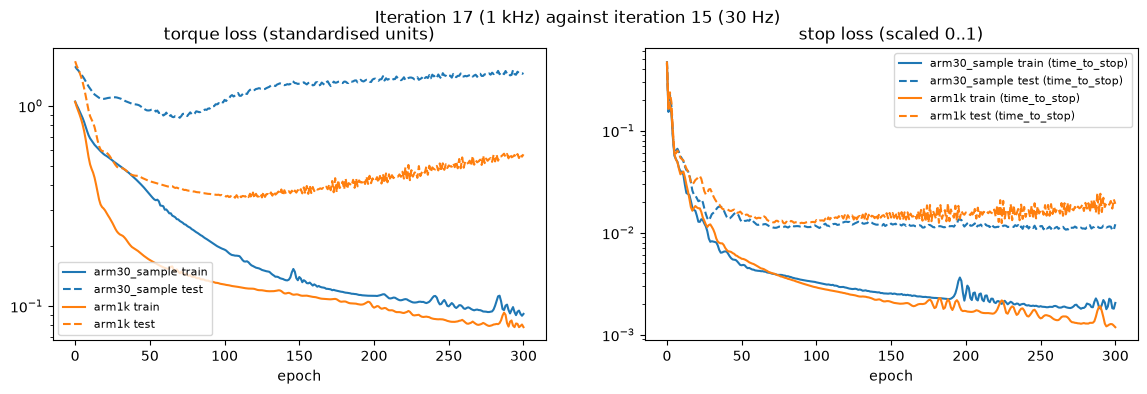

In [68]:
arm_loss_plot(['arm30_sample', 'arm1k'], 'Iteration 17 (1 kHz) against iteration 15 (30 Hz)')

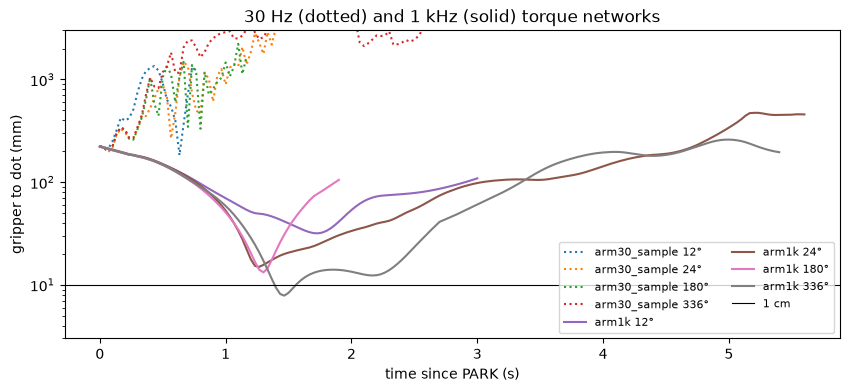

In [69]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, style in (('arm30_sample', ':'), ('arm1k', '-')):
    for r in json.loads((ARM / f'results/{name}.json').read_text()):
        if r['bearing'] in (12, 24, 180, 336):
            ax.plot([l['t'] - r['log'][0]['t'] for l in r['log']], [l['ee_mm'] for l in r['log']], style, label=f"{name} {r['bearing']}°")
ax.axhline(10, color='k', lw=0.8, label='1 cm')
ax.set(yscale='log', ylim=(3, 3000), xlabel='time since PARK (s)', ylabel='gripper to dot (mm)', title='30 Hz (dotted) and 1 kHz (solid) torque networks')
ax.legend(ncol=2, fontsize=8); plt.show()

#### Iteration 17: 3D replay (`arm1k`)

<a href="/files/arm/results/viewer_arm1k.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [70]:
path = replay_arm.build_viewer('arm1k')
lazy_player('/files/arm/results/' + path.name)

Reading the results:

- At 1 kHz the arm stays stable. The gripper gets to a median of 18 mm from the dot, against 189 mm at 30 Hz, and within 1 cm on 2 bearings (192° and 336°, both training bearings).
- It does not stay there. After its closest point the gripper drifts away, and at the expert's stop it is a median 124 mm from the dot.
- The network says stop on 22 of 25 bearings, usually early: a median 1.0 s before the expert.
- Test torque loss is 0.57 against 0.08 on training. The test loss is lowest at epoch 120 (0.35) and rises after that, so the network overfits the 21 training reaches. Stopping training earlier is worth testing.
- The likely cause of the drift: the expert's torque depends on a target angle it updates internally every 1 ms (`controller.cpp:81-85`), which the network cannot see. Small torque errors also add up with nothing to correct them.

### Arm: fewer epochs (iteration 18)

#### Iteration 18: plan and expected results

Iteration 17 overfits: its test torque loss is lowest at epoch 120 (0.35) and rises to 0.57 by epoch 300, while the training loss keeps falling. Iteration 18 is the same 1 kHz network trained for fewer epochs.

How the number of epochs is chosen, without using the test bearings:

- The 21 training bearings are already split into 5 folds (`split_plan.json`). For each fold, a network is trained on the other 4 folds for 300 epochs, and its torque loss on the held-out fold is recorded every epoch.
- The number of epochs is the one where the held-out loss, averaged over the 5 folds, is lowest.
- Iteration 18 is then trained on all 21 training bearings for that many epochs. Everything else is as in iteration 17.

Seeds: iteration 18 is trained with seeds 7, 1, 2 and 3. Iteration 17 so far has only seed 7, so it is also trained with seeds 1, 2 and 3 (300 epochs), to compare the two over the same four seeds.

Test: as iteration 17, in the simulator on the 25 bearings with the expert driving.

Expected:

- The chosen number of epochs is between 80 and 200, close to where the iteration 17 test loss is lowest.
- The test torque loss is lower than iteration 17's over the four seeds, about 0.35 against 0.57.
- In the simulator the gripper drifts less after its closest point: the median distance at the expert's stop is below iteration 17's (124 mm with seed 7), and the closest distance is no worse (18 mm).

If the test loss falls but the simulator results do not improve, overfitting is not the main reason for the drift. The more likely reason is then the expert's internal target angle, which the network cannot see.

#### Iteration 18: choosing the number of epochs

For each of the 5 folds of training bearings, a network was trained on the other 4 folds for 300 epochs, and its torque loss on the held-out fold was recorded every epoch. The averaged held-out loss is lowest at epoch 77, so iteration 18 is trained for 77 epochs.

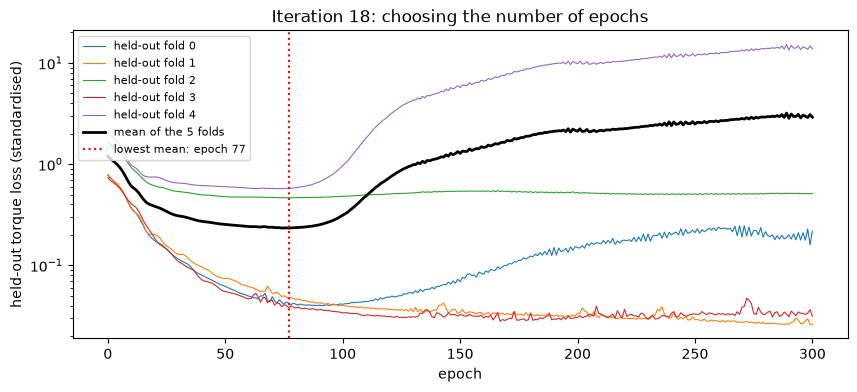

,best_epoch,best_loss,loss_at_300
fold,,,
0,91,0.040,0.217
1,299,0.026,0.026
2,77,0.464,0.513
3,167,0.028,0.031
4,74,0.571,13.757


In [71]:
cv = [pd.DataFrame(json.loads((ARM / f'models/arm1k_cv_fold{f}_history.json').read_text())) for f in range(5)]
mean_val = np.mean([h.val_torque_mse for h in cv], 0)
chosen = json.loads((ARM / 'results/cv_epochs_arm1k.json').read_text())['epochs']
fig, ax = plt.subplots(figsize=(10, 4))
for f, h in enumerate(cv):
    ax.plot(h.epoch, h.val_torque_mse, lw=0.8, label=f'held-out fold {f}')
ax.plot(cv[0].epoch, mean_val, 'k', lw=2, label='mean of the 5 folds')
ax.axvline(chosen, color='r', ls=':', label=f'lowest mean: epoch {chosen}')
ax.set(yscale='log', xlabel='epoch', ylabel='held-out torque loss (standardised)', title='Iteration 18: choosing the number of epochs')
ax.legend(fontsize=8); plt.show()
pd.DataFrame([dict(fold=f, best_epoch=int(h.epoch[h.val_torque_mse.idxmin()]),
                   best_loss=h.val_torque_mse.min(), loss_at_300=h.val_torque_mse.iloc[-1]) for f, h in enumerate(cv)]).set_index('fold').round(3)

#### Iteration 18: results over four seeds

Iteration 17 (300 epochs) against iteration 18 (77 epochs), each with seeds 7, 1, 2 and 3, tested in the simulator on the 25 bearings with the expert driving.

In [72]:
NETS = {17: ['arm1k', 'arm1k_seed1', 'arm1k_seed2', 'arm1k_seed3'], 18: ['arm1k_e77', 'arm1k_e77_seed1', 'arm1k_e77_seed2', 'arm1k_e77_seed3']}
rows = []
for it, names in NETS.items():
    for name, seed in zip(names, (7, 1, 2, 3)):
        h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
        r = pd.DataFrame(json.loads((ARM / f'results/{name}.json').read_text()))
        rows.append({'iteration': it, 'seed': seed, 'model': name, 'epochs': h['epoch'], 'test torque loss': h['test_torque_mse'],
                     'train time-to-stop loss': h['train_time_to_stop_mse'], 'median closest (mm)': r.min_mm.median(),
                     'closest within 1 cm (of 25)': int((r.min_mm <= 10).sum()), 'median at the expert stop (mm)': r.at_expert_stop_mm.median(),
                     'stopped (of 25)': int(r.stop_s.notna().sum())})
iter18 = pd.DataFrame(rows)
display(iter18.set_index(['iteration', 'seed']).round(3))
iter18.drop(columns=['seed', 'model']).groupby('iteration').mean().round(3)

model  epochs  test torque loss  \
iteration seed                                              
17        7               arm1k     300             0.572   
          1         arm1k_seed1     300             0.482   
          2         arm1k_seed2     300             0.811   
          3         arm1k_seed3     300             0.694   
18        7           arm1k_e77      77             0.377   
          1     arm1k_e77_seed1      77             0.367   
          2     arm1k_e77_seed2      77             0.377   
          3     arm1k_e77_seed3      77             0.385   

                train time-to-stop loss  median closest (mm)  \
iteration seed                                                 
17        7                       0.001               18.325   
          1                       0.002               16.456   
          2                       0.001               19.862   
          3                       0.001               37.845   
18        7                       0.004               32.971   
          1                       0.004               18.923   
          2                       0.004               26.687   
          3                       0.003               17.870   

                closest within 1 cm (of 25)  median at the expert stop (mm)  \
iteration seed                                                                
17        7                               2                         124.103   
          1                               6                         100.728   
          2                               4                          74.951   
          3                               0                         488.239   
18        7                               4                         278.746   
          1                               3                         209.033   
          2                               0                         152.882   
          3                               2                         118.563   

                stopped (of 25)  
iteration seed                   
17        7                  22  
          1                  14  
          2                  15  
          3                  22  
18        7                  15  
          1                   6  
          2                   6  
          3                   1

,epochs,test torque loss,train time-to-stop loss,median closest (mm),closest within 1 cm (of 25),median at the expert stop (mm),stopped (of 25)
iteration,,,,,,,
17,300.0,0.640,0.001,23.122,3.00,197.005,18.25
18,77.0,0.376,0.004,24.113,2.25,189.806,7.00


#### Iteration 18: loss curves

Training (solid) and test (dashed) losses for the four seeds of each iteration, in standardised units.

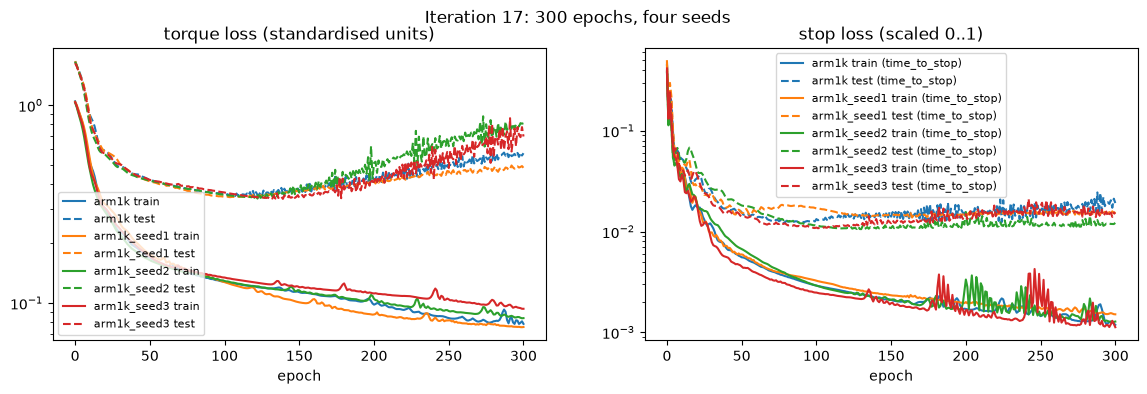

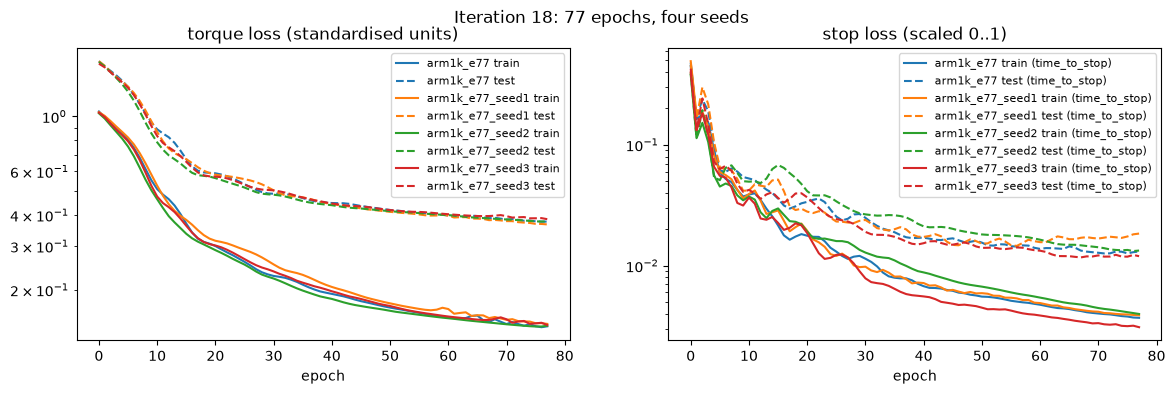

In [73]:
arm_loss_plot(NETS[17], 'Iteration 17: 300 epochs, four seeds')
arm_loss_plot(NETS[18], 'Iteration 18: 77 epochs, four seeds')

#### Iteration 18: 3D replays

One player per network: the four seeds of iteration 18, then the three new seeds of iteration 17 (seed 7 is in the iteration 17 section). The line under each player gives the distance from each gripper to the dot in mm.

##### Iteration 18, seed 7 (`arm1k_e77`)

<a href="/files/arm/results/viewer_arm1k_e77.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [74]:
path = replay_arm.build_viewer('arm1k_e77')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 1 (`arm1k_e77_seed1`)

<a href="/files/arm/results/viewer_arm1k_e77_seed1.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [75]:
path = replay_arm.build_viewer('arm1k_e77_seed1')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 2 (`arm1k_e77_seed2`)

<a href="/files/arm/results/viewer_arm1k_e77_seed2.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [76]:
path = replay_arm.build_viewer('arm1k_e77_seed2')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 18, seed 3 (`arm1k_e77_seed3`)

<a href="/files/arm/results/viewer_arm1k_e77_seed3.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [77]:
path = replay_arm.build_viewer('arm1k_e77_seed3')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 1 (`arm1k_seed1`)

<a href="/files/arm/results/viewer_arm1k_seed1.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [78]:
path = replay_arm.build_viewer('arm1k_seed1')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 2 (`arm1k_seed2`)

<a href="/files/arm/results/viewer_arm1k_seed2.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [79]:
path = replay_arm.build_viewer('arm1k_seed2')
lazy_player('/files/arm/results/' + path.name)

##### Iteration 17, seed 3 (`arm1k_seed3`)

<a href="/files/arm/results/viewer_arm1k_seed3.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [80]:
path = replay_arm.build_viewer('arm1k_seed3')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 18: reading the results

Against the expectation:

- **Number of epochs:** 77, just below the expected 80 to 200. The mean is pulled down mostly by fold 4, whose held-out loss rises from 0.57 at epoch 74 to 13.8 at epoch 300. Folds 1 and 3 keep improving until epochs 299 and 167, so the choice depends heavily on one fold.
- **Test torque loss: as expected.** It falls from a mean of 0.64 to 0.38 over the four seeds, and it is much steadier across seeds (0.37 to 0.39, against 0.48 to 0.81).
- **Simulator: not as expected.** The reach does not improve. Over the four seeds the median closest distance is 24.1 mm against 23.1 mm, the gripper gets within 1 cm on 2.25 bearings against 3, and the median distance at the expert's stop is 190 mm against 197 mm.
- **Stop: worse.** The network says stop on 7 of 25 bearings against 18.25. With fewer epochs the time-to-stop output is fitted less closely (training loss 0.004 against 0.001), so it rarely drops below the 0.25 s threshold.
- The seed still matters more than the number of epochs. With 300 epochs, the median distance at the expert's stop ranges from 75 mm (seed 2) to 488 mm (seed 3).

What it tells us: as the plan said, a lower test loss without a better reach in the simulator means overfitting is not the main reason the arm drifts. The more likely reason is the expert's internal target angle, which the network cannot see. Inputs that let the network infer it, such as its previous torques or a short history of joint angles, are the next thing to test. Fewer epochs is not kept, because it costs the stop.

### Arm: stop on distance (iteration 19)

#### Iteration 19: plan and expected results

In iterations 17 and 18 the arm follows the expert's reach closely, but the network does not know when it has reached the dot. The expert gets within 15 mm of the dot about 2 s after PARK and then holds the arm almost still until its stop rule allows it to stop: within 1 cm and more than 8 s since the start. That hold lasts a median 1.6 s. The network drifts during it, and when it does say stop the gripper is already far away: a median 257 mm for iteration 18, seed 7.

Iteration 19 is iteration 18, seed 7, with one change: the stop head learns the distance from the gripper to the dot instead of the time to stop.

- Stop target: the distance from the expert's end effector to the dot centre at each row, from the expert's recordings, clipped at 0.25 m and scaled to 0..1. The network says stop when its predicted distance is 1 cm or less, latched.
- Everything else is as in iteration 18: the same 19 inputs (arm encoder angles and speeds, the dot position from the simulator, time since PARK and since the start), 2×64 ReLU, 1 kHz, 77 epochs, seed 7, rows from the expert's PARK to its stop.
- The loss is the torque loss plus the distance loss, each training run counted equally.
- Test: the 25 bearings in the simulator with the expert driving, as before.
- New result: the distance from the gripper to the dot when the network says stop. A run ends 0.5 s after stop, so the distance 0.5 s later is also reported.

The network has every input it needs for the distance: the 7 joint angles fix where the gripper is, and the dot position is given. It has to learn that mapping from 21 reaches.

Expected:

- The network says stop on at least 20 of the 25 bearings, against 15 for iteration 18, seed 7.
- When it says stop, the gripper is a median 20 mm or less from the dot, against 257 mm.
- It stops earlier than the expert, about 1.5 s before, because it no longer waits for the expert's 8 s rule.
- The reach itself is unchanged: the median closest distance stays near 33 mm.

The expectation is wrong if the network stops on fewer than 15 bearings or the median distance at stop is above 30 mm. That would mean 21 reaches are not enough to learn the distance from the joint angles.

#### Iteration 19: results

Iteration 18, seed 7 (stop on time) against iteration 19 (stop on distance), on the 25 bearings with the expert driving. A run ends 0.5 s after the network says stop.

In [81]:
rows = []
for it, name, stop in ((18, 'arm1k_e77', 'time'), (19, 'arm1k_e77_dist', 'distance')):
    h = json.loads((ARM / f'models/{name}_history.json').read_text())[-1]
    r = pd.DataFrame(json.loads((ARM / f'results/{name}.json').read_text()))
    if 'at_network_stop_mm' not in r:          # older result files: read it from the log
        r['at_network_stop_mm'] = [next((l['ee_mm'] for l in x['log'] if l['t'] >= x['stop_s']), np.nan) if x['stop_s'] else np.nan
                                   for x in json.loads((ARM / f'results/{name}.json').read_text())]
    rows.append({'iteration': it, 'model': name, 'stop learns': stop, 'test torque loss': h['test_torque_mse'],
                 'stopped (of 25)': int(r.stop_s.notna().sum()), 'median distance at stop (mm)': r.at_network_stop_mm.median(),
                 'median distance at the end of the run (mm)': r.end_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'median stop vs expert (s)': (r.stop_s - r.expert_stop_s).median()})
pd.DataFrame(rows).set_index('iteration').round(3)

,model,stop learns,test torque loss,stopped (of 25),median distance at stop (mm),median distance at the end of the run (mm),median closest (mm),median stop vs expert (s)
iteration,,,,,,,,
18,arm1k_e77,time,0.377,15,257.271,445.634,32.971,-0.191
19,arm1k_e77_dist,distance,0.368,25,35.219,62.868,29.332,-1.881


#### Iteration 19: predicted against actual distance

The stop head's predicted distance against the real distance from the gripper to the dot, on four bearings. The network says stop when its prediction first reaches 1 cm (dotted line).

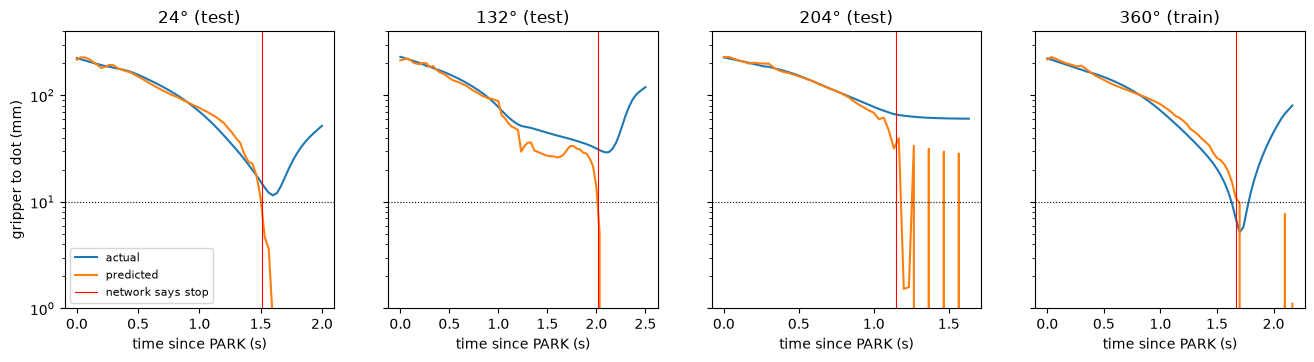

Within 100 mm of the dot: predicted minus actual distance, median -14.2 mm, mean absolute 28.8 mm
Network stops within 10 mm of the closest point it reaches: 18 of 25


In [82]:
r19 = {r['bearing']: r for r in json.loads((ARM / 'results/arm1k_e77_dist.json').read_text())}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, b in zip(axes, (24, 132, 204, 360)):
    L = r19[b]['log']; t0 = L[0]['t']
    ax.plot([l['t'] - t0 for l in L], [l['ee_mm'] for l in L], label='actual')
    ax.plot([l['t'] - t0 for l in L], [1000 * l['ttp_s'] for l in L], label='predicted')
    ax.axhline(10, color='k', ls=':', lw=0.8)
    if r19[b]['stop_s']:
        ax.axvline(r19[b]['stop_s'] - t0, color='r', lw=0.8, label='network says stop')
    ax.set(title=f"{b}° ({r19[b]['split']})", xlabel='time since PARK (s)', yscale='log', ylim=(1, 400))
axes[0].set_ylabel('gripper to dot (mm)'); axes[0].legend(fontsize=8); plt.show()
near = np.array([1000 * l['ttp_s'] - l['ee_mm'] for r in r19.values() for l in r['log'] if l['ee_mm'] < 100])
print(f'Within 100 mm of the dot: predicted minus actual distance, median {np.median(near):.1f} mm, mean absolute {np.abs(near).mean():.1f} mm')
print('Network stops within 10 mm of the closest point it reaches:', sum(r['at_network_stop_mm'] - r['min_mm'] <= 10 for r in r19.values()), 'of 25')

#### Iteration 19: loss curves

Training (solid) and test (dashed) losses. The right panel is the stop loss: time to stop for iteration 18 and distance for iteration 19, each scaled to 0..1, so the two are not on the same scale.

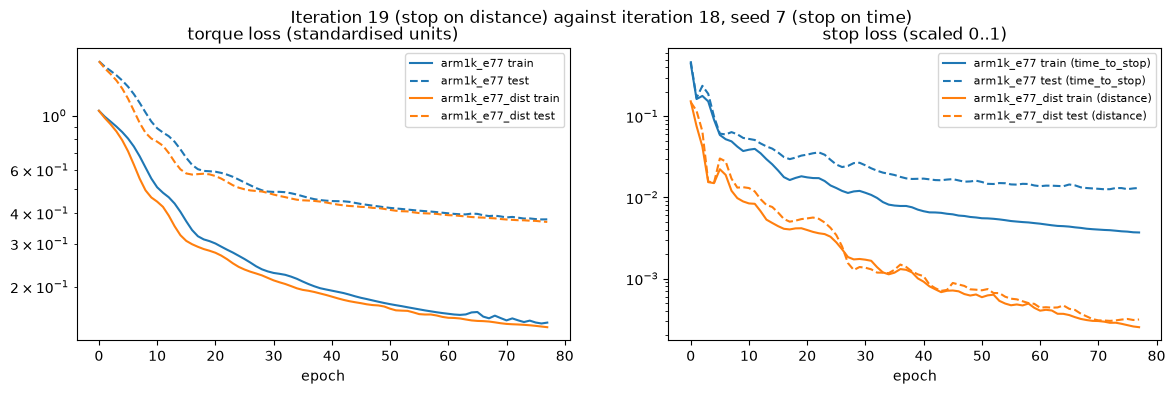

In [83]:
arm_loss_plot(['arm1k_e77', 'arm1k_e77_dist'], 'Iteration 19 (stop on distance) against iteration 18, seed 7 (stop on time)')

#### Iteration 19: 3D replay (`arm1k_e77_dist`)

<a href="/files/arm/results/viewer_arm1k_e77_dist.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [84]:
path = replay_arm.build_viewer('arm1k_e77_dist')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 19: reading the results

Against the expectation:

- **Stops: as expected.** The network says stop on all 25 bearings, against 15 for iteration 18, seed 7.
- **Distance at stop: better, but not as expected.** The gripper is a median 35 mm from the dot when the network says stop, against 257 mm for iteration 18. The expectation was 20 mm or less, and above 30 mm counts as wrong.
- **When it stops: as expected.** A median 1.9 s before the expert, because it no longer waits for the expert's 8 s rule.
- **Reach: as expected.** The median closest distance is 29 mm, against 33 mm.

Why the distance at stop is 35 mm and not 1 cm:

- On 18 of 25 bearings the network says stop within 10 mm of the closest point the gripper reaches. The stop now comes at the right moment; the gripper simply never gets within 1 cm.
- Near the dot the stop head underestimates the distance: when the gripper is within 100 mm, the prediction is a median 14 mm too low. It seems to have learned "this stage of the reach means close" from the 21 expert reaches, where the gripper always ends within about 1 cm, rather than the real distance.
- After stop the distance grows from a median 35 mm to 63 mm over the last 0.5 s, because nothing holds the arm.
- The distance loss is still falling at epoch 77 (training 0.0003, test 0.0003), so the stop head has not finished learning. On 204°, a test bearing where the expert itself stalls 11.5 mm away, the gripper stays about 60 mm away and the prediction falls below 1 cm anyway.

What it tells us: the stop works on distance far better than on time, so it is kept. The limit is now the reach itself. The gripper gets a median 29 mm from the dot, never within 1 cm, and drifts once it stops moving towards it. Getting closer and holding still are the next problems.

### Arm: dot from the camera (iteration 20)

#### Iteration 20: plan and expected results

In iterations 14 to 19 the arm network got the dot position from the simulator. The robot can only know it from its own sensors, so iteration 20 gives the arm network the dot from the corner camera and the tracker, as the driving network gets it.

- The network is iteration 19's, unchanged: no retraining, so only the source of the dot changes.
- The camera and tracker are the ones the driving network uses, with one change: the tracker now also keeps the dot's height from the camera. While the dot is hidden, the height stays as last seen, because the robot drives on flat ground.
- The camera image is taken every 1/30 s, as in driving. The arm network runs every 1 ms and uses the latest tracker estimate. The tracker moves the dot with the wheel encoder speeds while the robot drives, and after PARK the robot does not move.
- The expert still drives and parks, so the dot source is the only change from iteration 19.
- Test: the 25 bearings in the simulator. New result: the error of the tracker's estimate against the true dot, at PARK and during the reach.

Expected:

- At PARK the dot is in the camera's view on about 9 of 25 bearings. On the others the tracker's estimate is 1 to 4 cm off, from the wheel odometry while the dot was hidden.
- The arm aims at the estimated dot, so the gripper ends up about as far from the true dot as the estimate is off. The median closest distance rises from 29 mm to about 40 to 50 mm.
- The network still stops on all 25 bearings, when it thinks it is within 1 cm of the estimated dot. The real distance at stop rises from a median 35 mm to about 50 mm.

The expectation is wrong if the results match iteration 19 within a few millimetres, which would mean the camera error does not matter, or if the median distance at stop is above 80 mm, which would mean the camera is not good enough for the arm as it is.

All 30 expert targets are at the same height, 0.5 m. The network has only ever seen that height, so this test does not show whether it can reach a dot at another height. That needs new expert runs at other heights and is a later iteration.

#### Iteration 20: results

The same network as iteration 19, with the dot from the simulator (iteration 19) and from the camera and tracker (iteration 20), on the 25 bearings with the expert driving.

In [85]:
rows = []
for it, results, source in ((19, 'arm1k_e77_dist', 'simulator'), (20, 'arm1k_e77_dist_camera', 'camera and tracker')):
    r = pd.DataFrame(json.loads((ARM / f'results/{results}.json').read_text()))
    rows.append({'iteration': it, 'dot from': source, 'stopped (of 25)': int(r.stop_s.notna().sum()),
                 'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'median distance at the end of the run (mm)': r.end_mm.median(), 'median stop vs expert (s)': (r.stop_s - r.expert_stop_s).median()})
display(pd.DataFrame(rows).set_index('iteration').round(1))
cam = pd.DataFrame(json.loads((ARM / 'results/arm1k_e77_dist_camera.json').read_text()))
print('Dot in view at PARK:', int(cam.visible_at_park.sum()), 'of 25. Estimate error at PARK: median', round(cam.est_err_at_park_mm.median(), 1),
      'mm; height error: median', round(cam.height_err_at_park_mm.abs().median(), 1), 'mm.')

,dot from,stopped (of 25),median distance at stop (mm),median closest (mm),median distance at the end of the run (mm),median stop vs expert (s)
iteration,,,,,,
19,simulator,25,35.2,29.3,62.9,-1.9
20,camera and tracker,25,214.1,105.3,501.7,-2.7


Dot in view at PARK: 16 of 25. Estimate error at PARK: median 26.8 mm; height error: median 10.9 mm.


#### Iteration 20: the camera's estimate during the reach

Left: how far the tracker's estimate is from the true dot. Right: how far the estimate moves from its value at PARK. The robot is parked, so in training the dot input never changed after PARK.

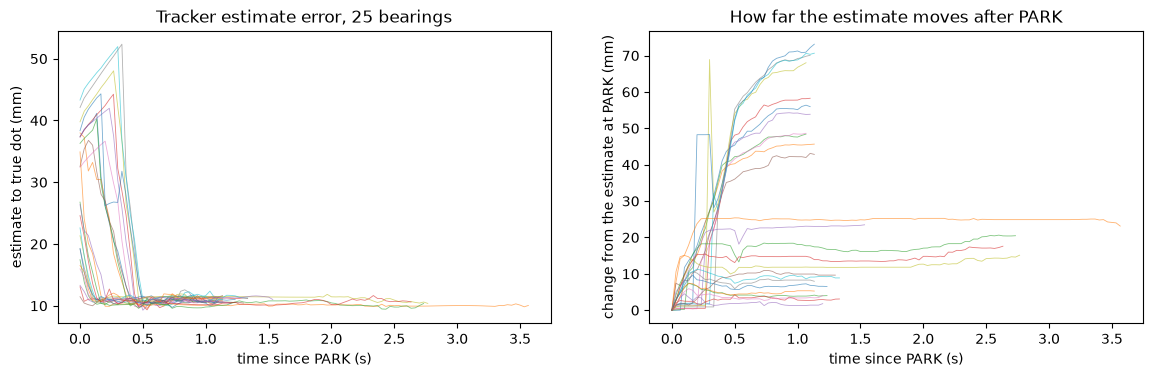

Estimate during the reach: error median 11 mm, dot in view 94% of frames; largest change from PARK: median 19 mm, max 72 mm
Time from PARK to the closest point: median 0.50 s with the camera, 1.63 s with the simulator's dot


In [86]:
camruns = json.loads((ARM / 'results/arm1k_e77_dist_camera.json').read_text())
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for r in camruns:
    L = r['log']; t0 = L[0]['t']; E = np.array([l['est'] for l in L])
    ax[0].plot([l['t'] - t0 for l in L], [l['est_err_mm'] for l in L], lw=0.6, alpha=0.6)
    ax[1].plot([l['t'] - t0 for l in L], 1000 * np.linalg.norm(E - E[0], axis=1), lw=0.6, alpha=0.6)
ax[0].set(xlabel='time since PARK (s)', ylabel='estimate to true dot (mm)', title='Tracker estimate error, 25 bearings')
ax[1].set(xlabel='time since PARK (s)', ylabel='change from the estimate at PARK (mm)', title='How far the estimate moves after PARK')
plt.show()
moves = [1000 * np.abs(np.array([l['est'] for l in r['log']]) - r['log'][0]['est']).max() for r in camruns]
print(f"Estimate during the reach: error median {np.median([l['est_err_mm'] for r in camruns for l in r['log']]):.0f} mm, dot in view "
      f"{np.mean([l['visible'] for r in camruns for l in r['log']]):.0%} of frames; largest change from PARK: median {np.median(moves):.0f} mm, max {max(moves):.0f} mm")
tc = lambda runs: np.median([min(r['log'], key=lambda l: l['ee_mm'])['t'] - r['log'][0]['t'] for r in runs])
print(f"Time from PARK to the closest point: median {tc(camruns):.2f} s with the camera, "
      f"{tc(json.loads((ARM / 'results/arm1k_e77_dist.json').read_text())):.2f} s with the simulator's dot")

#### Iteration 20: loss curves

Iteration 20 uses iteration 19's network without retraining, so these are iteration 19's training curves.

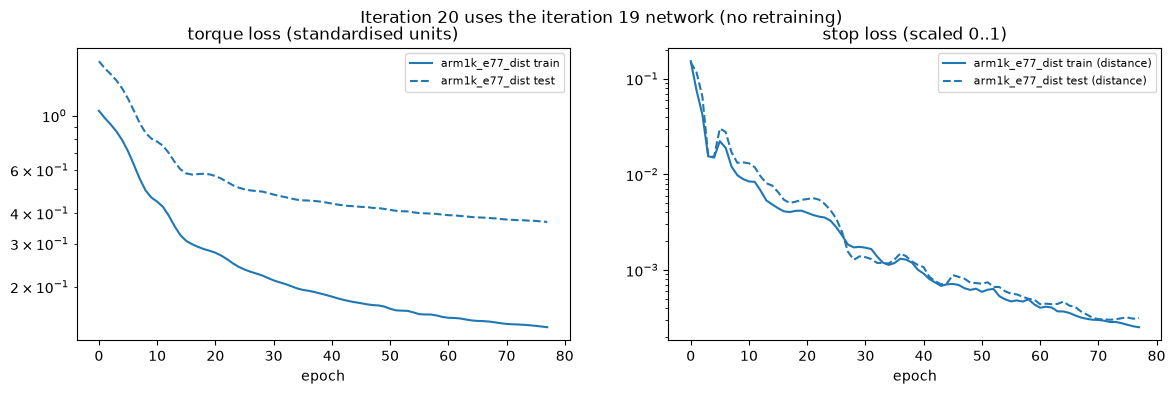

In [87]:
arm_loss_plot(['arm1k_e77_dist'], 'Iteration 20 uses the iteration 19 network (no retraining)')

#### Iteration 20: 3D replay (`arm1k_e77_dist`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_dist_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [88]:
path = replay_arm.build_viewer('arm1k_e77_dist_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 20: reading the results

Against the expectation:

- **The camera's error: smaller than expected.** The dot is in view at PARK on 16 of 25 bearings, against the expected 9. The estimate is a median 27 mm from the true dot at PARK (11 mm in height), and 11 mm during the reach, when the dot is in view 94% of the time.
- **The reach: much worse than expected.** The gripper gets a median 105 mm from the dot, against 29 mm with the simulator's dot and the expected 40 to 50 mm.
- **The stop: it still stops on all 25, but far from the dot.** A median 214 mm away when it stops, against 35 mm. Above 80 mm means the expectation was wrong: the camera, as it is used now, is not good enough for the arm.

Why it is worse than the estimate error suggests:

- The dot input jumps in the first 0.5 s after PARK. Where the dot was hidden while parking, the estimate starts 30 to 50 mm off and is corrected in one step when the dot comes into view. The network runs every 1 ms and sees the new value as a sudden change.
- In training the robot is parked, so the dot input never changes after PARK. A dot input that jumps is something the network has never seen.
- The arm leaves the expert's path early: the gripper is closest a median 0.5 s after PARK, against 1.6 s with the simulator's dot, and then swings away.
- Once the arm swings, it pushes the robot base: the true dot moves by up to 40 mm relative to the robot. The estimate follows it, staying about 11 mm off, which is why the estimate moves by up to 72 mm in total. This is a result of the swing, not its cause.

What it tells us: the next test is to give the arm network one fixed dot position, taken once the camera has a fresh view of the dot after PARK, and to keep it fixed during the reach. If that works, the camera's error alone, about 1 cm when the dot is in view, sets how close the gripper can get. Training on dot positions with the camera's error added is the other option.

### Arm: no time inputs (iteration 21)

#### Iteration 21: plan and expected results

With the camera (iteration 20), the arm reaches the dot about 0.6 s after PARK instead of 1.6 s, says stop, and then drops: the gripper falls a median 447 mm in the next 0.5 s. With the simulator's dot (iteration 19) it falls a median 5 mm after its closest point, up to about 50 mm on some bearings.

The likely reason is the two time inputs, time since PARK and time since the start. In every training row the arm is at the point of the expert's reach that the clock predicts: about halfway 0.6 s after PARK, at the dot about 1.6 s after. The network can use the clock as a shortcut instead of the joint angles. When the arm arrives early, the clock and the joints disagree, which never happens in training, and the torques it gives there do not hold the arm against gravity.

The time inputs were needed for the old stop, which followed the expert's 8 s rule. Since iteration 19 the stop learns the distance to the dot, so the clock is no longer needed.

Iteration 21 is iteration 19 retrained without the two time inputs:

- 17 inputs: arm encoder angles and speeds (7 each) and the dot position (x, y, height).
- Everything else as in iteration 19: the torques and the distance to the dot as outputs, stop at 1 cm, 2×64 ReLU, 1 kHz, 77 epochs, seed 7, rows from the expert's PARK to its stop.
- Tested twice on the 25 bearings with the expert driving: with the simulator's dot, to compare with iteration 19, and with the camera and tracker, to compare with iteration 20.
- New result: how far the gripper height falls after the gripper's closest point to the dot.

Expected:

- With the simulator's dot: the reach stays as in iteration 19 (median closest near 30 mm) and the fall after the closest point stays small, near 5 mm, and no longer reaches 50 mm.
- With the camera: the fall of a median 447 mm mostly goes away, to below 50 mm. The early, fast reach stays, because it comes from the dot input jumping when a hidden dot comes into view, not from the clock.

The expectation is wrong if the arm still falls by more than 200 mm with the camera. Then the clock is not the cause, and the next suspect is gravity itself: the torque that holds the arm up depends on the joint angles in a way the network has not learned from 21 reaches.

#### Iteration 21: results

Iterations 19 and 21 with the simulator's dot, and iterations 20 and 21 with the camera, on the 25 bearings with the expert driving. The fall is how far the gripper height drops after the gripper's closest point to the dot.

In [89]:
def gripper_fall_mm(run):
    """How far the gripper height drops after its closest point to the dot (from the frames logged every 1/30 s)."""
    F = [f for f in run['frames'] if f['parked']]
    i = int(np.argmin([f['ee_mm'] for f in F]))
    return 1000 * (F[i]['ee'][2] - min(f['ee'][2] for f in F[i:]))

rows = []
for it, results, inputs, source in ((19, 'arm1k_e77_dist', 19, 'simulator'), (21, 'arm1k_e77_dist_notime', 17, 'simulator'),
                                    (20, 'arm1k_e77_dist_camera', 19, 'camera'), (21, 'arm1k_e77_dist_notime_camera', 17, 'camera')):
    runs = json.loads((ARM / f'results/{results}.json').read_text()); r = pd.DataFrame(runs)
    rows.append({'iteration': it, 'inputs': inputs, 'dot from': source, 'stopped (of 25)': int(r.stop_s.notna().sum()),
                 'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'median fall after closest (mm)': np.median([gripper_fall_mm(x) for x in runs]),
                 'largest fall (mm)': max(gripper_fall_mm(x) for x in runs)})
pd.DataFrame(rows).set_index(['iteration', 'dot from']).round(1)

,,inputs,stopped (of 25),median distance at stop (mm),median closest (mm),median fall after closest (mm),largest fall (mm)
iteration,dot from,,,,,,
19,simulator,19,25,35.2,29.3,5.3,81.7
21,simulator,17,24,79.0,23.7,111.4,345.5
20,camera,19,25,214.1,105.3,446.9,578.9
21,camera,17,3,493.4,188.7,385.8,682.5


#### Iteration 21: gripper height after PARK

The gripper height on four bearings, with and without the time inputs. The dot is at 0.5 m.

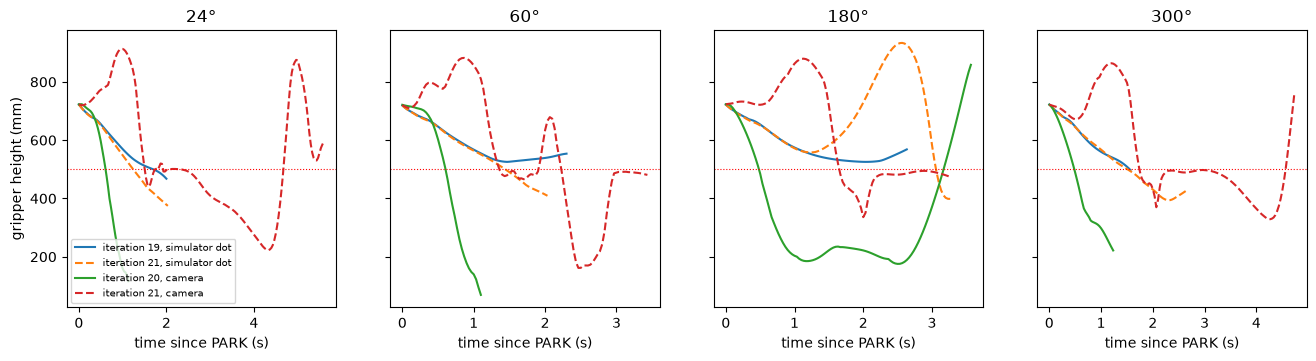

In [90]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
styles = (('arm1k_e77_dist', 'iteration 19, simulator dot', '-'), ('arm1k_e77_dist_notime', 'iteration 21, simulator dot', '--'),
          ('arm1k_e77_dist_camera', 'iteration 20, camera', '-'), ('arm1k_e77_dist_notime_camera', 'iteration 21, camera', '--'))
runs = {name: {r['bearing']: r for r in json.loads((ARM / f'results/{name}.json').read_text())} for name, _, _ in styles}
for ax, b in zip(axes, (24, 60, 180, 300)):
    for name, label, ls in styles:
        F = [f for f in runs[name][b]['frames'] if f['parked']]
        ax.plot([f['time_s'] - F[0]['time_s'] for f in F], [1000 * f['ee'][2] for f in F], ls, label=label)
    ax.axhline(500, color='r', lw=0.8, ls=':'); ax.set(title=f'{b}°', xlabel='time since PARK (s)')
axes[0].set_ylabel('gripper height (mm)'); axes[0].legend(fontsize=7); plt.show()

#### Iteration 21: loss curves

Iteration 21 (17 inputs, no time) against iteration 19 (19 inputs).

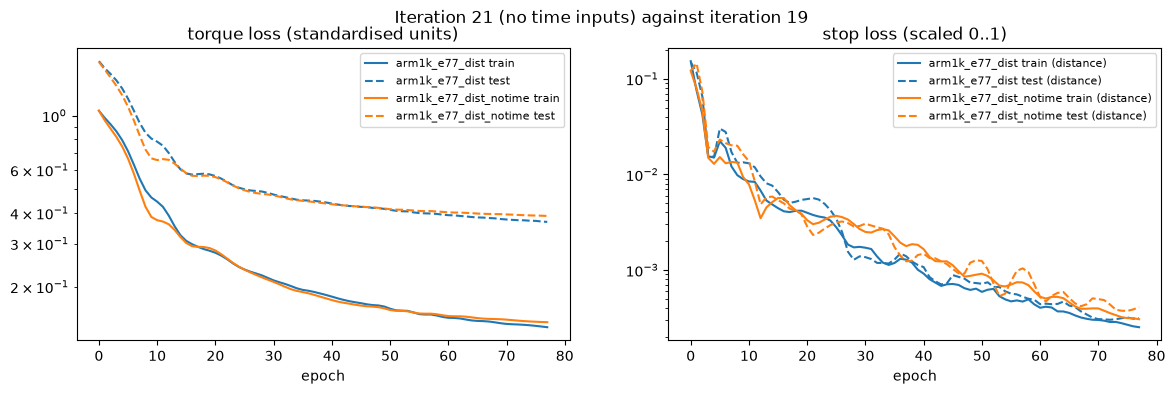

In [91]:
arm_loss_plot(['arm1k_e77_dist', 'arm1k_e77_dist_notime'], 'Iteration 21 (no time inputs) against iteration 19')

#### Iteration 21: 3D replay with the simulator's dot (`arm1k_e77_dist_notime`)

<a href="/files/arm/results/viewer_arm1k_e77_dist_notime.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [92]:
path = replay_arm.build_viewer('arm1k_e77_dist_notime')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 21: 3D replay with the camera (`arm1k_e77_dist_notime`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_dist_notime_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [93]:
path = replay_arm.build_viewer('arm1k_e77_dist_notime_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 21: the dot input at PARK, training against the camera

The spread of the dot position relative to the robot at PARK over the 21 training runs, against the camera's error at PARK.

In [94]:
import train_arm
train_dot = np.array([train_arm.load_run(b, 'sample', 1000)['X'][0, 14:17] for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == 'train'])
cam = json.loads((ARM / 'results/arm1k_e77_dist_camera.json').read_text())
err = np.array([np.subtract(r['log'][0]['est'], r['log'][0]['true']) for r in cam])
spread = 1000 * train_dot.std(0)
pd.DataFrame({'training range (mm)': [f'{1000 * lo:.0f} to {1000 * hi:.0f}' for lo, hi in zip(train_dot.min(0), train_dot.max(0))],
              'training spread, std (mm)': spread.round(1),
              'camera error at PARK, median size (mm)': (1000 * np.median(np.abs(err), 0)).round(1),
              'camera error in training stds': (1000 * np.median(np.abs(err), 0) / spread).round(1)},
             index=['x (forward)', 'y (left)', 'height'])

,training range (mm),"training spread, std (mm)","camera error at PARK, median size (mm)",camera error in training stds
x (forward),676 to 730,13.500000,17.2,1.3
y (left),-31 to 26,16.200001,18.4,1.1
height,502 to 503,0.200000,10.9,61.6


#### Iteration 21: reading the results

Against the expectation:

- **With the simulator's dot: not as expected.** The gripper gets a little closer (median 24 mm against 29 mm), but then it falls a median 111 mm after its closest point, against 5 mm with the time inputs. When it says stop it is a median 79 mm from the dot, against 35 mm.
- **With the camera: not as expected.** The fall stays large, a median 386 mm against 447 mm, so it is above the 200 mm that the plan set as the test. The reach is worse (median closest 189 mm against 105 mm), and the network says stop on only 3 of 25 bearings.

What it tells us:

- The clock was not the cause of the fall. It was the opposite: with the simulator's dot, the time inputs were what kept the arm up after the reach. In the expert's runs the arm holds still near the dot for the last part of every run, and the network had learned "late in the run, hold" from the clock.
- Without the clock, the network has to work out the holding torque from the joint angles alone, and it cannot from 21 reaches. Holding the arm still means cancelling gravity, and the torque for that changes with every joint angle.
- Iteration 19, with the time inputs, stays the best arm network with the simulator's dot.

Why the camera makes the arm fall (iterations 20 and 21). The height plot shows that with the camera the gripper does not reach and then drop. It falls from the start, straight through the dot's height. The cause is the dot height input:

- Over the 21 training runs the dot height relative to the robot is 502 to 503 mm, a spread of 0.2 mm, because every dot is 0.5 m high and the robot always parks on flat ground. The x and y positions spread by 13 to 16 mm.
- The inputs are standardised, so the network sees a 1 mm change in height as 5 standard deviations.
- At PARK the camera's estimate is a median 11 mm off in height, about 60 standard deviations, while its x and y errors (17 and 18 mm) are about 1 standard deviation. The height input is far outside anything the network has seen, and its torques there make the arm fall.

What to test next: train on dot heights with the camera's error added (or with different dot heights), or leave the height out until the expert data has dots at other heights. Leaving it out is the quickest test that the height input is the cause.

### Arm: no scaling (iteration 22)

#### Iteration 22: plan and expected results

Every arm network so far (iterations 14 to 21) standardised all its inputs and all 7 torques with the training-set mean and standard deviation. For inputs that barely move in training this makes small changes look huge. The dot height spreads by 0.2 mm over the 21 training runs, so a 1 mm change is 5 standard deviations and the camera's 11 mm height error at PARK is about 60. Joint 7's angle spreads by 0.001 rad, so a 0.01 rad drift is 10.

Iteration 22 is iteration 21 retrained with no scaling at all:

- Inputs as in iteration 21 (17), in their own units: arm encoder angles (rad) and speeds (rad/s), 7 each, and the dot position x, y, height (m). No time inputs.
- Outputs: the 7 torques in N m, and the distance from the gripper to the dot (clipped at 0.25 m and divided by 0.25 m, as since iteration 19; this is how the stop target is defined, not feature scaling). Stop at 1 cm.
- Loss: torque MSE in N m² plus the distance MSE, weight 1 each, each training run counted equally.
- Everything else as in iteration 21: 2×64 ReLU, 1 kHz, Adam lr 0.01, 77 full-batch epochs, seed 7, rows from the expert's PARK to its stop, 21 training bearings.
- Tested on the 25 bearings with the expert driving, with the dot from the camera and tracker. From this iteration on the arm is tested with the camera only.

Expected:

- With the camera: the 11 mm height error is now an 0.011 change in an input of about 0.5, so the arm no longer falls straight through the dot. The median fall after the closest point drops from 386 mm to below 200 mm.
- The reach itself stays about as in iteration 21 with the camera (median closest near 189 mm), since without the time inputs the network still has to work out the holding torque from the joint angles.
- Two risks. The torque loss in N m² is tens of times the distance loss, so the stop head may learn less and stop on fewer bearings. And in 77 full-batch steps the outputs have to grow from 0 to the 16 N m that joint 2 needs, so the torques may underfit.

The expectation is wrong if the arm still falls by more than 200 mm with the camera. Then the height scaling was not the cause.

#### Iteration 22: results

Iterations 21 and 22 with the dot from the camera, on the 25 bearings with the expert driving. Both have the same 17 inputs; iteration 22 has no scaling. The fall is how far the gripper height drops after the gripper's closest point to the dot.

In [95]:
rows = []
for it, results, source in ((21, 'arm1k_e77_dist_notime_camera', 'camera'), (22, 'arm1k_e77_dist_notime_raw_camera', 'camera')):
    runs = json.loads((ARM / f'results/{results}.json').read_text()); r = pd.DataFrame(runs)
    rows.append({'iteration': it, 'dot from': source, 'scaling': 'none' if it == 22 else 'mean/std',
                 'stopped (of 25)': int(r.stop_s.notna().sum()),
                 'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'median at expert stop (mm)': r.at_expert_stop_mm.median(),
                 'median fall after closest (mm)': np.median([gripper_fall_mm(x) for x in runs]),
                 'largest fall (mm)': max(gripper_fall_mm(x) for x in runs)})
pd.DataFrame(rows).set_index(['iteration', 'dot from']).round(1)

,,scaling,stopped (of 25),median distance at stop (mm),median closest (mm),median at expert stop (mm),median fall after closest (mm),largest fall (mm)
iteration,dot from,,,,,,,
21,camera,mean/std,3,493.4,188.7,574.9,385.8,682.5
22,camera,none,25,238.8,186.1,293.5,194.6,421.8


#### Iteration 22: gripper height after PARK

The gripper height on four bearings with the dot from the camera, iteration 21 (mean/std scaling) against iteration 22 (no scaling). The dot is at 0.5 m.

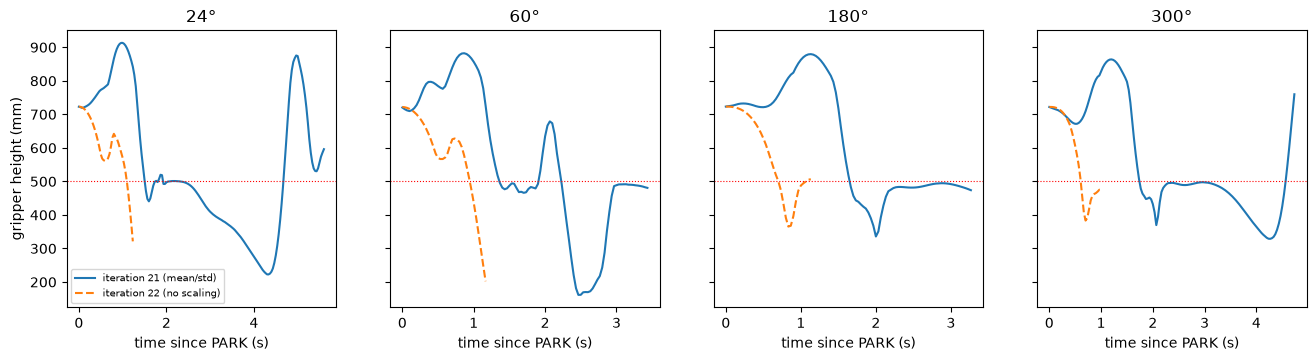

In [96]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
styles = (('arm1k_e77_dist_notime_camera', 'iteration 21 (mean/std)', '-'), ('arm1k_e77_dist_notime_raw_camera', 'iteration 22 (no scaling)', '--'))
runs = {name: {r['bearing']: r for r in json.loads((ARM / f'results/{name}.json').read_text())} for name, _, _ in styles}
for ax, b in zip(axes, (24, 60, 180, 300)):
    for name, label, ls in styles:
        F = [f for f in runs[name][b]['frames'] if f['parked']]
        ax.plot([f['time_s'] - F[0]['time_s'] for f in F], [1000 * f['ee'][2] for f in F], ls, label=label)
    ax.axhline(500, color='r', lw=0.8, ls=':'); ax.set(title=f'{b}°', xlabel='time since PARK (s)')
axes[0].set_ylabel('gripper height (mm)'); axes[0].legend(fontsize=7); plt.show()

#### Iteration 22: loss curves

Iteration 22 is trained on torques in N m, so its torque loss is in N m², while earlier arm networks' losses are in standardised units and cannot share an axis with it. The table after the plot puts iteration 21 in the same units: its saved network (which takes raw inputs and gives N m) run over the same rows. Predicting each joint's mean torque gives the baseline.

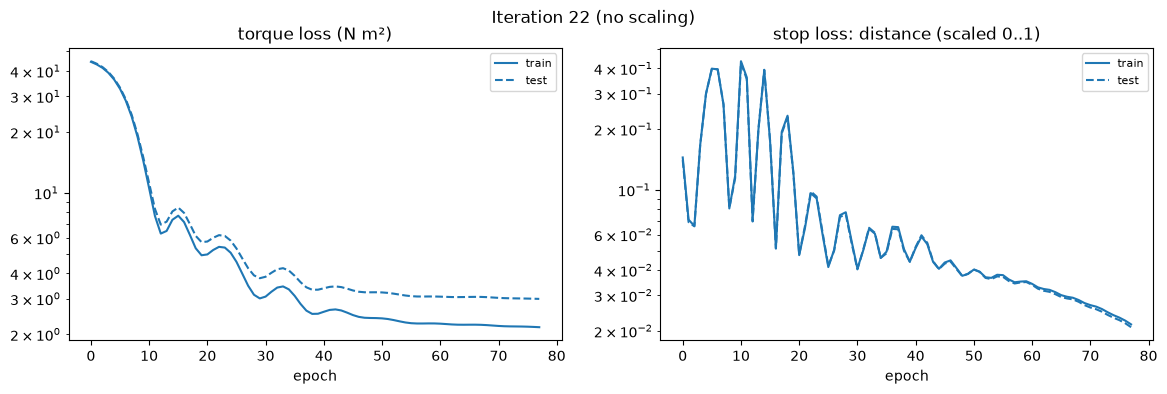

,train torque MSE (N m²),test torque MSE (N m²)
baseline: mean torque,3.68,4.41
iteration 21 (mean/std),0.37,0.92
iteration 22 (no scaling),2.17,2.99


In [97]:
import train_arm
h = pd.DataFrame(json.loads((ARM / 'models/arm1k_e77_dist_notime_raw_history.json').read_text()))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(h.epoch, h.train_torque_mse, label='train'); ax[0].plot(h.epoch, h.test_torque_mse, '--', color='C0', label='test')
ax[1].plot(h.epoch, h.train_distance_mse, label='train'); ax[1].plot(h.epoch, h.test_distance_mse, '--', color='C0', label='test')
for a, t in zip(ax, ('torque loss (N m²)', 'stop loss: distance (scaled 0..1)')):
    a.set(yscale='log', xlabel='epoch', title=t); a.legend(fontsize=8)
fig.suptitle('Iteration 22 (no scaling)'); plt.show()

def torque_mse_Nm2(model, split):
    w = dict(np.load(ARM / f'models/{model}.npz')); out = []
    runs = [train_arm.load_run(b, 'sample', 1000, 'distance') for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == split]
    for r in runs:
        X = r['X'][:, :17]
        for l in ('shared.0', 'shared.2'):
            X = np.maximum(X @ w[l + '.weight'].T + w[l + '.bias'], 0)
        out.append(((X @ w['arm.weight'].T + w['arm.bias'] - r['tau']) ** 2).mean())
    return np.mean(out)                                       # each run counted equally, as in training

def baseline_Nm2(split):
    tr = [train_arm.load_run(b, 'sample', 1000, 'distance') for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == 'train']
    mean = np.concatenate([r['tau'] for r in tr]).mean(0)
    runs = [train_arm.load_run(b, 'sample', 1000, 'distance') for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == split]
    return np.mean([((r['tau'] - mean) ** 2).mean() for r in runs])

pd.DataFrame({'train torque MSE (N m²)': [baseline_Nm2('train'), torque_mse_Nm2('arm1k_e77_dist_notime', 'train'), torque_mse_Nm2('arm1k_e77_dist_notime_raw', 'train')],
              'test torque MSE (N m²)': [baseline_Nm2('test'), torque_mse_Nm2('arm1k_e77_dist_notime', 'test'), torque_mse_Nm2('arm1k_e77_dist_notime_raw', 'test')]},
             index=['baseline: mean torque', 'iteration 21 (mean/std)', 'iteration 22 (no scaling)']).round(2)

#### Iteration 22: 3D replay (`arm1k_e77_dist_notime_raw`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_dist_notime_raw_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [98]:
path = replay_arm.build_viewer('arm1k_e77_dist_notime_raw_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 22: reading the results

Against the expectation:

- **The fall is under 200 mm, but not for the reason expected.** The median fall after the closest point is 195 mm, against 386 mm in iteration 21. The height plot shows why: the network says stop a median 0.64 s after PARK (iteration 21: 2.96 s), and the run ends 0.5 s later. The gripper has less time to fall, but it is already falling when the run ends. It does not hold the arm up.
- **The network now says stop on all 25 bearings, against 3,** but too early: a median 239 mm from the dot. The stop head learned less, as the plan warned. Its loss is in units of 0.25 m and is tens of times smaller than the torque loss in N m².
- **The reach is no better.** The median closest is 186 mm, against 189 mm. The gripper never rises at PARK as the expert's does. It drops straight away.
- **Fewer torques are at the 30 N m limit:** 6.5% of logged torques, against 31% in iteration 21.

What it tells us:

- Without scaling the network fits the expert's torques poorly. After 77 epochs its torque error is 2.17 N m² on the training runs and 2.99 on the test runs. Predicting each joint's mean torque gives 3.68 and 4.41, and iteration 21 got 0.37 and 0.92. In raw units the inputs and torques are on very different scales: joint 2 needs about 16 N m to hold the arm while joint 7 needs 0.01 N m, and the dot height is 0.5 m in every row. With the same learning rate and number of epochs, the network learns mostly the large torques and the average.
- The camera's height error is no longer the main problem, but this network has not learned to hold the arm against gravity either, so this test cannot show whether removing the scaling fixes the camera fall.

### Arm: inputs scaled by physical sizes (iteration 23)

#### Iteration 23: plan and expected results

Iteration 22 removed all scaling. The camera's height error stopped mattering, but the network learned almost nothing beyond each joint's average torque. On the test runs its torque error per joint equals the expert's own spread, while iteration 21 (scaled) gets the error on joints 2, 4, 6 and 7 down by 4 to 17 times. The torque scaling is what made the fit precise. The input scaling is what made the camera fail: dividing by the training spread magnified the dot height by 5,000 and joint 7's angle by 1,000.

Iteration 23 is iteration 21 with only the input scaling changed. Each input is divided by a fixed physical size, with no mean subtracted:

| Input | Iterations 14 to 21 | Iteration 23 |
|---|---|---|
| Joint angles | (angle − mean) ÷ std, e.g. joint 7 ÷ 0.001 rad | ÷ π |
| Joint speeds | (speed − mean) ÷ std, e.g. joint 1 ÷ 0.039 rad/s | ÷ 0.63 rad/s (joints 1 to 4), ÷ 0.84 rad/s (joints 5 to 7), the speed limits in the robot model |
| Dot x, y, height | (value − mean) ÷ std: ÷ 0.014, 0.028, 0.0002 m | ÷ 1 m |
| Torques | (torque − mean) ÷ std per joint | same |
| Stop target | distance ÷ 0.25 m | same |

Everything else as in iteration 21: 17 inputs (arm encoder angles and speeds, dot x, y, height; no time inputs), the 7 torques and the distance to the dot as outputs, stop at 1 cm, 2×64 ReLU, 1 kHz, Adam lr 0.01, 77 full-batch epochs, seed 7, rows from the expert's PARK to its stop, 21 training bearings. Tested on the 25 bearings with the expert driving and the dot from the camera and tracker.

Expected:

- Torque fit close to iteration 21: test torque error about 0.9 N m² (iteration 22: 2.99). It may be a little worse, because the dot's sideways position now spans only ±0.05 of an input and the torques on joints 1 and 5 depend on it.
- With the camera the arm no longer falls straight through the dot. It behaves like iteration 21 did with the simulator's dot: the median closest distance drops from 189 mm (iterations 21 and 22) to below 100 mm.

The expectation is wrong if the median closest stays above 150 mm. Then the input scaling was not the main reason the camera runs failed.

#### Iteration 23: results

Iterations 21, 22 and 23 with the dot from the camera, on the 25 bearings with the expert driving. All three have the same 17 inputs; only the scaling differs. The fall is how far the gripper height drops after the gripper's closest point to the dot.

In [99]:
SC = (('arm1k_e77_dist_notime', 21, 'mean/std'), ('arm1k_e77_dist_notime_raw', 22, 'none'), ('arm1k_e77_dist_notime_phys', 23, 'inputs by physical size, torques mean/std'))
rows = []
for name, it, scaling in SC:
    runs = json.loads((ARM / f'results/{name}_camera.json').read_text()); r = pd.DataFrame(runs)
    rows.append({'iteration': it, 'scaling': scaling, 'stopped (of 25)': int(r.stop_s.notna().sum()),
                 'median stop after PARK (s)': np.median([x['stop_s'] - x['log'][0]['t'] for x in runs if x['stop_s']]) if r.stop_s.notna().any() else None,
                 'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median closest (mm)': r.min_mm.median(),
                 'closest within 50 mm (of 25)': int((r.min_mm <= 50).sum()),
                 'median at expert stop (mm)': r.at_expert_stop_mm.median(),
                 'median fall after closest (mm)': np.median([gripper_fall_mm(x) for x in runs]),
                 'torques at the 30 N m limit (%)': 100 * np.mean(np.abs([l['tau'] for x in runs for l in x['log']]) >= 29.99)})
pd.DataFrame(rows).set_index('iteration').round(2)

,scaling,stopped (of 25),median stop after PARK (s),median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
21,mean/std,3,2.96,493.40,188.69,1,574.86,385.84,30.63
22,none,25,0.64,238.77,186.09,0,293.51,194.62,6.55
23,"inputs by physical size, torques mean/std",25,0.81,104.44,56.75,9,81.03,0.00,0.20


#### Iteration 23: gripper height after PARK

The gripper height on four bearings with the dot from the camera. The dot is at 0.5 m.

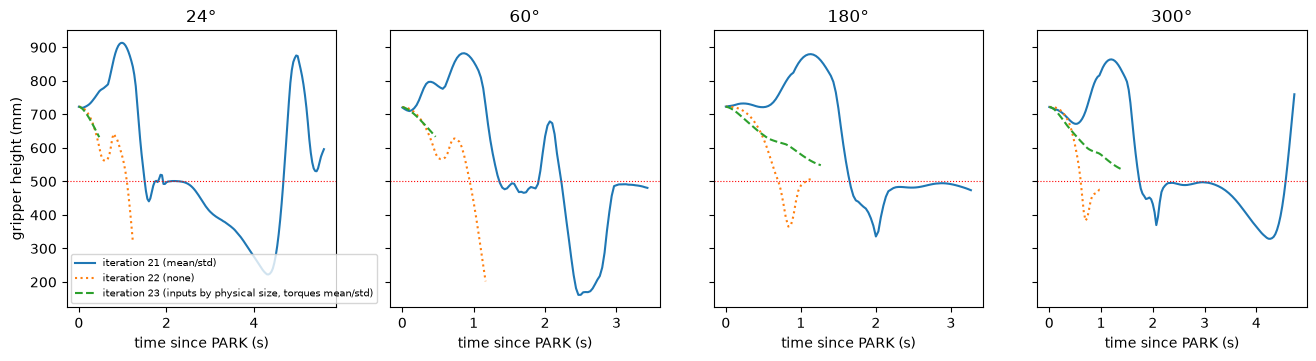

In [100]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
runs = {name: {r['bearing']: r for r in json.loads((ARM / f'results/{name}_camera.json').read_text())} for name, _, _ in SC}
for ax, b in zip(axes, (24, 60, 180, 300)):
    for (name, it, scaling), ls in zip(SC, ('-', ':', '--')):
        F = [f for f in runs[name][b]['frames'] if f['parked']]
        ax.plot([f['time_s'] - F[0]['time_s'] for f in F], [1000 * f['ee'][2] for f in F], ls, label=f'iteration {it} ({scaling})')
    ax.axhline(500, color='r', lw=0.8, ls=':'); ax.set(title=f'{b}°', xlabel='time since PARK (s)')
axes[0].set_ylabel('gripper height (mm)'); axes[0].legend(fontsize=7); plt.show()

#### Iteration 23: torque error per joint

The torque error per joint on the 4 test runs (root mean square, N m), against the spread of the expert's own torques. This is the expert's data, not the simulator test.

In [101]:
def torques(model, X):
    w = dict(np.load(ARM / f'models/{model}.npz')); X = X[:, :w['shared.0.weight'].shape[1]]
    for l in ('shared.0', 'shared.2'):
        X = np.maximum(X @ w[l + '.weight'].T + w[l + '.bias'], 0)
    return X @ w['arm.weight'].T + w['arm.bias']
test_runs = [train_arm.load_run(b, 'sample', 1000, 'distance') for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == 'test']
Xt, Tt = np.concatenate([r['X'] for r in test_runs]), np.concatenate([r['tau'] for r in test_runs])
err = {"expert's torque spread (std)": Tt.std(0)}
for name, it, _ in SC:
    err[f'iteration {it}'] = np.sqrt(((torques(name, Xt) - Tt) ** 2).mean(0))
pd.DataFrame(err, index=[f'joint {j}' for j in range(1, 8)]).T.round(2)

,joint 1,joint 2,joint 3,joint 4,joint 5,joint 6,joint 7
expert's torque spread (std),1.50,1.62,1.66,2.55,2.84,2.92,0.90
iteration 21,0.78,0.41,0.80,0.45,2.51,0.58,0.05
iteration 22,1.50,1.34,1.65,1.80,2.84,1.89,0.87
iteration 23,1.04,0.89,0.88,1.16,2.61,1.44,0.24


#### Iteration 23: loss curves

Iterations 21 and 23 standardise the torques the same way, so their losses share an axis.

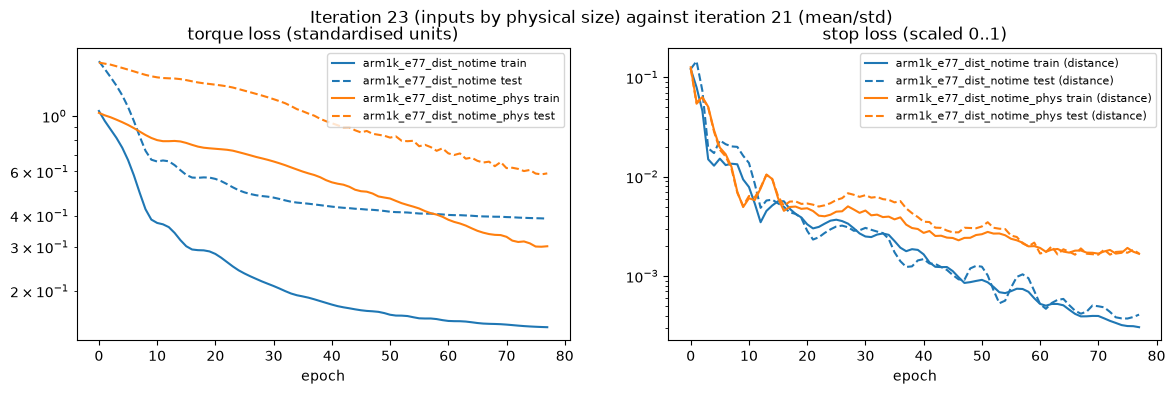

In [102]:
arm_loss_plot(['arm1k_e77_dist_notime', 'arm1k_e77_dist_notime_phys'], 'Iteration 23 (inputs by physical size) against iteration 21 (mean/std)')

#### Iteration 23: 3D replay (`arm1k_e77_dist_notime_phys`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_dist_notime_phys_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [103]:
path = replay_arm.build_viewer('arm1k_e77_dist_notime_phys_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 23: reading the results

Against the expectation:

- **As expected, the arm no longer falls through the dot with the camera.** The median closest distance is 57 mm, against 189 mm in iteration 21 and 186 mm in iteration 22, below the 100 mm the plan expected. On 9 of 25 bearings the gripper gets within 50 mm (iteration 21: 1). The height plot shows a smooth, steady move down towards the dot, with no rise and no drop.
- **The torques are calm.** 0.2% of logged torques are at the 30 N m limit, against 31% in iteration 21 and 6.5% in iteration 22.
- **The torque fit is between iterations 21 and 22,** not close to iteration 21 as expected. The test loss is 0.59 in standardised units against 0.38. Per joint, iteration 23 is better than iteration 22 everywhere, but on joints 2, 4 and 6 its error is about twice iteration 21's. The loss curves are still falling at epoch 77: with physical scaling the inputs are smaller numbers, and the network learns more slowly. The 77 epochs were chosen for standardised inputs.

What it tells us:

- The input scaling was the main reason the camera runs failed. With the inputs divided by physical sizes, the camera's 11 mm height error no longer throws the network out of its training range.
- The stop signal is now the limit. The network says stop on all 25 bearings, but a median 0.81 s after PARK and 104 mm from the dot. The expert takes about 2.3 s to get within 1 cm. When the run ends 0.5 s later, the gripper is still moving steadily towards the dot. The stop loss is 0.0017 (an average error of about 10 mm) against 0.0003 in iteration 21, so the stop head also learned less in 77 epochs.
- Next: the stop head (its own layer or its own network), and more training, with the number of epochs chosen again on the validation folds.

### Arm: the stop head (iterations 24 to 26)

Iteration 23 reaches the dot smoothly with the camera, but the stop comes too early on every bearing: a median 0.81 s after PARK and 104 mm from the dot, while the expert takes about 2.3 s to get within 1 cm. On the expert's own test runs the stop head predicts 2 to 39 mm at PARK, where the real distance is about 225 mm. At PARK the arm is still, and the only other time it is still in training is the expert's hold at the dot, where the distance is 0. Iterations 24 to 26 work on the stop head one change at a time, each keeping the changes before it.

#### Iteration 24: plan and expected results

Iteration 24 is iteration 23 with a layer of its own for the stop head:

```
17 inputs -> 64 ReLU -> 64 ReLU -+-> 7 torques
                                 +-> 16 ReLU -> distance to the dot
```

- Before, the stop head was one linear unit on the second shared layer, so it could only draw a straight line through the features the torques need. The 16-unit layer lets it bend its own way, for example to tell PARK apart from the hold at the dot. The torque loss does not reach this layer.
- Everything else as in iteration 23: 17 inputs divided by physical sizes, torques standardised, stop at 1 cm, stop loss weight 1, 1 kHz, Adam lr 0.01, 77 full-batch epochs, seed 7, 21 training bearings. Tested on the 25 bearings with the expert driving and the dot from the camera and tracker.

Expected:

- A small gain. The stop loss after 77 epochs drops a little below iteration 23's 0.0017, and the median stop moves later, from 0.81 s to between 1.0 and 1.5 s after PARK, so the gripper stops closer than 104 mm.
- The reach stays as in iteration 23 (median closest near 57 mm), since the torque part is unchanged apart from what the stop layer sends back into the shared layers.

The expectation is wrong if the median stop stays before 1.0 s after PARK. Then a separate layer alone does not help at 77 epochs, and the 5-fold check (iteration 23's settings at 600 epochs moved the first stop from a median 1.39 s to 2.25 s on held-out runs) points to training length instead.

#### Iteration 24: results

The camera test on the 25 bearings with the expert driving, against the iterations before it. A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [104]:
def camera_table(SC):
    """One row per network: the camera test on the 25 bearings (expert driving)."""
    rows = []
    for name, it in SC:
        runs = json.loads((ARM / f'results/{name}_camera.json').read_text()); r = pd.DataFrame(runs)
        stops = [x['stop_s'] - x['log'][0]['t'] for x in runs if x['stop_s']]
        rows.append({'iteration': it, 'stopped (of 25)': len(stops), 'median stop after PARK (s)': np.median(stops) if stops else None,
                     'stops in the first 0.5 s': sum(s < 0.5 for s in stops),
                     'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median closest (mm)': r.min_mm.median(),
                     'closest within 50 mm (of 25)': int((r.min_mm <= 50).sum()), 'median at expert stop (mm)': r.at_expert_stop_mm.median(),
                     'median fall after closest (mm)': np.median([gripper_fall_mm(x) for x in runs]),
                     'torques at the 30 N m limit (%)': 100 * np.mean(np.abs([l['tau'] for x in runs for l in x['log']]) >= 29.99)})
    return pd.DataFrame(rows).set_index('iteration').round(2)

def camera_plots(SC, bearings=(24, 60, 180, 300)):
    """Gripper height (top) and predicted against actual gripper-to-dot distance (bottom) after PARK, camera test."""
    runs = {name: {r['bearing']: r for r in json.loads((ARM / f'results/{name}_camera.json').read_text())} for name, _ in SC}
    fig, axes = plt.subplots(2, len(bearings), figsize=(16, 6.6), sharey='row')
    for k, b in enumerate(bearings):
        for (name, it), c in zip(SC, ('C0', 'C1', 'C2', 'C3')):
            F = [f for f in runs[name][b]['frames'] if f['parked']]; L = runs[name][b]['log']
            axes[0, k].plot([f['time_s'] - F[0]['time_s'] for f in F], [1000 * f['ee'][2] for f in F], color=c, label=f'iteration {it}')
            axes[1, k].plot([l['t'] - L[0]['t'] for l in L], [l['ee_mm'] for l in L], color=c, label=f'iteration {it}, actual')
            axes[1, k].plot([l['t'] - L[0]['t'] for l in L], [1000 * l['ttp_s'] for l in L], '--', color=c, label=f'iteration {it}, predicted')
        axes[0, k].axhline(500, color='r', lw=0.8, ls=':'); axes[0, k].set(title=f'{b}°')
        axes[1, k].axhline(10, color='r', lw=0.8, ls=':'); axes[1, k].set(xlabel='time since PARK (s)', ylim=(-50, 300))
    axes[0, 0].set_ylabel('gripper height (mm)'); axes[1, 0].set_ylabel('gripper to dot (mm)')
    axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=6); plt.show()

camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stop16', 24)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.0,0.20
24,25,0.78,12,137.78,114.83,0,154.68,0.0,0.68


#### Iteration 24: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

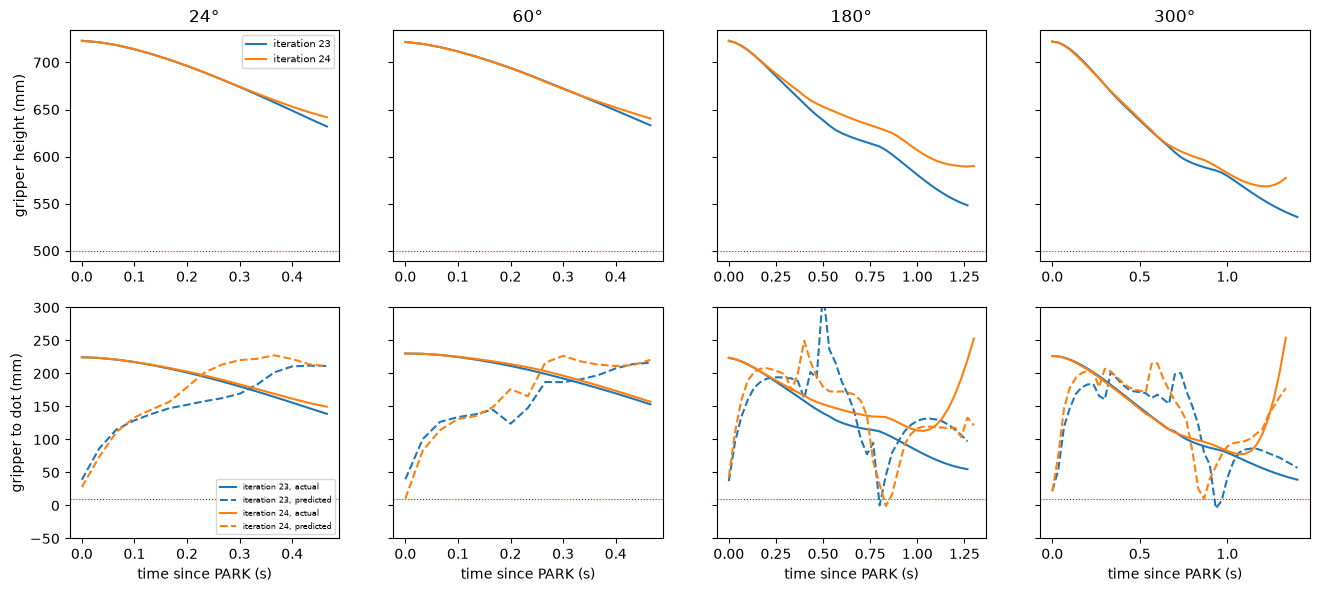

In [105]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stop16', 24)])

#### Iteration 24: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

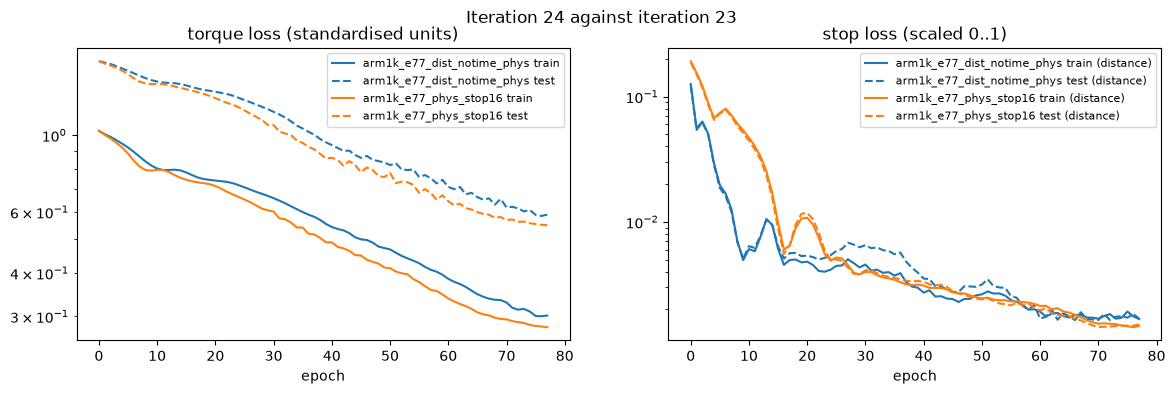

In [106]:
arm_loss_plot(['arm1k_e77_dist_notime_phys', 'arm1k_e77_phys_stop16'], 'Iteration 24 against iteration 23')

#### Iteration 24: 3D replay (`arm1k_e77_phys_stop16`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_stop16_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [107]:
path = replay_arm.build_viewer('arm1k_e77_phys_stop16_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 24: reading the results

Against the expectation:

- **Not as expected: the stop does not move later.** The median stop is 0.78 s after PARK, against 0.81 s in iteration 23, below the 1.0 s the plan set as the test. The training stop loss ends at 0.0015 against 0.0017, about the same.
- **The early stops happen at PARK itself.** On 12 of 25 bearings the network says stop within 2 ms of PARK (iteration 23: 11). At PARK the head predicts a median 40 mm (10 to 111 mm), where the real distance is about 225 mm. Where it does not stop at once, the prediction climbs towards the real distance within 0.2 s and then follows it, with dips as on bearings 180 and 300.
- **The reach looks the same; the closest distance is worse.** The gripper height follows iteration 23 closely on all four bearings plotted. The median closest is 115 mm against 57 mm, and no bearing gets within 50 mm (iteration 23: 9). The bearings where iteration 23 got close were the ones where it did not stop at PARK, and in iteration 24 those runs stop sooner after the dips.

What it tells us:

- A layer of its own does not fix the stop at 77 epochs. The problem is the PARK state, which the head still confuses with the hold at the dot, and the stop latches on a single millisecond.
- Iteration 25 keeps the layer and tunes the weight of the stop loss on the validation folds; iteration 26 trains for 300 epochs.

#### Iteration 25: plan and expected results

Iteration 25 is iteration 24 (with the stop head's own 16-unit layer) with the weight of the stop loss tuned. So far the total loss has been the torque loss plus the stop loss, each with weight 1. The torque loss is about 0.3 at the end of training and the stop loss about 0.0015, so the stop head gets a small share of the training signal through the shared layers. A larger weight gives it more.

How the weight is chosen, without the test bearings:

- Candidate weights 1, 3, 10, 30 and 100.
- For each weight, the network is trained 5 times, each time holding out one of the 5 folds of training bearings (`split_plan.json`) as validation, with the iteration 24 settings (77 epochs, seed 7).
- The chosen weight has the lowest validation stop loss, averaged over the 5 folds, among the weights whose average validation torque loss is no more than 10% above weight 1's. The losses compared are unweighted.
- Also reported, but not used to choose: on the held-out runs, how often the stop head would say stop in the first 0.5 s after PARK along the expert's own path.

Then the network is trained on all 21 training bearings with the chosen weight and tested on the 25 bearings with the expert driving and the dot from the camera and tracker.

Expected:

- The validation stop loss falls as the weight rises, and the torque loss rises a little. A weight between 10 and 30 is chosen.
- In the camera test, fewer stops at PARK: from 12 of 25 to fewer than 6, and a median stop later than 1.0 s after PARK.

The expectation is wrong if 10 or more bearings still stop in the first 0.5 s. Then the weight is not the limit at 77 epochs, and iteration 26 (300 epochs) is the next test.

#### Iteration 25: results

The 5-fold validation for each stop loss weight (iteration 24 settings, 77 epochs, seed 7). Losses are unweighted and averaged over the 5 held-out folds. The last column counts the held-out runs (21 in all) where the stop head would say stop in the first 0.5 s after PARK, replayed along the expert's own path.

In [108]:
choice = json.loads((ARM / 'results/stop_weight_choice_25.json').read_text())
t = pd.DataFrame(choice['weights']).T
t.index.name = 'stop loss weight'
t['torque loss vs weight 1'] = t.val_torque / t.val_torque.loc['1']
display(t.rename(columns={'val_torque': 'validation torque loss', 'val_stop': 'validation stop loss',
                          'early_stops': 'held-out runs stopping in the first 0.5 s', 'runs': 'held-out runs'}).round(4))
print('rule:', choice['rule'], '| allowed:', choice['allowed'], '| chosen:', choice['chosen'])

,validation torque loss,validation stop loss,held-out runs stopping in the first 0.5 s,held-out runs,torque loss vs weight 1
stop loss weight,,,,,
1,0.3706,0.0023,10.0,21.0,1.0000
3,0.4105,0.0017,9.0,21.0,1.1078
10,0.4823,0.0017,5.0,21.0,1.3015
30,0.5915,0.0016,4.0,21.0,1.5962
100,0.7734,0.0016,4.0,21.0,2.0872


rule: lowest mean validation stop loss with mean validation torque loss within 10% of weight 1 | allowed: [1] | chosen: 1


#### Iteration 25: validation loss curves

Validation losses averaged over the 5 folds, for every epoch, for each stop loss weight.

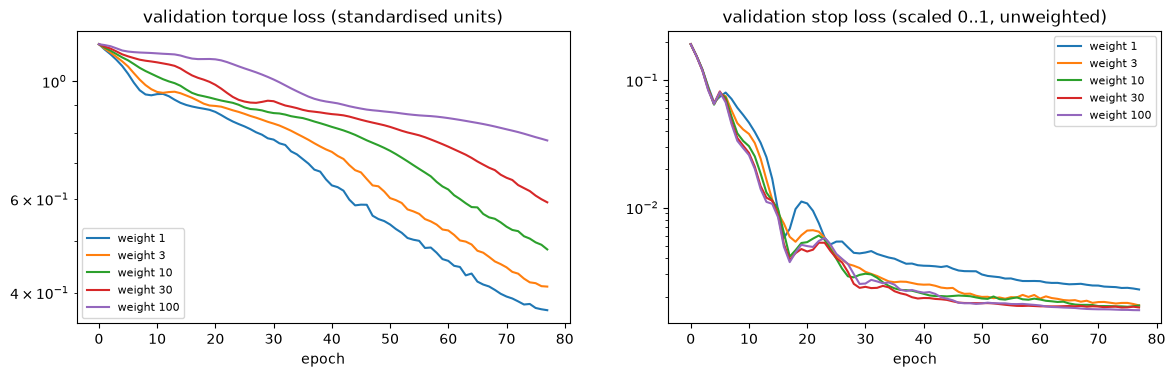

In [109]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for w in (1, 3, 10, 30, 100):
    H = [pd.DataFrame(json.loads((ARM / f'models/arm25_w{w}_fold{f}_history.json').read_text())) for f in range(5)]
    for a, k in zip(ax, ('val_torque_mse', 'val_distance_mse')):
        a.plot(H[0].epoch, np.mean([h[k] for h in H], 0), label=f'weight {w}')
for a, t in zip(ax, ('validation torque loss (standardised units)', 'validation stop loss (scaled 0..1, unweighted)')):
    a.set(yscale='log', xlabel='epoch', title=t); a.legend(fontsize=8)
plt.show()

#### Iteration 25: reading the results

Against the expectation:

- **Not as expected: the rule keeps weight 1.** A larger weight lowers the validation stop loss (0.0023 at weight 1, 0.0017 at weight 3, 0.0016 at 30 and 100), but every larger weight raises the validation torque loss by more than 10%: 11% at weight 3, 30% at 10, 60% at 30 and 109% at 100. Weight 3 misses the limit only just.
- So the network for iteration 25 is the same as iteration 24's (same settings, same seed, same weight), and it is not tested again. Its camera result is iteration 24's.

What it tells us:

- With 77 epochs the stop and the torques compete for the same two shared layers. A larger stop weight makes the head say stop at PARK on fewer held-out runs along the expert's path, from 10 of 21 at weight 1 to 4 of 21 at weights 30 and 100, but it costs torque accuracy that the reach needs.
- The validation stop losses all flatten after about 40 epochs while the torque losses are still falling at 77. Both have room to improve with longer training, which is what iteration 26 tests at weight 1.

#### Iteration 26: plan and expected results

Iteration 26 is iteration 25 (the same network as iteration 24: the stop head's own 16-unit layer, stop loss weight 1) trained for 300 epochs instead of 77.

- The 77 epochs were chosen in iteration 18 for inputs standardised by their spread, where the held-out loss turned up after 77. With inputs divided by physical sizes the network learns more slowly. A 5-fold check with iteration 23's settings (not logged as a run) found the held-out losses still falling until about 470 epochs, with no turn up: at 300 epochs the validation torque loss was 0.237 against 0.372 at 77, and the stop loss 0.0010 against 0.0018. Replayed along the expert's own paths on held-out runs, the networks trained longer said stop at PARK on 0 of 21 runs against 9 of 21.
- Everything else as in iteration 24: 17 inputs divided by physical sizes, torques standardised, stop at 1 cm, 1 kHz, Adam lr 0.01, full batch, seed 7, 21 training bearings. Tested on the 25 bearings with the expert driving and the dot from the camera and tracker.

Expected:

- Training losses well below iteration 24's: torque test loss near 0.4 (iteration 24: 0.55), stop loss near 0.001 (0.0015).
- In the camera test, few stops at PARK: from 12 of 25 to 3 or fewer. The median stop moves later than 1.5 s after PARK, and the gripper gets closer, with a median closest below iteration 23's 57 mm.

The expectation is wrong if 6 or more bearings still stop in the first 0.5 s. Then the network still confuses PARK with the hold at the dot when it drives the arm itself, even though it tells them apart along the expert's paths.

#### Iteration 26: results

The camera test on the 25 bearings with the expert driving, against the iterations before it. A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [110]:
camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stop16', 24), ('arm1k_e300_phys_stop16', 26)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.0,0.20
24,25,0.78,12,137.78,114.83,0,154.68,0.0,0.68
26,22,1.51,10,176.65,124.60,0,303.41,450.4,16.68


#### Iteration 26: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

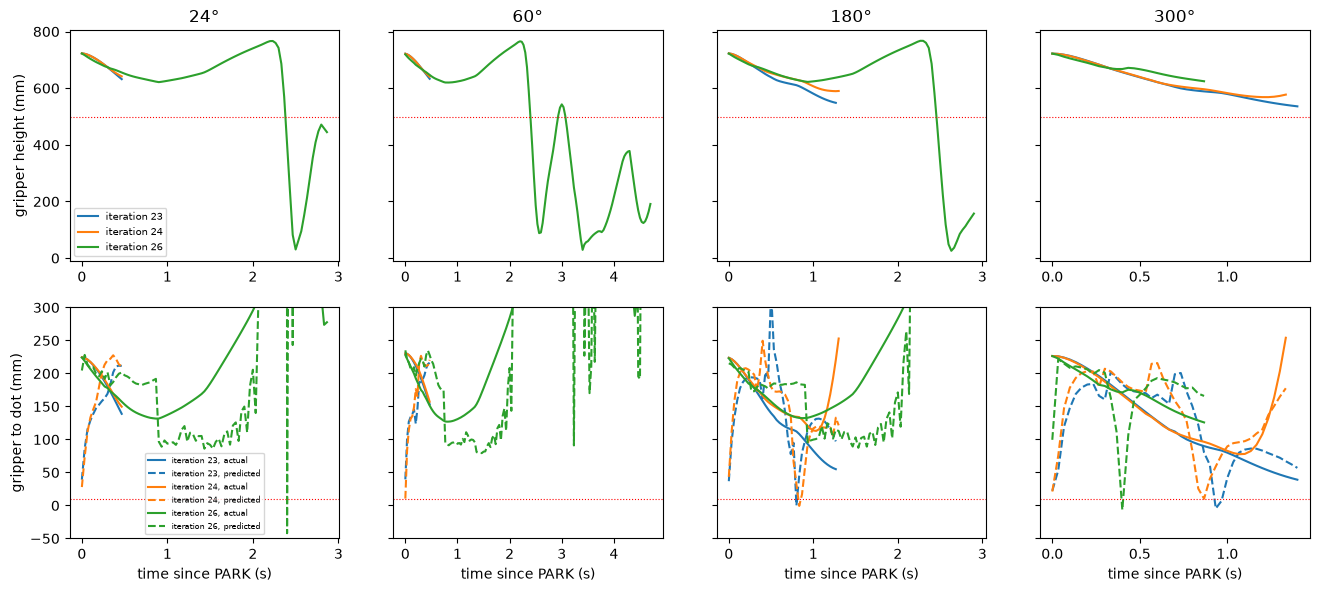

In [111]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stop16', 24), ('arm1k_e300_phys_stop16', 26)])

#### Iteration 26: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

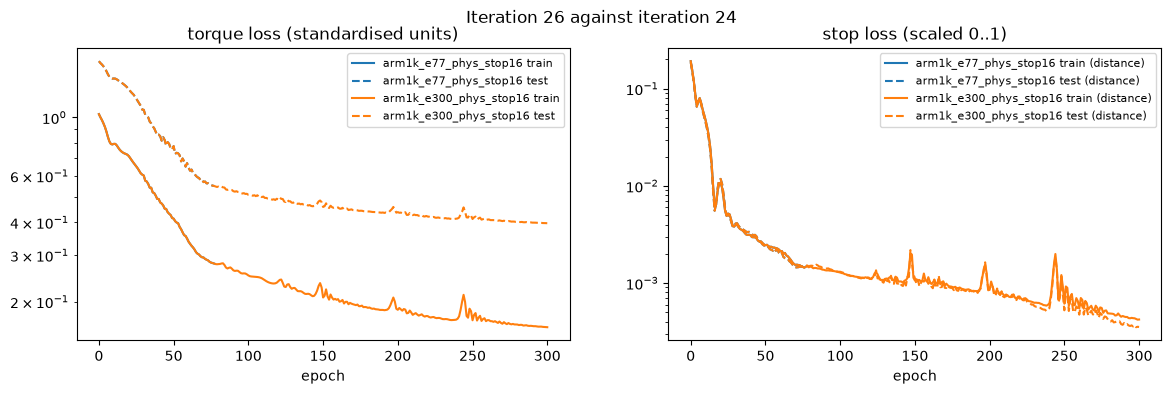

In [112]:
arm_loss_plot(['arm1k_e77_phys_stop16', 'arm1k_e300_phys_stop16'], 'Iteration 26 against iteration 24')

#### Iteration 26: 3D replay (`arm1k_e300_phys_stop16`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e300_phys_stop16_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [113]:
path = replay_arm.build_viewer('arm1k_e300_phys_stop16_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 26: reading the results

Against the expectation:

- **As expected, the training losses drop and the stop head no longer mistakes PARK for the hold.** The test torque loss is 0.40 (iteration 24: 0.55) and the stop loss 0.0004 (0.0015). At PARK the head now predicts a median 218 mm (100 to 235 mm), against 40 mm in iteration 24, where the real distance is about 225 mm. No bearing says stop at the moment of PARK.
- **Not as expected: early stops remain.** 10 of 25 bearings still stop in the first 0.5 s, all between 0.34 and 0.41 s after PARK and 168 to 177 mm from the dot. The prediction dips below 10 mm for a moment there, as on bearing 300. The plan set 6 as the test, so the expectation is wrong.
- **Not as expected: the reach is worse.** No bearing gets within 50 mm, and the median closest is 125 mm (iteration 23: 57 mm). On every bearing the gripper comes down to about 125 mm from the dot by about 0.8 s, then rises back to about 760 mm by 2.2 s and drops hard. 17% of logged torques are at the 30 N m limit, against under 1% in iterations 23 and 24. The 3 bearings that never say stop and the 12 that stop late are the ones that reach this part.

What it tells us:

- Training longer makes the network fit the expert's data better and makes it worse at driving the arm. Along the expert's own paths it is more accurate, but once it drives the arm itself the arm leaves those paths after about 0.8 s, and from there the network has nothing to go on. This is the compounding error from training only on the expert's states.
- The stop head, trained longer, does learn PARK. Its remaining dips at about 0.4 s happen during the reach, where the arm is already off the expert's path.
- Next: give the network data from the states it reaches itself, labelled with the expert's torques (DAgger), or keep fewer epochs and fix the stop separately. Iteration 23 (77 epochs, no stop layer) stays the best reach with the camera.

### Arm: three branches from iteration 23 (iterations 27 to 29)

Iteration 23 is the best arm network with the camera so far (median 57 mm from the dot, 9 of 25 within 50 mm). Iterations 27 to 29 each change one thing from iteration 23 and are independent of each other. Everything not named stays as in iteration 23: 1 kHz, torques standardised, inputs divided by physical sizes, 2×64 ReLU, Adam lr 0.01, 77 full-batch epochs, seed 7, rows from the expert's PARK to its stop, 21 training bearings. Each is tested on the 25 bearings with the expert driving and the dot from the camera and tracker.

#### Iteration 27: plan and expected results

The stop as a network of its own. Iterations 24 to 26 showed that the stop and the torques compete for the same shared layers: a larger stop weight helps the stop but costs torque accuracy (iteration 25), and longer training fixes the stop at PARK but makes the torques worse once the arm leaves the expert's paths (iteration 26).

- The torques come from iteration 23's network, unchanged (the same weights).
- The stop comes from a separate feedforward network, 17 → 32 ReLU → 16 ReLU → 1, with the same 17 inputs divided by the same physical sizes, and the same target: the expert's gripper-to-dot distance, clipped at 0.25 m and divided by 0.25 m. Stop at 1 cm, as before. No torque loss reaches it.
- Its number of epochs is chosen by 5-fold validation on the training bearings (up to 600 epochs, lowest validation stop loss averaged over the folds). The test bearings are not used.
- The two networks are saved together in one file and run together, so the test sees one network with 7 torques and a stop.

Expected:

- Until the network says stop, the arm moves exactly as in iteration 23, so any change comes from the stop alone.
- Few stops at PARK: from 11 of 25 to 2 or fewer. The median stop moves to between 1 and 2 s after PARK, and the median closest drops below 57 mm, because the bearings that stopped at PARK now get to reach.

The expectation is wrong if 5 or more bearings still stop in the first 0.5 s.

#### Iteration 28: plan and expected results

An IMU on the end effector, added to the arm encoders.

- The IMU is modelled on the Bosch BMI088, a common robot IMU: an accelerometer and a gyroscope, each with 3 axes, read every 1 ms. Typical noise from the datasheet: 175 µg/√Hz on the accelerometer and 0.014 °/s/√Hz on the gyroscope, which at 1 kHz is about 0.038 m/s² and 0.0055 rad/s of random noise per reading. Readings are clipped to the sensor's widest ranges, ±24 g and ±2000 °/s.
- The accelerometer reads the hand's acceleration minus gravity, in the hand's own frame, so at rest it reads 9.81 m/s² pointing up. The gyroscope reads the hand's rotation rate in the hand's frame.
- The readings are computed from the hand's position and rotation every 1 ms, from the robot model (the URDF) in PyBullet, the same code in training and in testing: acceleration from the change in velocity over 1 ms, rotation rate from the change in rotation over 1 ms.
- 23 inputs: the 17 of iteration 23 and the 6 IMU readings. The accelerations are divided by 9.81 m/s² and the rotation rates by 1 rad/s.

Expected:

- Little change. The IMU mostly repeats what the encoders already say: the direction of gravity in the hand's frame follows from the joint angles, and the hand's rotation rate from the joint speeds. The test torque loss stays within 10% of iteration 23's 0.59, and the camera result stays near iteration 23 (median closest between 40 and 80 mm).

The expectation is wrong if the test torque loss improves by more than 20%. Then the IMU adds information the encoders do not give, most likely the hand's acceleration.

#### Iteration 29: plan and expected results

An IMU on the end effector instead of the arm encoders.

- The same IMU as iteration 28. The 14 encoder inputs (joint angles and speeds) are removed.
- 9 inputs: the dot position (x, y, height) and the 6 IMU readings.

Expected:

- The network cannot work out the arm's pose. The IMU gives the hand's tilt against gravity (2 angles) and its rotation rate, but not the 7 joint angles, and the torque that holds the arm up depends on all of them. The test torque loss stays close to predicting each joint's average torque (about 1 in standardised units), and the arm falls: median closest above 150 mm, with a large fall after the closest point.

The expectation is wrong if the median closest is below 100 mm. Then the hand's tilt and motion carry more of the pose than expected.

#### Iteration 27: results

The camera test on the 25 bearings with the expert driving, against the iterations before it. A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [114]:
camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stopnet', 27)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.0,0.20
27,25,1.19,0,87.51,54.49,9,57.46,0.0,0.19


#### Iteration 27: the stop network's epochs

The held-out stop loss for every epoch, for each of the 5 folds of the training bearings (thin) and averaged over them (thick). The chosen number of epochs is where the average is lowest.

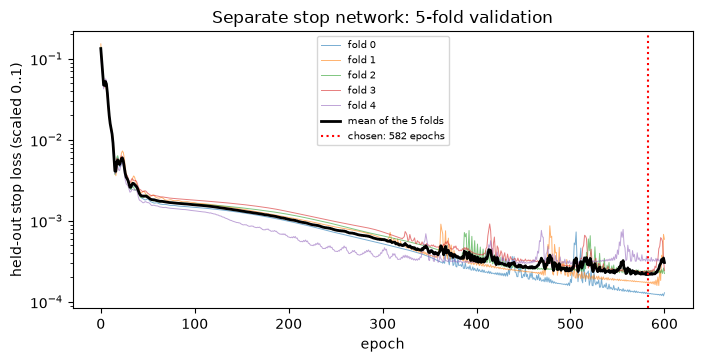

In [115]:
ch = json.loads((ARM / 'results/arm1k_e77_phys_stopnet_epoch_choice.json').read_text())
fig, ax = plt.subplots(figsize=(8, 3.6))
for f, v in enumerate(ch['fold_val']):
    ax.plot(v, lw=0.7, alpha=0.6, label=f'fold {f}')
ax.plot(ch['mean_val'], 'k', lw=2, label='mean of the 5 folds')
ax.axvline(ch['chosen'], color='r', ls=':', label=f"chosen: {ch['chosen']} epochs")
ax.set(yscale='log', xlabel='epoch', ylabel='held-out stop loss (scaled 0..1)', title='Separate stop network: 5-fold validation')
ax.legend(fontsize=7); plt.show()

#### Iteration 27: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

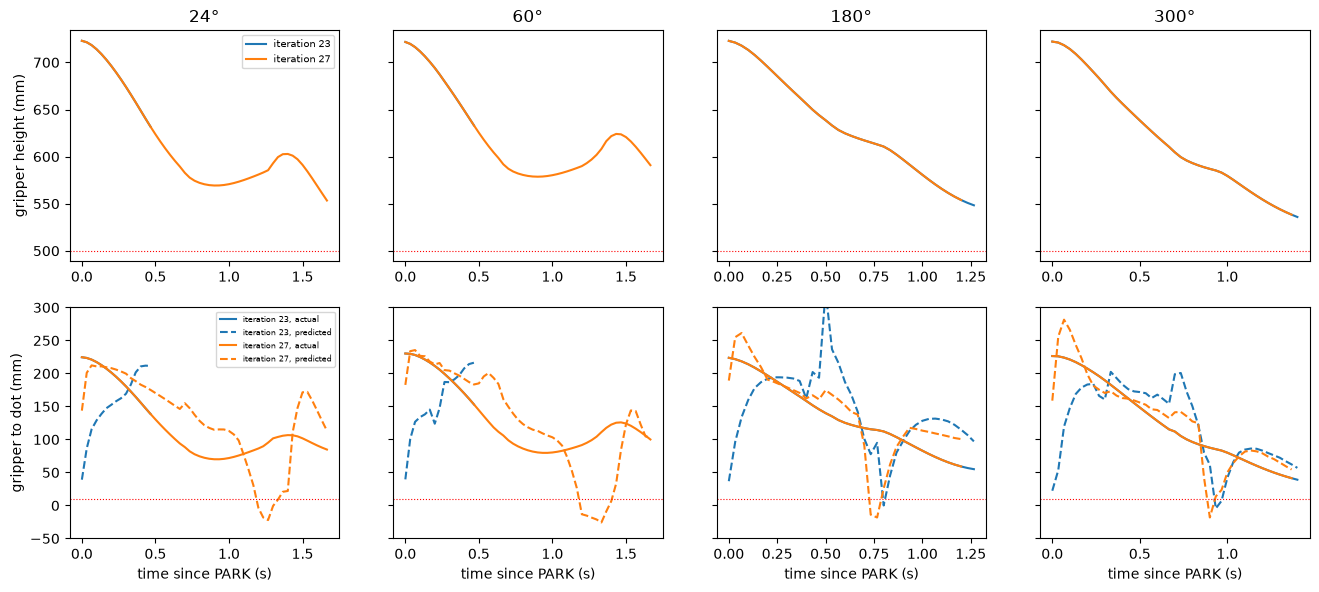

In [116]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_stopnet', 27)])

#### Iteration 27: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

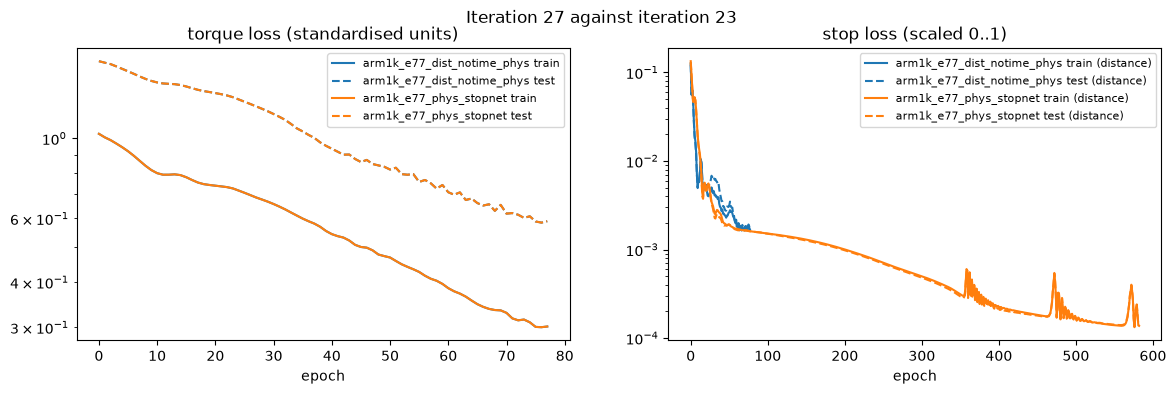

In [117]:
arm_loss_plot(['arm1k_e77_dist_notime_phys', 'arm1k_e77_phys_stopnet'], 'Iteration 27 against iteration 23')

#### Iteration 27: 3D replay (`arm1k_e77_phys_stopnet`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_stopnet_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [118]:
path = replay_arm.build_viewer('arm1k_e77_phys_stopnet_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 27: reading the results

Against the expectation:

- **As expected, the stop at PARK is gone.** No bearing says stop in the first 0.5 s, against 11 in iteration 23. At PARK the stop network predicts a median 185 mm (140 to 274 mm), where the real distance is about 225 mm. The median stop moves from 0.81 s to 1.19 s after PARK, inside the 1 to 2 s the plan expected.
- **As expected, the arm moves exactly as in iteration 23 until the stop.** The height curves lie on top of each other. The median closest is 54 mm against 57 mm, and the gripper is a median 57 mm from the dot at the expert's stop time, against 81 mm.
- **The stop still comes too early,** a median 88 mm from the dot. The validation chose 582 epochs and the stop network learned the expert's data well (test stop loss 0.00014, about 3 mm on average), but in testing its prediction dips below 10 mm when the gripper is 70 to 110 mm away, as on bearings 24 and 60 at about 1.2 s.

What it tells us:

- Separating the stop from the torques works: the stop no longer fires at PARK, and the torques are untouched.
- The remaining early stops happen where iteration 23's arm stalls short of the dot: on bearings 24 and 60 the gripper levels off about 75 mm above the dot's height and drifts back up. The expert's arm never stalls there, so the stop network has not seen these poses and reads them as close to the dot. The limit is now the reach, not the stop.

#### Iteration 28: results

The camera test on the 25 bearings with the expert driving, against the iterations before it. A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [119]:
camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_imu', 28)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.00,0.20
28,25,-0.00,13,227.13,116.16,7,160.06,2.72,4.56


#### Iteration 28: torque error per joint

The torque error per joint on the 4 test runs (root mean square, N m), on the expert's own data, against iteration 23 and the spread of the expert's torques.

In [120]:
def torques_of(model, imu):
    w = dict(np.load(ARM / f'models/{model}.npz'))
    flags = dict(imu=bool(w.get('info_imu', 0)), encoders=bool(w.get('info_encoders', 1)), time=bool(w.get('info_time', w['shared.0.weight'].shape[1] == 19)))
    runs = [train_arm.load_run(b, 'sample', 1000, 'distance', imu=imu) for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == 'test']
    X = train_arm.select_inputs(np.concatenate([r['X'] for r in runs]), **flags); T = np.concatenate([r['tau'] for r in runs])
    for l in ('shared.0', 'shared.2'):
        X = np.maximum(X @ w[l + '.weight'].T + w[l + '.bias'], 0)
    return X @ w['arm.weight'].T + w['arm.bias'], T

err = {}
for label, model, imu in (('iteration 23', 'arm1k_e77_dist_notime_phys', False), ('iteration 28', 'arm1k_e77_phys_imu', True)):
    P, T = torques_of(model, imu); err[label] = np.sqrt(((P - T) ** 2).mean(0))
err = {"expert's torque spread (std)": T.std(0), **err}
pd.DataFrame(err, index=[f'joint {j}' for j in range(1, 8)]).T.round(2)

,joint 1,joint 2,joint 3,joint 4,joint 5,joint 6,joint 7
expert's torque spread (std),1.50,1.62,1.66,2.55,2.84,2.92,0.90
iteration 23,1.04,0.89,0.88,1.16,2.61,1.44,0.24
iteration 28,0.84,0.62,0.84,0.62,2.57,0.73,0.19


#### Iteration 28: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

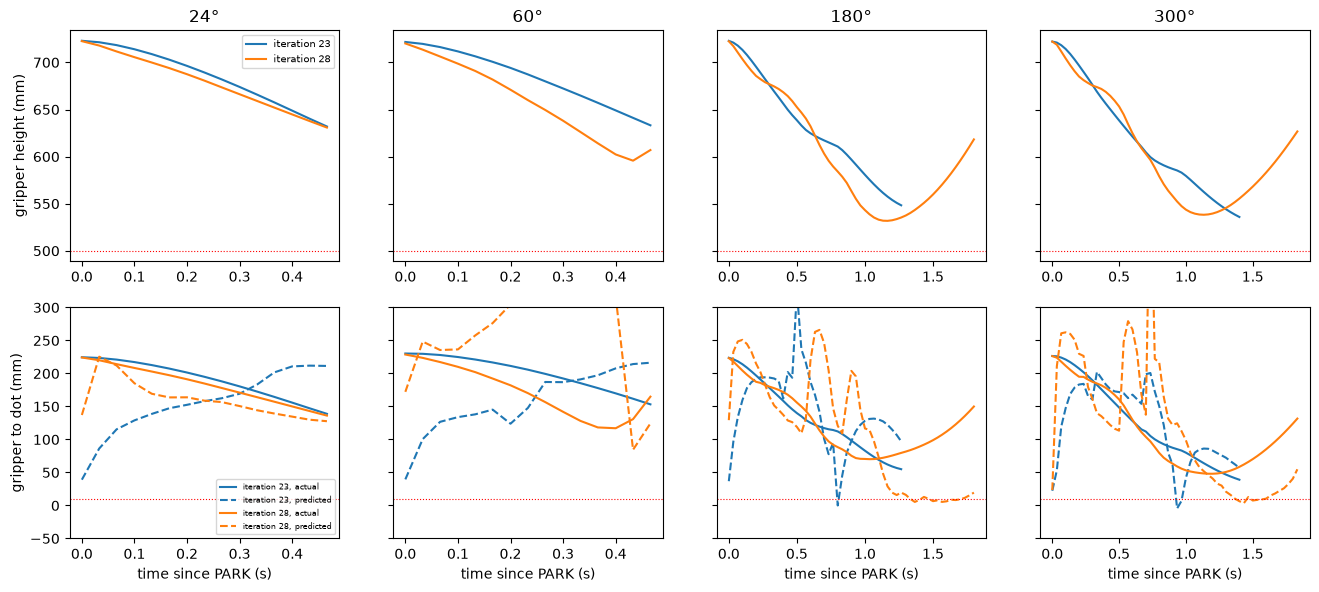

In [121]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_imu', 28)])

#### Iteration 28: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

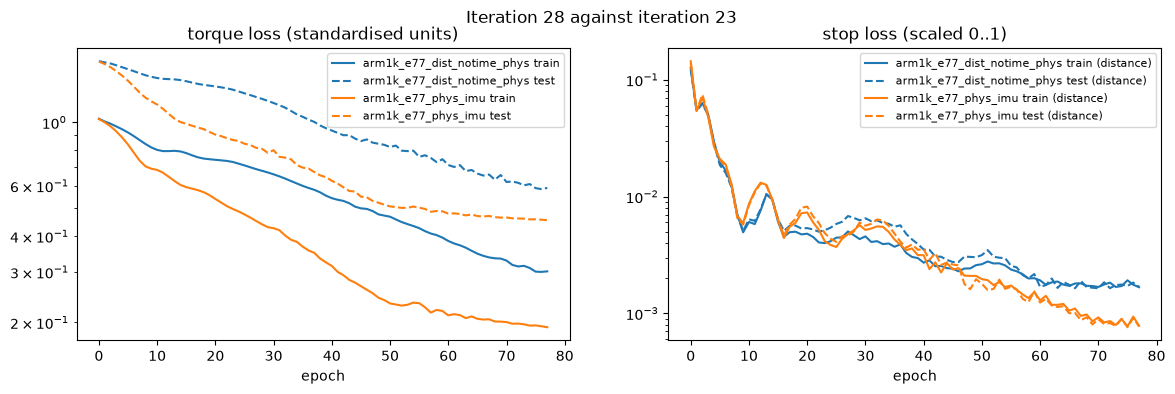

In [122]:
arm_loss_plot(['arm1k_e77_dist_notime_phys', 'arm1k_e77_phys_imu'], 'Iteration 28 against iteration 23')

#### Iteration 28: 3D replay (`arm1k_e77_phys_imu`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_imu_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [123]:
path = replay_arm.build_viewer('arm1k_e77_phys_imu_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 28: reading the results

Against the expectation:

- **Not as expected: the IMU improves the fit to the expert's data.** The test torque loss is 0.455 against 0.59, 23% lower, past the 20% the plan set as the test. Joints 2, 4 and 6 improve most: 0.62, 0.62 and 0.73 N m of error against 0.89, 1.16 and 1.44.
- **In testing the arm does worse.** 13 of 25 bearings stop in the first 0.5 s (iteration 23: 11), the median closest is 116 mm against 57 mm, and 4.6% of torques are at the 30 N m limit against 0.2%. On the bearings that run longer the gripper comes down a little faster than in iteration 23 and then rises again after about 1.1 s. 7 of 25 still get within 50 mm.
- The stop head is the shared one from iteration 23, so the stops at PARK are the same problem iteration 27 fixed.

What it tells us:

- The accelerometer reads the hand's acceleration, which the torque of the millisecond before has just caused. The expert's torque changes slowly, so the network can read its target torque partly from the IMU: the torque that produced the last acceleration. On the expert's data this is a good guess. In testing, the acceleration comes from the network's own torques, so its errors come back to it as inputs, and the torques grow.

#### Iteration 29: results

The camera test on the 25 bearings with the expert driving, against the iterations before it. A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [124]:
camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_imu_noenc', 29)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.00,0.20
29,25,0.32,18,220.80,60.65,5,747.64,349.53,23.17


#### Iteration 29: torque error per joint

The torque error per joint on the 4 test runs (root mean square, N m), on the expert's own data, against iteration 23 and the spread of the expert's torques.

In [125]:
def torques_of(model, imu):
    w = dict(np.load(ARM / f'models/{model}.npz'))
    flags = dict(imu=bool(w.get('info_imu', 0)), encoders=bool(w.get('info_encoders', 1)), time=bool(w.get('info_time', w['shared.0.weight'].shape[1] == 19)))
    runs = [train_arm.load_run(b, 'sample', 1000, 'distance', imu=imu) for b in sorted(train_arm.SPLIT) if train_arm.SPLIT[b] == 'test']
    X = train_arm.select_inputs(np.concatenate([r['X'] for r in runs]), **flags); T = np.concatenate([r['tau'] for r in runs])
    for l in ('shared.0', 'shared.2'):
        X = np.maximum(X @ w[l + '.weight'].T + w[l + '.bias'], 0)
    return X @ w['arm.weight'].T + w['arm.bias'], T

err = {}
for label, model, imu in (('iteration 23', 'arm1k_e77_dist_notime_phys', False), ('iteration 29', 'arm1k_e77_phys_imu_noenc', True)):
    P, T = torques_of(model, imu); err[label] = np.sqrt(((P - T) ** 2).mean(0))
err = {"expert's torque spread (std)": T.std(0), **err}
pd.DataFrame(err, index=[f'joint {j}' for j in range(1, 8)]).T.round(2)

,joint 1,joint 2,joint 3,joint 4,joint 5,joint 6,joint 7
expert's torque spread (std),1.50,1.62,1.66,2.55,2.84,2.92,0.90
iteration 23,1.04,0.89,0.88,1.16,2.61,1.44,0.24
iteration 29,0.87,0.90,0.87,0.88,2.58,1.03,0.21


#### Iteration 29: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

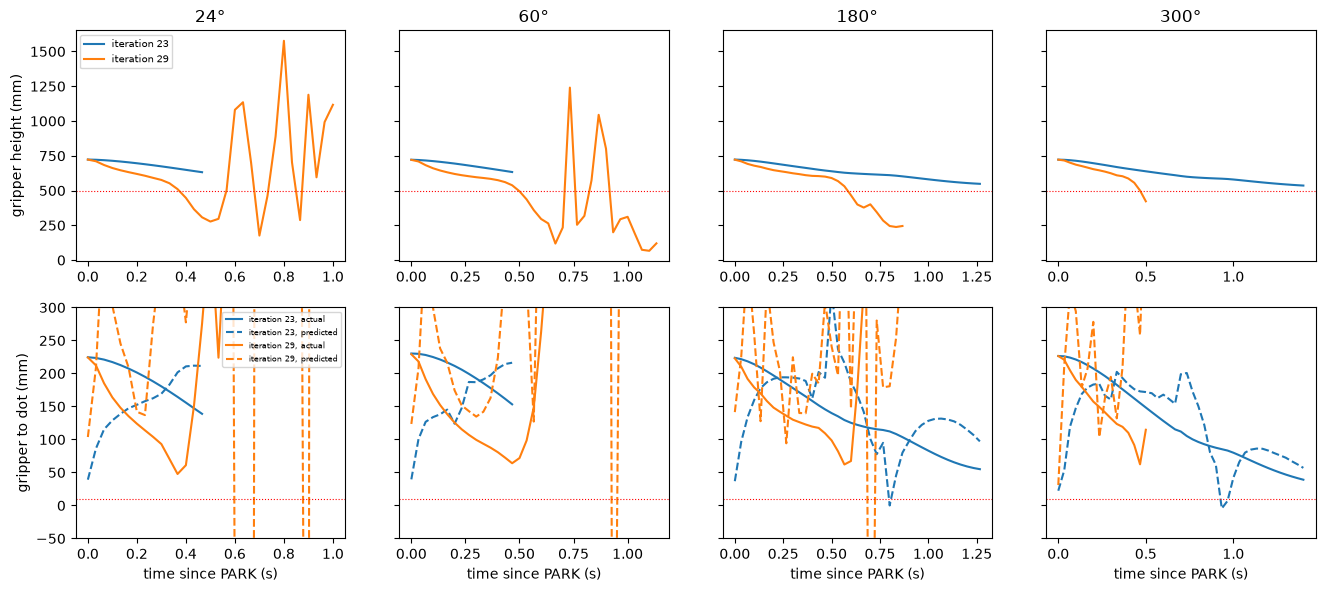

In [126]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_imu_noenc', 29)])

#### Iteration 29: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

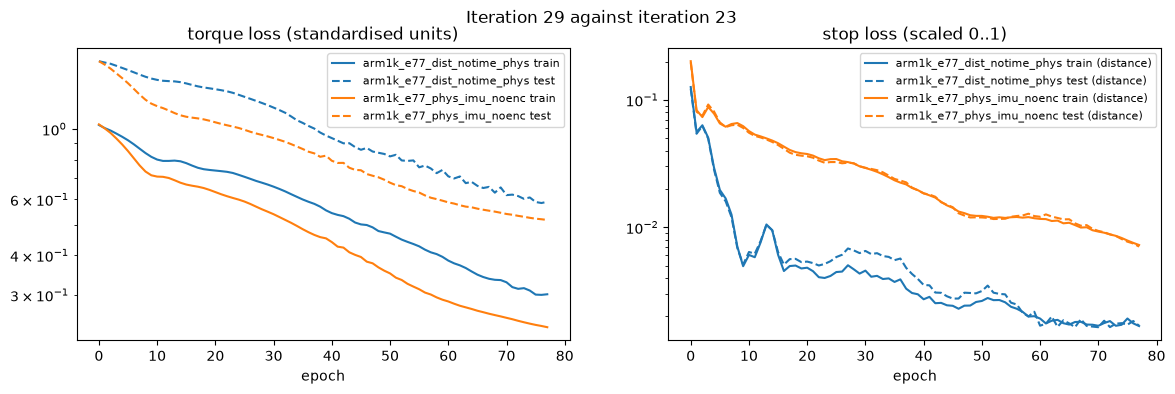

In [127]:
arm_loss_plot(['arm1k_e77_dist_notime_phys', 'arm1k_e77_phys_imu_noenc'], 'Iteration 29 against iteration 23')

#### Iteration 29: 3D replay (`arm1k_e77_phys_imu_noenc`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_imu_noenc_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [128]:
path = replay_arm.build_viewer('arm1k_e77_phys_imu_noenc_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 29: reading the results

Against the expectation:

- **The torque fit is better than expected:** a test torque loss of 0.517 without any arm encoders, better than iteration 23's 0.59, and about the same per-joint error.
- **The median closest, 61 mm, is below the 100 mm the plan set as the test, but the arm is out of control.** The gripper falls a median 350 mm after its closest point, 23% of torques are at the 30 N m limit, and the gripper passes 1.5 m from the dot on 2 bearings. It gets close to the dot only by falling through it, as the height plots show. 18 of 25 bearings say stop in the first 0.5 s.

What it tells us:

- The good fit on the expert's data comes from the same source as in iteration 28: the IMU reads the effect of the torque just before, and the expert's torque changes slowly. Without the encoders the network has nothing else to go on, and in testing its own errors come straight back as inputs.
- The IMU alone cannot replace the arm encoders. The test against the plan's 100 mm is met only by an arm falling past the dot, so the expectation holds in substance.

### New expert data: 1000 dots and the course simulator's effects (iteration 30)

All arm networks so far were trained and tested on dots 1.1 m from the robot's start and 0.5 m high, with every optional effect of the course simulator off. The fast collector can now switch on the effects the brief lists, one at a time, using the course simulator's own names and formulas: self-collision, measurement noise, measurement delay, and the motor model's damping, elasticity and inertia (inertia is commented out in the course code; here it is switched on). Each was checked against the course's Python simulator on the same dot. Self-collision, delay and inertia match exactly over the whole run. Damping and elasticity first differ by 10⁻¹⁷ and 10⁻¹⁵ N m (rounding) and end the same way, and the noise has the spread set in the config.

The new dots: 1000, drawn once with seed 0, with bearing uniform over 0 to 360°, horizontal distance uniform from 1.0 to 2.0 m and height uniform from 0.1 to 1.25 m (the range of the expert's standoff table). They are split 800 / 100 / 100 into training, validation and test dots. Every condition uses the same dots, so conditions can be compared dot by dot. Runs are capped at 30 s.

Settings, as in the course config where it gives them:

| Condition | Setting |
|---|---|
| self-collision | on (the course loads the URDF with self-collision) |
| measurement noise | 0.0001 rad on joint angles and speeds, 0.1 m on base position, 0.1 rad on base orientation |
| measurement delay | 3 steps (3 ms) |
| motor damping | coefficient 1.0 per joint |
| motor elasticity | coefficient 1.0 per joint (the course gives no value) |
| motor inertia | coefficient 0.001 per joint (about half the smallest joint inertia, 0.0021 kg m², so the course's formula stays stable) |

A pilot on 10 dots already shows the expert itself failing under three of them: with noise it reached 1 of 10 dots, with self-collision 2 of 10 (it cannot turn, so it only reaches dots ahead), and with the delay 0 of 10. The course's Python simulator does the same on the dots checked.

#### Iteration 30: plan and expected results

A test only, no training: iterations 23 and 27, unchanged, on the 100 new test dots with all effects off. The expert drives and parks, and the arm network takes over with the dot from the camera, as in every arm test.

- Iteration 23: 2×64 ReLU torque network with a shared stop head; iteration 27: the same torque network with the separate stop network.
- Both were trained on 21 runs with the dot 1.1 m away and 0.5 m high. The new dots are 1.0 to 2.0 m away and 0.1 to 1.25 m high, so this measures how far they generalise.

Expected:

- On dots near 0.5 m high (0.4 to 0.6 m), about the same as on the old bearings: median closest near 55 mm.
- On dots far from 0.5 m high, the arm reaches towards the wrong height: median closest above 150 mm. Over all 100 dots, median closest above 100 mm.

The expectation is wrong if the median closest over the 100 dots is below 80 mm. Then the networks generalise in height better than their training suggests.

#### Iteration 30: results

Iterations 23 and 27, unchanged, on the 100 new test dots, with the dot from the camera and the expert driving (all effects off), against the same networks on the 25 original bearings.

In [129]:
DOTS = json.loads((ARM / 'results/dot_cases_test_baseline.json').read_text())
def dot_table(name, label):
    runs = json.loads((ARM / f'results/{name}.json').read_text()); r = pd.DataFrame([{k: v for k, v in x.items() if k not in ('log', 'frames')} for x in runs])
    stops = [x['stop_s'] - x['log'][0]['t'] for x in runs if x['stop_s'] and x['log']]
    return {'network': label, 'runs': len(r), 'stopped': len(stops), 'stops in the first 0.5 s': sum(s < 0.5 for s in stops),
            'median closest (mm)': r.min_mm.median(), 'closest within 50 mm': int((r.min_mm <= 50).sum()),
            'median distance at stop (mm)': r.at_network_stop_mm.median(), 'median at expert stop (mm)': r.at_expert_stop_mm.median(),
            'median fall after closest (mm)': np.median([gripper_fall_mm(x) for x in runs])}
pd.DataFrame([dot_table('arm1k_e77_dist_notime_phys_camera', 'iteration 23, 25 original bearings'),
              dot_table('arm1k_e77_dist_notime_phys_camera_dots', 'iteration 23, 100 new dots'),
              dot_table('arm1k_e77_phys_stopnet_camera', 'iteration 27, 25 original bearings'),
              dot_table('arm1k_e77_phys_stopnet_camera_dots', 'iteration 27, 100 new dots')]).set_index('network').round(1)

,runs,stopped,stops in the first 0.5 s,median closest (mm),closest within 50 mm,median distance at stop (mm),median at expert stop (mm),median fall after closest (mm)
network,,,,,,,,
"iteration 23, 25 original bearings",25,25,11,56.7,9,104.4,81.0,0.0
"iteration 23, 100 new dots",100,100,66,204.6,15,225.0,252.3,8.8
"iteration 27, 25 original bearings",25,25,0,54.5,9,87.5,57.5,0.0
"iteration 27, 100 new dots",100,100,0,180.9,21,253.6,253.6,75.3


#### Iteration 30: by dot height

The closest the gripper gets to each new dot, against the dot's height and its distance from the robot's start. Both networks were trained only on dots 0.5 m high and 1.1 m away (red lines).

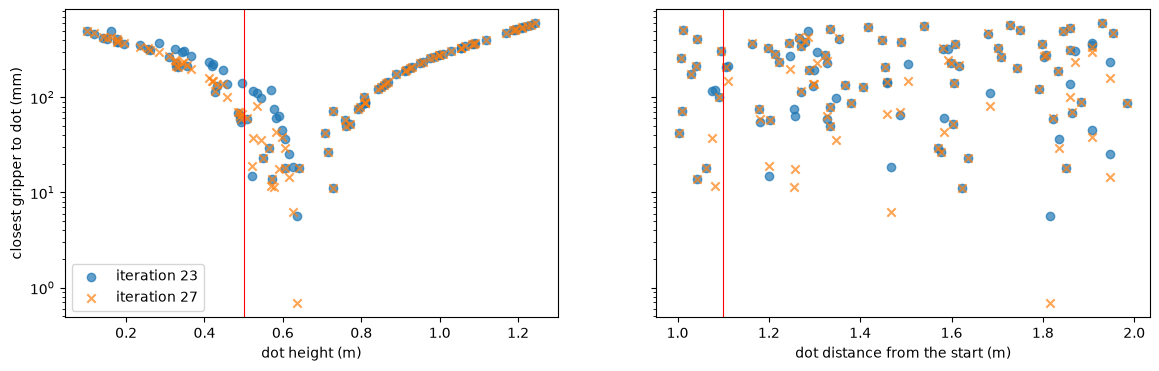

,iteration 23: median closest (mm),iteration 27: median closest (mm),dots
dot height (m),,,
"(0.1, 0.3]",379.0,393.0,13
"(0.3, 0.4]",265.0,230.0,9
"(0.4, 0.6]",76.0,61.0,25
"(0.6, 0.8]",36.0,29.0,15
"(0.8, 1.25]",276.0,276.0,38


In [130]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for name, label, mk in (('arm1k_e77_dist_notime_phys_camera_dots', 'iteration 23', 'o'), ('arm1k_e77_phys_stopnet_camera_dots', 'iteration 27', 'x')):
    runs = json.loads((ARM / f'results/{name}.json').read_text())
    h = [DOTS[str(x['bearing'])]['target'][2] for x in runs]; d = [np.hypot(*DOTS[str(x['bearing'])]['target'][:2]) for x in runs]
    c = [x['min_mm'] for x in runs]
    ax[0].scatter(h, c, marker=mk, alpha=0.7, label=label); ax[1].scatter(d, c, marker=mk, alpha=0.7, label=label)
ax[0].axvline(0.5, color='r', lw=0.8); ax[1].axvline(1.1, color='r', lw=0.8)
ax[0].set(xlabel='dot height (m)', ylabel='closest gripper to dot (mm)', yscale='log'); ax[1].set(xlabel='dot distance from the start (m)')
ax[0].legend(); plt.show()
bands = pd.cut([DOTS[str(x['bearing'])]['target'][2] for x in json.loads((ARM / 'results/arm1k_e77_phys_stopnet_camera_dots.json').read_text())], [0.1, 0.3, 0.4, 0.6, 0.8, 1.25])
t = {}
for name, label in (('arm1k_e77_dist_notime_phys_camera_dots', 'iteration 23'), ('arm1k_e77_phys_stopnet_camera_dots', 'iteration 27')):
    runs = json.loads((ARM / f'results/{name}.json').read_text())
    t[f'{label}: median closest (mm)'] = pd.Series([x['min_mm'] for x in runs]).groupby(bands, observed=False).median()
t['dots'] = pd.Series(np.ones(len(bands))).groupby(bands, observed=False).sum().astype(int)
pd.DataFrame(t).rename_axis('dot height (m)').round(0)

#### Iteration 30: the expert data under each effect

The expert's own runs on all 1000 dots under each condition (from the collection's summary), and how far iterations 23 and 27 are from the expert's commands along the expert's own paths on the 100 test dots (torque error per step, and the stop output's error against the true gripper-to-dot distance; the dot from the simulator, not the camera). The two networks share the same torque network, so their torque errors are the same. The networks' inputs come from the true joint angles, while under noise and delay the expert acted on what it measured.

In [131]:
coll = json.loads((ARM / 'results/effects_collection_summary.json').read_text())
off = json.loads((ARM / 'results/offline_dots_test.json').read_text())
rows = []
for c in ('baseline', 'damping', 'elasticity', 'inertia', 'noise', 'self_collision', 'delay'):
    s = coll.get(c, {}); o = off.get(c, {})
    rows.append({'condition': c, 'expert runs': s.get('runs'), 'expert reached': s.get('terminations', {}).get('reached', 0),
                 'expert median final distance (mm)': s.get('median_final_true_mm'), 'median run length (s)': (s.get('median_steps') or 0) / 1000,
                 'torque error, both networks (N m)': o.get('arm1k_e77_phys_stopnet', {}).get('torque_rmse_Nm'),
                 'iteration 23 stop error (mm)': o.get('arm1k_e77_dist_notime_phys', {}).get('stop_rmse_mm'),
                 'iteration 27 stop error (mm)': o.get('arm1k_e77_phys_stopnet', {}).get('stop_rmse_mm')})
pd.DataFrame(rows).set_index('condition').round(2)

,expert runs,expert reached,expert median final distance (mm),median run length (s),"torque error, both networks (N m)",iteration 23 stop error (mm),iteration 27 stop error (mm)
condition,,,,,,,
baseline,1000,997,9.99,8.55,2.43,75.07,80.84
damping,1000,995,9.99,8.51,2.46,74.99,79.80
elasticity,1000,997,9.99,8.60,2.64,77.57,78.41
inertia,1000,993,9.99,8.54,2.43,74.89,80.68
noise,1000,198,53.38,9.87,6.84,149.66,96.16
self_collision,1000,73,6979.85,30.00,20.87,101.55,278.88
delay,1000,0,11219.69,28.36,355.49,5035.75,8210.81


#### Iteration 30: 3D replay, iteration 23 on the new dots

<a href="/files/arm/results/viewer_arm1k_e77_dist_notime_phys_camera_dots.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [132]:
path = replay_arm.build_viewer('arm1k_e77_dist_notime_phys_camera_dots', expert_file=ARM / 'results/dot_cases_test_baseline.json')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 30: 3D replay, iteration 27 on the new dots

<a href="/files/arm/results/viewer_arm1k_e77_phys_stopnet_camera_dots.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [133]:
path = replay_arm.build_viewer('arm1k_e77_phys_stopnet_camera_dots', expert_file=ARM / 'results/dot_cases_test_baseline.json')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 30: reading the results

Against the expectation:

- **Over all 100 new dots the median closest is 205 mm for iteration 23 and 181 mm for iteration 27**, above the 100 mm the plan set, so the expectation holds. 15 and 21 of the 100 dots come within 50 mm.
- **On dots 0.4 to 0.6 m high, the median closest is 76 mm and 61 mm**, a little worse than the 55 mm expected. On dots at other heights it is 265 mm and 241 mm.
- **Height decides the result and distance does not.** The closest point falls in a V against the dot's height, lowest near 0.6 m and rising by about 1 mm for every millimetre the dot is above or below that. Against the dot's distance from the start there is no pattern, because the expert drives to the same standoff from every dot before the arm takes over. The networks move the gripper to about the same height whatever the camera says.
- **Iteration 27's separate stop network still never says stop in the first 0.5 s**, on all 100 new dots. Iteration 23's shared stop head does on 66 of them, more than on the original bearings (11 of 25).

The expert under each effect, on all 1000 dots:

- **With damping, elasticity and inertia switched on, the expert reaches 993 to 997 of the 1000 dots**, as without them, with the same final distance (10 mm) and run length (about 8.5 s). Both networks' torque error along the expert's paths is 2.4 to 2.6 N m under these, the same as without them.
- **Measurement noise, self-collision and delay break the expert.** With noise it reaches 198 dots and ends a median 53 mm away. With self-collision it reaches 73: it cannot turn, and on 925 dots it runs to the 30 s limit. With the 3 ms delay it reaches none, and ends a median 11 m away. Under these three, the expert's commands are not a good example to copy.

What it tells us:

- The arm networks learned one reaching height, not how to read the dot's height. Training on the 800 new training dots, which cover 0.1 to 1.25 m, is the next test of whether they can.
- Damping, elasticity and inertia at these settings change the expert's commands too little to matter, so data from them can be trained on as is. Noise, self-collision and delay need either a better expert or a decision on which runs to keep before any network is trained on them.

### Training the arm on the camera's dot (iterations 31 and 32)

Every arm network so far was trained on the simulator's exact dot position and tested with the dot from the corner camera and tracker. At PARK the camera's estimate is a median 26 mm from the true dot on the 25 original bearings (45 mm at the 90th percentile), and 11 mm off in height. The network was trained on inputs it never sees in testing. `camera_dot.py` runs the test's own pipeline along the expert's recorded runs: every 1/30 s from the start of the run to the expert's stop, it renders the corner fisheye from the recorded pose, finds the red dot, places it in the robot frame and updates the height-keeping tracker with the wheel encoders. The estimate is held between frames, as in testing. `train_arm.py --camera-dot` uses it as the dot input.

#### Iterations 31 and 32: plan and expected results

Iteration 31 is iteration 23 retrained with the camera's dot: 1 kHz, 17 inputs (7 encoder angles, 7 encoder speeds, the camera's dot x, y and height) divided by physical sizes, torques standardised, 2×64 ReLU with a shared stop head predicting the distance to the dot, 77 epochs, Adam lr 0.01, seed 7, the rows from the expert's PARK to its stop on the 21 training bearings. Iteration 32 is iteration 27 on top of it: the separate stop network (17 → 32 → 16 → 1) trained on the same camera dot, its epochs chosen by 5-fold validation on the training bearings. Both are tested on the 25 bearings with the expert driving and the dot from the camera and tracker, as every arm test.

Expected:

- The fit to the expert's torques gets a little worse: the camera's error is noise in the inputs that the expert did not react to. Test torque loss about 0.65 against 0.59 in iteration 23.
- In testing, the same or a little better: the network now meets the inputs it was trained on. Median closest 55 mm or less for iteration 31 (57 mm in iteration 23) and 50 mm or less for iteration 32 (54 mm in iteration 27), with the stop in iteration 32 a median 80 mm or less from the dot (88 mm in iteration 27).
- The expectation is wrong if either median closest is above 70 mm: then the camera's error in training costs more than the match between training and testing gains, and the arm should keep training on the exact dot.

#### Iterations 31 and 32: the camera's dot in training

How far the camera's estimate is from the true dot along the expert's recorded runs, on the rows the arm trains on (PARK to the expert's stop, 25 bearings): the error at PARK and over the whole reach, and how often the dot was in view.

In [134]:
rows = []
for b in sorted(train_arm.SPLIT):
    if train_arm.SPLIT[b] == 'holdout':
        continue
    z = np.load(ARM / f'data/camera_dot/camera_{b}.npz'); park = int(z['parking_step'])
    run = train_arm.DATA / f'run_{b // 12 - 1}'; m = json.loads((run / 'manifest.json').read_text()); base = train_arm.table(run, 'base_state')
    pos = np.c_[base['position_m_x'], base['position_m_y'], base['position_m_z']]
    yaw = train_arm.yaw_of(base['quaternion_x'], base['quaternion_y'], base['quaternion_z'], base['quaternion_w'])
    after = z['step'] >= park; steps = z['step'][after]
    true = train_arm.dot_in_robot(m['target_position_world_m'], pos[steps], yaw[steps]); est = z['est'][after]
    err = 1000 * np.linalg.norm(est - true, axis=1)
    rows.append(dict(bearing=b, split=train_arm.SPLIT[b], frames_after_park=int(after.sum()), seen_after_park=int(z['visible'][after].sum()),
                     error_at_park_mm=err[0], median_error_mm=np.nanmedian(err), max_error_mm=np.nanmax(err), height_error_at_park_mm=1000 * (est[0, 2] - true[0, 2])))
cam_err = pd.DataFrame(rows).set_index('bearing')
print(f"median error at PARK {cam_err.error_at_park_mm.median():.0f} mm, over the reach {cam_err.median_error_mm.median():.0f} mm; "
      f"dot seen on {cam_err.seen_after_park.sum()} of {cam_err.frames_after_park.sum()} frames after PARK")
cam_err.round(1)

median error at PARK 26 mm, over the reach 12 mm; dot seen on 2727 of 2751 frames after PARK


,split,frames_after_park,seen_after_park,error_at_park_mm,median_error_mm,max_error_mm,height_error_at_park_mm
bearing,,,,,,,
12,train,146,142,36.3,14.9,39.0,12.7
24,test,140,137,34.3,12.0,39.0,15.3
36,train,131,128,39.6,12.6,40.6,19.7
60,train,113,112,37.3,13.3,42.3,14.2
72,train,109,107,37.3,14.4,38.6,11.1
84,train,106,104,41.6,10.8,42.7,26.7
108,test,89,86,32.4,11.0,34.0,10.8
120,train,76,75,45.3,11.6,45.3,19.3
132,test,74,73,45.0,11.0,45.0,18.6


#### Iteration 31: results

The camera test on the 25 bearings with the expert driving, against iteration 23 (the same network trained on the exact dot). A stop in the first 0.5 s means the network said stop almost as soon as the arm started.

In [135]:
camera_table([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_camdot', 31)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
23,25,0.81,11,104.44,56.75,9,81.03,0.0,0.20
31,25,0.72,12,128.25,70.34,1,88.21,0.0,0.34


#### Iteration 31: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop head predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

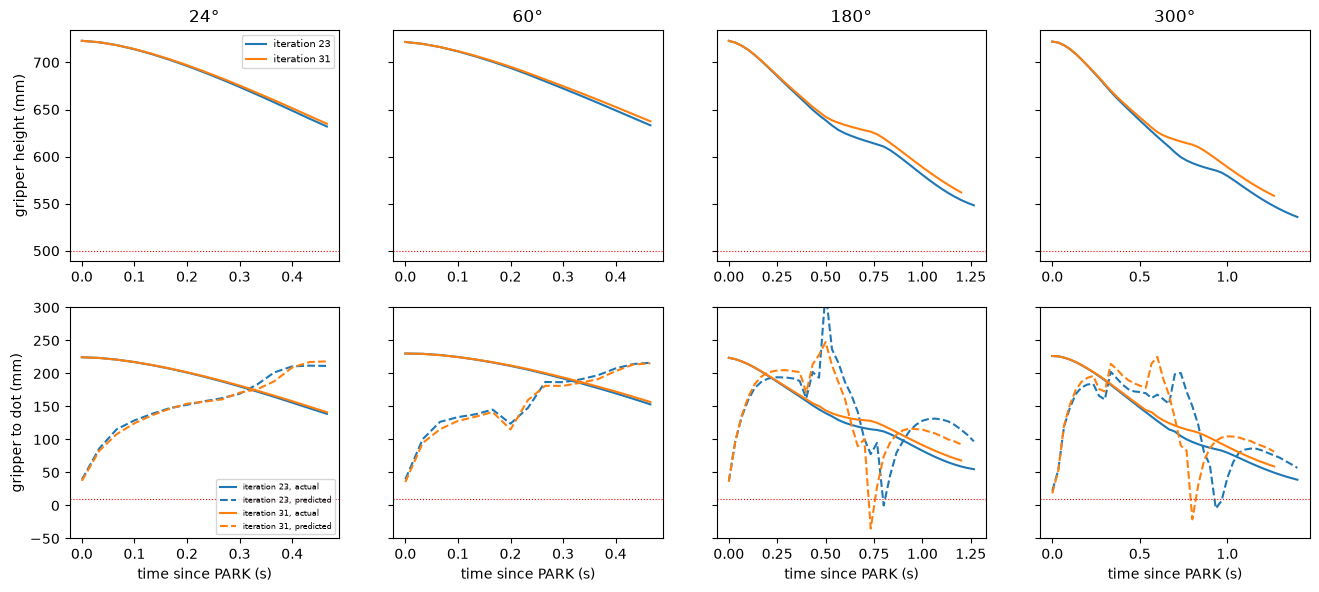

In [136]:
camera_plots([('arm1k_e77_dist_notime_phys', 23), ('arm1k_e77_phys_camdot', 31)])

#### Iteration 31: loss curves

Iteration 31 against iteration 23: the same network, trained on the camera's dot instead of the exact dot.

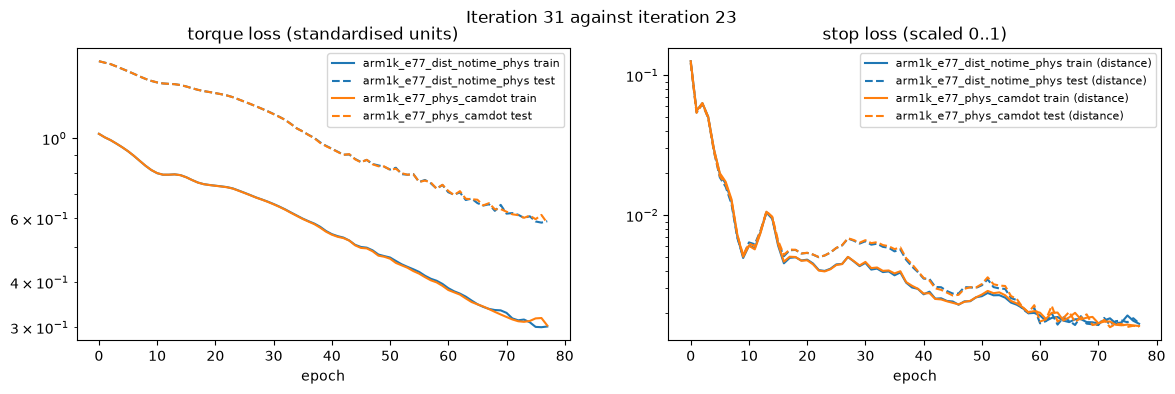

In [137]:
arm_loss_plot(['arm1k_e77_dist_notime_phys', 'arm1k_e77_phys_camdot'], 'Iteration 31 against iteration 23')

#### Iteration 31: 3D replay (`arm1k_e77_phys_camdot`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_camdot_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [138]:
path = replay_arm.build_viewer('arm1k_e77_phys_camdot_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 31: reading the results

Against the expectation:

- **The fit to the expert's torques did not get worse:** test torque loss 0.583 against 0.59 in iteration 23. The camera's error in the inputs cost nothing offline.
- **In testing the arm got worse, on every one of the 25 bearings.** Median closest 70 mm against 57 mm, 1 bearing within 50 mm against 9, and the gripper a median 88 mm from the dot at the expert's stop time against 81 mm. The difference is small, a median 8 mm per bearing, but it has the same sign on all 25, so it is not chance. 70 mm is the limit the plan set, so the expectation is wrong: training on the camera's dot cost more than it gained.
- **The shared stop head stops at PARK again,** on 12 of 25 bearings (11 in iteration 23).

What it tells us:

- The camera's error is the same in training and testing: a median 30 mm at PARK along the recorded runs against 26 mm in the test, and within a few millimetres on each bearing. So the match between training and testing inputs was real, and it did not help.
- With the exact dot, the dot input is one fixed point per run after PARK. With the camera's dot it moves by a few millimetres between frames, and the network has to explain the same torques from a moving input. On the expert's data it does so as well as before; off the expert's paths, on its own, it falls a little shorter on every bearing. One explanation is that the network leans more on the dot input and less on the encoders when the dot moves in training, and the camera's jitter in testing then moves the arm. The data here cannot separate that from other causes.
- For the arm, the exact dot in training is the better choice. The camera's error in testing is a bias of about 3 cm that the network cannot see through either way; it sets the floor on how close the gripper gets.

#### Iteration 32: results

The camera test on the 25 bearings with the expert driving, against iteration 27 (the same two networks trained on the exact dot) and iteration 31 (the same torque network with the shared stop head).

In [139]:
camera_table([('arm1k_e77_phys_stopnet', 27), ('arm1k_e77_phys_camdot', 31), ('arm1k_e77_phys_camdot_stopnet', 32)])

,stopped (of 25),median stop after PARK (s),stops in the first 0.5 s,median distance at stop (mm),median closest (mm),closest within 50 mm (of 25),median at expert stop (mm),median fall after closest (mm),torques at the 30 N m limit (%)
iteration,,,,,,,,,
27,25,1.19,0,87.51,54.49,9,57.46,0.0,0.19
31,25,0.72,12,128.25,70.34,1,88.21,0.0,0.34
32,25,0.73,0,115.02,68.01,0,72.66,0.0,0.31


#### Iteration 32: the stop network's epochs

The held-out stop loss for every epoch, for each of the 5 folds of the training bearings (thin) and averaged over them (thick). The chosen number of epochs is where the average is lowest.

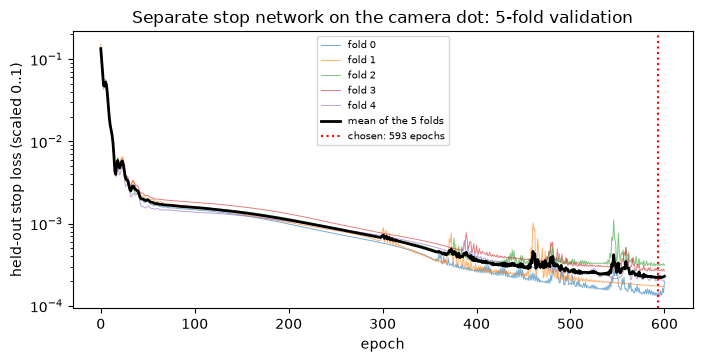

In [140]:
ch = json.loads((ARM / 'results/arm1k_e77_phys_camdot_stopnet_epoch_choice.json').read_text())
fig, ax = plt.subplots(figsize=(8, 3.6))
for f, v in enumerate(ch['fold_val']):
    ax.plot(v, lw=0.7, alpha=0.6, label=f'fold {f}')
ax.plot(ch['mean_val'], 'k', lw=2, label='mean of the 5 folds')
ax.axvline(ch['chosen'], color='r', ls=':', label=f"chosen: {ch['chosen']} epochs")
ax.set(yscale='log', xlabel='epoch', ylabel='held-out stop loss (scaled 0..1)', title='Separate stop network on the camera dot: 5-fold validation')
ax.legend(fontsize=7); plt.show()

#### Iteration 32: gripper height and the stop prediction

Top: the gripper height after PARK (the dot is at 0.5 m). Bottom: the gripper-to-dot distance the stop network predicts (dashed) against the actual distance (solid); the network says stop when the prediction first reaches 10 mm (red line). Four bearings, camera test.

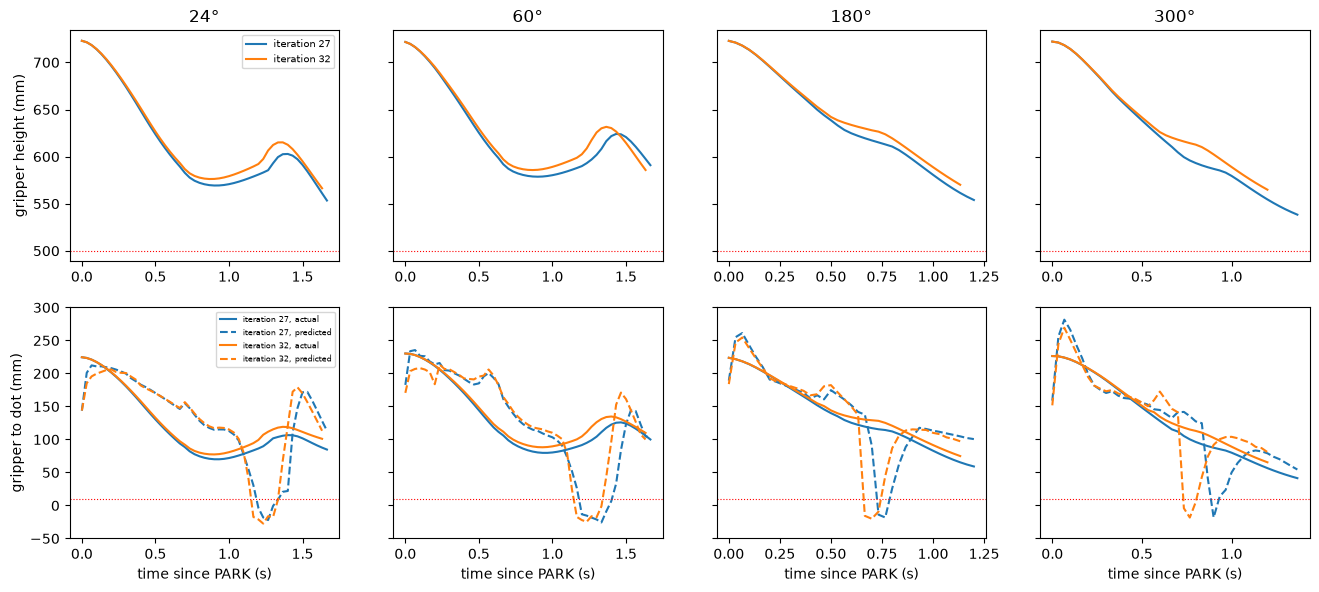

In [141]:
camera_plots([('arm1k_e77_phys_stopnet', 27), ('arm1k_e77_phys_camdot_stopnet', 32)])

#### Iteration 32: loss curves

The stop loss is shown unweighted for every network, so the curves compare directly.

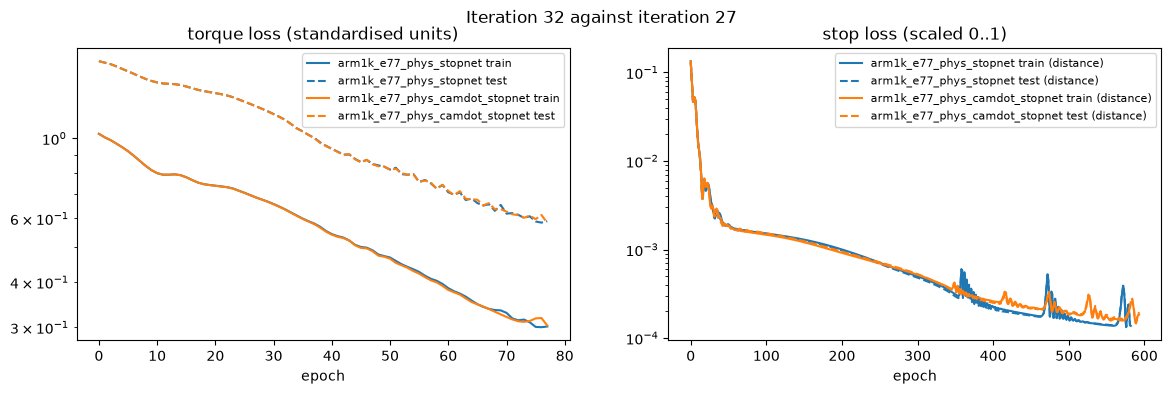

In [142]:
arm_loss_plot(['arm1k_e77_phys_stopnet', 'arm1k_e77_phys_camdot_stopnet'], 'Iteration 32 against iteration 27')

#### Iteration 32: 3D replay (`arm1k_e77_phys_camdot_stopnet`, dot from the camera)

<a href="/files/arm/results/viewer_arm1k_e77_phys_camdot_stopnet_camera.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [143]:
path = replay_arm.build_viewer('arm1k_e77_phys_camdot_stopnet_camera')
lazy_player('/files/arm/results/' + path.name)

#### Iteration 32: reading the results

Against the expectation:

- **The separate stop network still never stops at PARK**, as in iteration 27: no bearing stops in the first 0.5 s, against 12 with iteration 31's shared head on the same torque network.
- **But it stops earlier and further from the dot than iteration 27, on every bearing:** a median 0.73 s after PARK against 1.19 s, and 115 mm from the dot against 88 mm, 15 mm worse per bearing. The median closest is 68 mm against 54 mm, worse on all 25 bearings by a median 17 mm, and no bearing comes within 50 mm. The plan asked for 50 mm or less and a stop within 80 mm; the expectation is wrong.
- The validation chose 593 epochs (582 in iteration 27) and the stop network fits the expert's data a little less well (test stop loss 0.00020 against 0.00014), as the plan expected of a noisier input.

What it tells us:

- The stop network reads the camera's dot more literally than the torque network does. In training its target was the true gripper-to-dot distance while its dot input carried the camera's 30 mm bias, so it learned to predict a short distance from a biased dot. In testing the same bias is there, but the torque network's arm, now also trained on the camera's dot, approaches from a slightly different path, and the stop network's prediction reaches 10 mm sooner than before.
- Iteration 27, both networks trained on the exact dot, stays the best arm with the camera. The camera's bias in testing is better left to the networks that never saw it than trained in.
- The next gain for the arm is not the dot input. It is training on dots at many heights, which iteration 30 showed to be the limit.

### The full run: driving and reaching networks together, no expert (iteration 33)

Every arm test so far had the expert driving and parking. The brief's task is the whole run from the robot's own sensors: drive to the dot, park, reach it, stop. `arm/full_run.py` runs it: the simulator steps 1 ms at a time; every 1/30 s the corner camera is rendered, both trackers are updated and the driving network decides the wheel speeds and PARK; after its PARK the arm network runs every 1 ms with the camera's held estimate and says stop. The run ends 0.5 s after the stop, or at a time limit (the expert's park time plus 3 s, plus the expert's reach time plus 1 s). The simulator's state is used only to render the image and to log the truth.

#### Iteration 33: plan and expected results

No training. The driving network is iteration 13 (seed 7: 16 inputs from the wheel encoders and the camera, 2×16 ReLU, parks when its predicted time to park is 0.25 s or less), and the arm network is iteration 27 (iteration 23's torque network with the separate stop network, 17 inputs from the arm encoders and the camera). Both were trained on the 21 training bearings with the expert's runs. They are run together on 8 of the 25 bearings: the 4 test bearings (24, 108, 132, 204) and 4 training bearings (72, 180, 264, 348), as a first look before the 25.

What is new is the handover. Iteration 13 parked a median 7.4 cm from where the expert parks (24 of 25 parked), and the arm network has only ever started from the expert's park. Expected:

- 6 or more of the 8 bearings park, within 15 cm of the expert's park position.
- The arm reaches less well than from the expert's park: median closest about 100 mm, against 54 mm in iteration 27 with the expert driving, and 1 or 2 of 8 within 50 mm.
- The stop network still does not fire at PARK (no stop in the first 0.5 s).

The expectation is wrong if the median closest is below 60 mm (the handover does not matter) or if fewer than 6 bearings park (the driving network is the problem, not the handover).

#### Iteration 33: results

The full run on 8 bearings: iteration 13 drives and parks, iteration 27 reaches and stops, no expert. Per bearing: whether and when it parked against the expert's park time, how far from the expert's park position, and the reach from there. The last column is iteration 27 on the same bearing with the expert driving, for comparison.

In [144]:
full = json.loads((ARM / 'results/full_camera_flag_ttp_scaled_tail100_encoders_arm1k_e77_phys_stopnet.json').read_text())
ref27 = {x['bearing']: x for x in json.loads((ARM / 'results/arm1k_e77_phys_stopnet_camera.json').read_text())}
t33 = pd.DataFrame([dict(bearing=r['bearing'], split=r['split'], parked=r['parked'], park_s=r['park_s'], expert_park_s=round(r['expert_park_s'], 2),
                         park_error_cm=round(100 * r['park_error_vs_expert_m'], 1), closest_mm=r['min_mm'], stop_s=r['stop_s'],
                         at_stop_mm=r['at_network_stop_mm'], end_mm=r['end_mm'], stops_first_half_s=(r['stop_s'] is not None and r['park_s'] is not None and r['stop_s'] - r['park_s'] < 0.5),
                         iteration_27_closest_mm=ref27[r['bearing']]['min_mm']) for r in full]).set_index('bearing')
print(f"parked {int(t33.parked.sum())} of {len(t33)}; median park error {t33.park_error_cm.median():.1f} cm; median park delay {(t33.park_s - t33.expert_park_s).median():.2f} s; "
      f"median closest {t33.closest_mm.median():.0f} mm (iteration 27 with the expert driving: {t33.iteration_27_closest_mm.median():.0f} mm); within 50 mm: {int((t33.closest_mm <= 50).sum())}")
t33.round(1)

parked 8 of 8; median park error 6.3 cm; median park delay -0.08 s; median closest 101 mm (iteration 27 with the expert driving: 57 mm); within 50 mm: 0


,split,parked,park_s,expert_park_s,park_error_cm,closest_mm,stop_s,at_stop_mm,end_mm,stops_first_half_s,iteration_27_closest_mm
bearing,,,,,,,,,,,
24,test,True,5.3,3.4,5.0,131.7,6.3,154.2,234.3,False,70.0
108,test,True,6.3,5.0,5.3,101.1,7.3,110.1,126.4,False,75.2
132,test,True,6.0,5.7,8.1,80.0,6.9,119.7,80.0,False,62.2
204,test,True,5.1,6.1,9.2,100.7,6.1,145.4,100.6,False,36.5
72,train,True,6.2,4.4,5.3,66.6,8.0,69.9,72.8,False,56.5
180,train,True,5.3,6.0,7.4,121.0,6.3,156.2,120.8,False,57.5
264,train,True,4.3,4.8,5.2,87.5,5.3,118.7,87.4,False,46.5
348,train,True,2.2,3.2,7.6,119.6,3.3,134.9,206.1,False,50.3


#### Iteration 33: the reach after the network's own park

Gripper-to-dot distance from PARK on each bearing (solid), with the network's stop marked, against the same arm network starting from the expert's park (dashed, iteration 27).

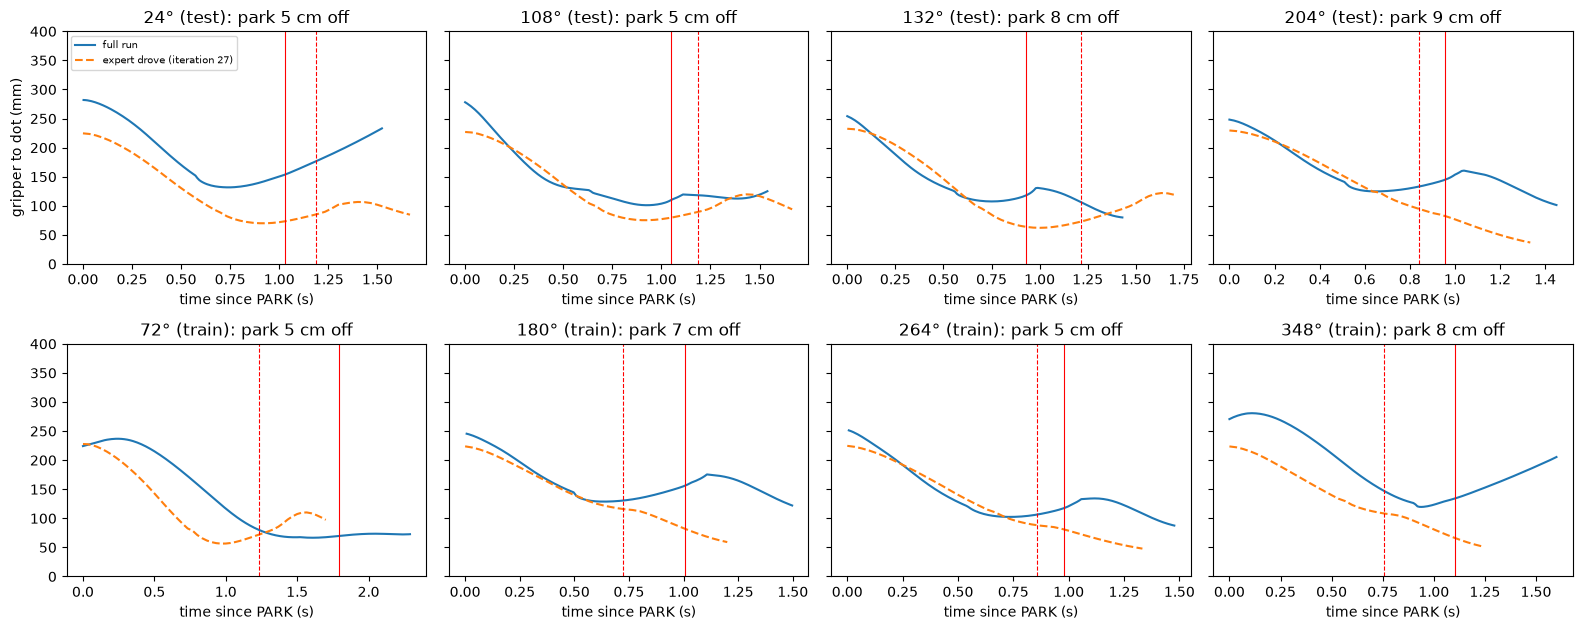

In [145]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), sharey=True)
for ax, r in zip(axes.flat, full):
    if r['park_s'] is None:
        ax.set_title(f"{r['bearing']}° ({r['split']}): never parked"); continue
    t = np.array([l['t'] for l in r['log']]) - r['park_s']; ax.plot(t, [l['ee_mm'] for l in r['log']], label='full run')
    o = ref27[r['bearing']]; t0 = o['log'][0]['t']; ax.plot([l['t'] - t0 for l in o['log']], [l['ee_mm'] for l in o['log']], '--', label='expert drove (iteration 27)')
    if r['stop_s'] is not None:
        ax.axvline(r['stop_s'] - r['park_s'], color='r', lw=0.8)
    if o['stop_s'] is not None:
        ax.axvline(o['stop_s'] - t0, color='r', lw=0.8, ls='--')
    ax.set_title(f"{r['bearing']}° ({r['split']}): park {100 * r['park_error_vs_expert_m']:.0f} cm off"); ax.set(xlabel='time since PARK (s)', ylim=(0, 400))
axes[0, 0].set_ylabel('gripper to dot (mm)'); axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

#### Iteration 33: 3D replay (`full_camera_flag_ttp_scaled_tail100_encoders_arm1k_e77_phys_stopnet`, the full run)

<a href="/files/arm/results/viewer_full_camera_flag_ttp_scaled_tail100_encoders_arm1k_e77_phys_stopnet.html" target="_blank" rel="noopener">Open this player in a separate tab</a>

In [146]:
path = replay_arm.build_viewer('full_camera_flag_ttp_scaled_tail100_encoders_arm1k_e77_phys_stopnet', full_run=True)
lazy_player('/files/arm/results/' + path.name)

#### Iteration 33: reading the results

Against the expectation:

- **All 8 bearings parked,** a median 6.3 cm from where the expert parks (5 to 9 cm), inside the 15 cm the plan allowed. The park comes within a second of the expert's time either way (median 0.08 s early).
- **The reach is worse from the network's park, as expected:** median closest 101 mm against 57 mm for the same arm network on the same bearings with the expert driving, and no bearing within 50 mm. The plan said about 100 mm and 1 or 2 within 50 mm.
- **The stop network still never fires at PARK.** Every stop comes 0.9 to 1.8 s after PARK, a median 127 mm from the dot (88 mm with the expert driving).

What it tells us:

- The handover costs about 45 mm of reach. The gripper starts 250 to 280 mm from the dot instead of 225 mm, because the base is 5 to 9 cm off the expert's park, and the arm network, trained only from the expert's park, closes the same amount of distance and no more. The curves have the same shape as with the expert driving, shifted up.
- A 6 cm park error is the driving network's number on these bearings, not a handover bug: iteration 13 parked a median 7.4 cm off on the 25 bearings. So the first gain in the full run is in the driving network's park accuracy, and the second is arm training that starts from parks spread around the expert's, which is what the imperfect-parking data would give.
- The harness works end to end from the camera and encoders alone. Every number from here on comes from it.